# Do banned bin-packing rules come back renamed? (NOV-R demo)

When a model is told *"Do not use Best Fit"*, does it stop **using** best fit, or does it only stop **naming** it?

The NOV-R experiment (artifact `art_ZkX7AmcN4vDO`) asked Qwen3 models for one-shot **online bin-packing heuristics** in
the exact FunSearch `priority(item, bins)` interface: **Qwen3-8B** without thinking (local vLLM), and **Qwen3-14B** and
**Qwen3-32B** with thinking (OpenRouter, DeepInfra fp8). It used these prompt conditions (cells):

| Cell | Prompt condition |
|---|---|
| `BASE` | task only; fixes each model's frequency order over the six textbook rules BF, FF, WF, AWF, LF, RF |
| `NAME_1` … `NAME_5` | *"Do not use X"*: cumulative name bans of the model's top-k rules (templates W1–W3) |
| `DESC_5` | the ban described in words instead of named |
| `HOLD_5` | the k = 5 ban phrased with held-out templates W4/W5 |
| `INSTR_NEW`, `INSTR_LONG` | *"Make a new algorithm."* / *"Make a fully novel algorithm never seen before … 2,000 words"* |

Every program is scored by two instruments:

* **Lexical compliance L1 (baseline):** no banned rule name or abbreviation anywhere in the extracted program.
* **Mechanistic compliance (proposed):** exact-decision agreement **< 0.95 with every banned rule** on 2,000 committed
  probe states, plus a stochastic matcher for random fit. Renaming a rule does not change its decisions, so this check
  can't be fooled by names.

**Full-run results (1,143 samples):** the renaming gap appears **only without thinking**. Qwen3-8B's k = 5 gap
(L1 − mechanistic) is +0.40 [0.21, 0.55], and at k = 1, 14 of 35 lexically clean programs are still best fit under
another name ("tightest fit", "minimum remaining space"). Qwen3-14B/32B really leave the banned rules (mechanistic
0.93–1.00). "Make a new algorithm" still returns best fit in 28/29 (14B) and 28/28 (32B) programs, and 0 of 1,143
programs beat best fit on both held-out sets.

**What this notebook runs.** Sampling needed a GPU (vLLM) and OpenRouter credit, so the demo starts from **100 recorded
responses** (a stratified random subset of the 1,143, in `mini_demo_data.json`). Everything downstream is re-run from
scratch with the **original modules**, written verbatim into `novr_demo/src/` by `%%writefile` cells:

1. **S0/S1:** regenerate every instance set from its seed and check the committed sha256, then run the harness gate.
2. **S3:** rebuild the 2,000-state probe set P10 and check its sha256.
3. **S4/S5:** probe the published-heuristic corpus and run the instrument gate on planted controls.
4. **S9:** re-evaluate the recorded responses in the sandbox (extraction, lexical flags, decisions, class, compliance,
   held-out excess) and compare every label with the full run.
5. **S10:** the pre-registered analysis (P1–P3, rename and reasoning tables) and figures F1–F6, including the MDS
   behaviour map in decision space.

The final cell compares the demo numbers with the full run. Run the cells top to bottom; with the default config
the whole notebook took 6 minutes on a 2-CPU machine. Most of that is S9, where a handful of very slow LLM-written
programs run up to the sandbox CPU limits.


In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT pre-installed on Colab, install everywhere (every original module logs with it)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib, pandas, statsmodels, requests: pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0', 'pandas==2.2.2',
         'statsmodels==0.14.6', 'requests==2.32.4')


In [2]:
from __future__ import annotations

import json
import os
import shutil
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

# method.py: ROOT = Path(__file__).resolve().parent; sys.path.insert(0, str(ROOT / "src")).
# The notebook rebuilds the artifact folder layout under ./novr_demo and imports the original modules from there.
ROOT = Path("novr_demo").resolve()
sys.path.insert(0, str(ROOT / "src"))

from loguru import logger  # noqa: E402
# method.py's `from common import setup_logging, write_json, RESULTS` follows in the import cell, once
# the modules have been written.


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-10/experiment-54/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")


In [4]:
data = load_data()
print(f"{len(data['examples'])} recorded responses:", dict(Counter(e['model_key'] for e in data['examples'])))
print("cells:", dict(Counter(e['cell'] for e in data['examples'])))
print("recorded classes:", dict(Counter(e['recorded']['label'] for e in data['examples'])))
print(f"{len(data['ext_files'])} input files (FunSearch notebook, OR-library, corpus sources); committed orders for",
      sorted(data['orders']))


GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
100 recorded responses: {'q8': 40, 'q14': 30, 'q32': 30}
cells: {'NAME_1': 18, 'NAME_5': 18, 'BASE': 10, 'INSTR_NEW': 8, 'HOLD_5': 10, 'DESC_5': 9, 'NAME_2': 7, 'NAME_3': 7, 'NAME_4': 7, 'INSTR_LONG': 6}
recorded classes: {'other': 51, 'BF': 33, 'FF': 7, 'invalid': 9}
16 input files (FunSearch notebook, OR-library, corpus sources); committed orders for ['q14', 'q32', 'q8']


## Configuration

All tunable parameters are here. **The defaults reproduce the original analysis settings** (100,000 JT
permutations, 10,000 bootstrap draws, 4 MDS restarts, the full 427-member corpus) on the 100 curated responses. The
only reduction is `RUN_SELW_QUALITY = False`: re-scoring every program on SEL-W (5 × 5,000 items) adds a few
minutes and feeds only the descriptive "quality" counts. For a quicker look, lower `N_SAMPLES` (the examples are
ordered round-robin over model × cell, so any prefix is diverse), `JT_N_PERM`, `BOOTSTRAP_B` or `MDS_N_INIT`, or raise
`CORPUS_GRID_STEP`.


In [5]:
N_SAMPLES = 100           # recorded responses to re-evaluate, out of the 100 in mini_demo_data.json (full run: 1,143)
EVAL_WORKERS = 2          # sandbox worker processes (original: NOVR_EVAL_WORKERS = 5, later 8)
CORPUS_GRID_STEP = 1      # probe every k-th member of the 351-member ab grid (original: 1, i.e. all 427 corpus members)
RUN_SELW_QUALITY = False  # score every VALID program on SEL-W for the selection fitness F (original: True)
JT_N_PERM = 100_000       # Jonckheere-Terpstra permutations per test (original: 100,000)
BOOTSTRAP_B = 10_000      # paired-bootstrap draws in the gap test (original: 10,000)
MDS_N_INIT = 4            # MDS restarts per panel of figure F3 (original: 4)

# evalq.py reads this at import: SEL-W quality runs are only queued while elapsed hours < NOVR_QUALITY_STOP_H
os.environ["NOVR_QUALITY_STOP_H"] = "5.0" if RUN_SELW_QUALITY else "-1"


## Lay out the artifact folder

The original modules read their inputs from fixed paths under the artifact root, which is two levels above each
module file:

* `ext/`: FunSearch `bin_packing.ipynb`, OR-library `binpack1-4.txt`, and the published-heuristic sources (EoH,
  ReEvo, HSEvo, MCTS-AHD, LLM4AD, arXiv 2510.27353);
* `inputs/bp9/ext_sources.json`: the URL and commit of each external file;
* `data/samples_raw_<model>.jsonl`: the recorded model responses the evaluator consumes;
* `predictions/commit2_<model>.json`: the committed banned sets B_1..B_5 and S_desc per model.

This cell writes the loaded `data` into that layout under `novr_demo/`. Everything else (instance sets, probe set,
corpus vectors, gate, evaluation rows, results, figures) is **generated** by the stages below. The folder is wiped
first, so the notebook always starts clean.


In [6]:
shutil.rmtree(ROOT, ignore_errors=True)
(ROOT / "src").mkdir(parents=True)
for rel, text in data["ext_files"].items():                      # ext/... and inputs/bp9/ext_sources.json
    p = ROOT / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(text)

examples = data["examples"][:N_SAMPLES]                           # the recorded responses to re-evaluate
(ROOT / "data").mkdir(parents=True, exist_ok=True)
for mk in ["q8", "q14", "q32"]:
    rows = [{k: v for k, v in ex.items() if k not in ("row_id", "recorded")} for ex in examples if ex["model_key"] == mk]
    with (ROOT / "data" / f"samples_raw_{mk}.jsonl").open("w") as fh:
        for r in rows:
            fh.write(json.dumps(r) + "\n")
    print(f"data/samples_raw_{mk}.jsonl: {len(rows)} responses")

(ROOT / "predictions").mkdir(parents=True, exist_ok=True)
for mk, order in data["orders"].items():                           # committed banned sets (commit #2 payloads)
    (ROOT / "predictions" / f"commit2_{mk}.json").write_text(json.dumps(order, indent=1))
    print(f"predictions/commit2_{mk}.json: B_5 = {order['B']['5']}, S_desc = {order['S_desc']}")


data/samples_raw_q8.jsonl: 40 responses
data/samples_raw_q14.jsonl: 30 responses
data/samples_raw_q32.jsonl: 30 responses
predictions/commit2_q8.json: B_5 = ['BF', 'FF', 'WF', 'AWF', 'LF'], S_desc = ['FF']
predictions/commit2_q14.json: B_5 = ['BF', 'FF', 'WF', 'AWF', 'LF'], S_desc = ['FF']
predictions/commit2_q32.json: B_5 = ['BF', 'FF', 'WF', 'AWF', 'LF'], S_desc = ['FF']


## The original modules

`method.py` is a stage CLI (`--stage s0 … s12`) over the modules in `src/`:

```
s0  setup: hardware, input hashes, OpenRouter key, smoke calls      s7  engine smoke tests (local vLLM, OpenRouter naming check)
s1  harness gate G-HARNESS (U1, U2)                                 s8  sampling orchestrator (BASE -> frequency order -> commit #2 -> ban cells)
s3  probe set P10 (U3)                                              s9  evaluation consumer (runs beside s8)
s45 corpus + instrument gate G-INSTR (U9)                           s10 analysis (P1, P2, P3, rename table, reasoning, sensitivities) + figures
s6  prompts, unit tests U4-U8/U10, commit #1                        s11 P3 audit;  s12 outputs (samples.jsonl, method_out.json)
```

The next cells write the modules this demo needs **verbatim** into `novr_demo/src/` with `%%writefile`. Long modules
are split over several cells with `%%writefile -a`, which appends. Nothing runs until the import cell after them.
The only changes make three hard-coded values configurable from the config cell: the JT permutation count and the
bootstrap draw count in `analysis.py`, and the MDS restart count in `figures.py`. Each value is now a module constant
on a line marked `# [notebook]`, and the line that used the literal uses the constant.

Modules that only serve sampling (`sample_local.py`, `sample_or.py`, `orchestrate.py`), the commit stage
(`stages_commit.py`), the P3 judges (`judges.py`, not needed with 0 candidates) and the output writer (`outputs.py`) need
a GPU, an API key or the full run's files, so they are not included.


### `src/common.py`: paths, logging, JSON I/O

Every path hangs off `ROOT` (two levels above the module file, so `novr_demo/` here): `data/`, `results/`, `predictions/`, `logs/`, `figures/`. `write_json` and `append_jsonl` write strict JSON, with non-finite floats stored as `null`. `append_jsonl` takes a file lock because the sampler (S8) and the evaluator (S9) ran as separate processes appending to the same files.

In [7]:
%%writefile novr_demo/src/common.py
#!/usr/bin/env python3
"""Shared paths, logging, JSON/JSONL I/O, the hash-chained commitment log, deviations, the OpenRouter cost ledger,
the time ledger and partial status for NOV-R (iteration 10)."""
from __future__ import annotations

import fcntl
import hashlib
import json
import math
import os
import sys
import time
from pathlib import Path
from typing import Any, Iterable

from loguru import logger

ROOT = Path(__file__).resolve().parent.parent
SRC = ROOT / "src"
DATA = ROOT / "data"
RESULTS = ROOT / "results"
PRED = ROOT / "predictions"
LOGS = ROOT / "logs"
FIGS = ROOT / "figures"
INPUTS = ROOT / "inputs"
COMMIT_LOG = PRED / "commitments.log"
GENESIS = hashlib.sha256(b"nov_r_iter10").hexdigest()
START_FILE = LOGS / "start_time.txt"
for _d in (DATA, RESULTS, PRED, LOGS, FIGS):
    _d.mkdir(parents=True, exist_ok=True)

BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
COST_CAP_USD = float(os.environ.get("NOVR_COST_CAP", "5.0"))      # artifact hard cap (plan)
NEW_CELL_CAP_USD = 4.5                                             # no new cell starts above this


def setup_logging(name: str, level: str = "INFO") -> None:
    logger.remove()
    logger.add(sys.stdout, level=level, format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOGS / f"{name}.log", rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    t = time.time()
    return time.strftime("%Y-%m-%dT%H:%M:%S", time.gmtime(t)) + f".{int((t % 1) * 1e6):06d}Z"


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _json_default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return None if not np.isfinite(o) else float(o)
        if isinstance(o, np.bool_):
            return bool(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
    except ImportError:
        pass
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, bytes):
        return o.hex()
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _clean(o: Any) -> Any:
    """Replace non-finite floats by None so the files are strict JSON."""
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {k: _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    return o


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + f".tmp{os.getpid()}")
    tmp.write_text(json.dumps(_clean(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    for ln in p.read_text().splitlines():
        ln = ln.strip()
        if not ln:
            continue
        try:
            out.append(json.loads(ln))
        except json.JSONDecodeError:
            logger.warning(f"skipping corrupt JSONL line in {p.name}")
    return out


def append_jsonl(p: Path, row: dict[str, Any]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    line = json.dumps(_clean(json.loads(json.dumps(row, default=_json_default)))) + "\n"
    with p.open("a") as fh:
        fcntl.flock(fh, fcntl.LOCK_EX)
        fh.write(line)
        fh.flush()
        fcntl.flock(fh, fcntl.LOCK_UN)


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + f".tmp{os.getpid()}")
    with tmp.open("w") as fh:
        for r in rows:
            fh.write(json.dumps(_clean(json.loads(json.dumps(r, default=_json_default)))) + "\n")
    tmp.replace(p)


def trunc(s: Any, n: int = 300) -> str:
    s = str(s)
    return s if len(s) <= n else s[:n] + f"...[+{len(s) - n}]"


Writing novr_demo/src/common.py


The rest of `common.py` covers the hash-chained commitment log (thresholds, prompts and analysis code were hash-committed before any sample), the deviation and cost ledgers, the time ledger and container hardware detection. The notebook commits nothing. These helpers are here because the stage functions call `milestone()` and `deviation()`.

In [8]:
%%writefile -a novr_demo/src/common.py


# ---------------------------------------------------------------------------------------------- commitments
def commit(payload_path: Path, label: str, note: str = "") -> dict[str, Any]:
    """Append {i, label, utc, prev_line_sha256, payload_sha256, payload_path, note} to predictions/commitments.log.
    Line 0 chains on GENESIS = sha256('nov_r_iter10'); every later line on the sha256 of the previous line's text."""
    payload_path = Path(payload_path)
    with (PRED / ".commit.lock").open("w") as lk:
        fcntl.flock(lk, fcntl.LOCK_EX)
        lines = COMMIT_LOG.read_text().splitlines() if COMMIT_LOG.exists() else []
        if any(json.loads(ln)["label"] == label for ln in lines):
            raise RuntimeError(f"commit label {label} already used; amendments need a new label")
        prev = sha256_text(lines[-1]) if lines else GENESIS
        entry = {"i": len(lines), "label": label, "utc": utc_now(), "prev_line_sha256": prev,
                 "payload_sha256": sha256_file(payload_path), "payload_path": str(payload_path.relative_to(ROOT)),
                 "note": note}
        with COMMIT_LOG.open("a") as fh:
            fh.write(json.dumps(entry, sort_keys=True) + "\n")
        fcntl.flock(lk, fcntl.LOCK_UN)
    logger.info(f"COMMIT {label}: {entry['payload_path']} sha256={entry['payload_sha256'][:16]} line {entry['i']}")
    return entry


def verify_chain() -> tuple[bool, list[str], list[dict[str, Any]]]:
    problems: list[str] = []
    if not COMMIT_LOG.exists():
        return False, ["no commitments.log"], []
    prev = GENESIS
    entries = []
    for i, ln in enumerate(COMMIT_LOG.read_text().splitlines()):
        e = json.loads(ln)
        entries.append(e)
        if e["prev_line_sha256"] != prev:
            problems.append(f"line {i}: prev-line hash mismatch")
        p = ROOT / e["payload_path"]
        if not p.exists():
            problems.append(f"line {i}: payload missing {e['payload_path']}")
        elif sha256_file(p) != e["payload_sha256"]:
            problems.append(f"line {i}: payload hash mismatch {e['payload_path']}")
        prev = sha256_text(ln)
    return (not problems, problems, entries)


def commit_time(label: str) -> str | None:
    if not COMMIT_LOG.exists():
        return None
    for ln in COMMIT_LOG.read_text().splitlines():
        e = json.loads(ln)
        if e["label"] == label:
            return e["utc"]
    return None


# ---------------------------------------------------------------------------------------------- deviations, costs
def deviation(code: str, text: str) -> None:
    p = RESULTS / "deviations.json"
    with (RESULTS / ".dev.lock").open("w") as lk:
        fcntl.flock(lk, fcntl.LOCK_EX)
        devs = json.loads(p.read_text()) if p.exists() else []
        if not any(d["code"] == code for d in devs):
            devs.append({"code": code, "text": text, "utc": utc_now(), "elapsed_h": round(elapsed_h(), 3)})
            write_json(p, devs)
            logger.warning(f"DEVIATION {code}: {text}")
        fcntl.flock(lk, fcntl.LOCK_UN)


COST_FILE = RESULTS / "costs.json"


def add_cost(purpose: str, usd: float, refused: bool = False, estimated: bool = False) -> float:
    """Running ledger shared by every process of this artifact (file-locked)."""
    with (RESULTS / ".cost.lock").open("w") as lk:
        fcntl.flock(lk, fcntl.LOCK_EX)
        c = json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {
            "total_usd": 0.0, "by_purpose": {}, "n_calls": 0, "budget_refusals": 0, "estimated_usd": 0.0}
        c["total_usd"] = round(c["total_usd"] + float(usd or 0.0), 7)
        c["by_purpose"][purpose] = round(c["by_purpose"].get(purpose, 0.0) + float(usd or 0.0), 7)
        c["n_calls"] += 1
        c["budget_refusals"] += int(refused)
        if estimated:
            c["estimated_usd"] = round(c.get("estimated_usd", 0.0) + float(usd or 0.0), 7)
        c["updated_utc"] = utc_now()
        write_json(COST_FILE, c)
        fcntl.flock(lk, fcntl.LOCK_UN)
        return c["total_usd"]


def total_cost() -> float:
    try:
        return float(read_json(COST_FILE)["total_usd"]) if COST_FILE.exists() else 0.0
    except (json.JSONDecodeError, KeyError):
        return 0.0


# ---------------------------------------------------------------------------------------------- time ledger
def start_epoch() -> float:
    try:
        s = START_FILE.read_text().split()[1]
        return time.mktime(time.strptime(s, "%Y-%m-%dT%H:%M:%SZ")) - time.timezone
    except (FileNotFoundError, IndexError, ValueError):
        return time.time()


def elapsed_h() -> float:
    return (time.time() - start_epoch()) / 3600.0


def milestone(name: str, **kw: Any) -> None:
    append_jsonl(LOGS / "time_ledger.jsonl", {"milestone": name, "utc": utc_now(), "elapsed_h": round(elapsed_h(), 3),
                                              **kw})
    logger.info(f"MILESTONE {name} at {elapsed_h():.2f} h")


def partial_status(update: dict[str, Any]) -> None:
    p = RESULTS / "partial_status.json"
    with (RESULTS / ".status.lock").open("w") as lk:
        fcntl.flock(lk, fcntl.LOCK_EX)
        st = json.loads(p.read_text()) if p.exists() else {}
        st.update(update)
        st["updated_utc"] = utc_now()
        st["elapsed_h"] = round(elapsed_h(), 3)
        write_json(p, st)
        fcntl.flock(lk, fcntl.LOCK_UN)


def timing(key: str, seconds: float, units: int, note: str = "") -> None:
    append_jsonl(RESULTS / "timing.jsonl", {"key": key, "seconds": round(seconds, 2), "units": units,
                                            "sec_per_unit": round(seconds / max(units, 1), 3), "note": note,
                                            "utc": utc_now()})


# ---------------------------------------------------------------------------------------------- hardware
def detect_cpus() -> int:
    try:
        parts = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if parts[0] != "max":
            return math.ceil(int(parts[0]) / int(parts[1]))
    except (FileNotFoundError, ValueError, IndexError):
        pass
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return math.ceil(q / p)
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def container_ram_gb() -> float | None:
    for p in ["/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"]:
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return None


Appending to novr_demo/src/common.py


### `src/bp.py`: the exact FunSearch online bin-packing harness

This copies the semantics of DeepMind's FunSearch `bin_packing.ipynb`. Bins are pre-allocated (one per item, all at full capacity). `priority(item, bins[valid])` scores every bin the item fits into, unused bins included, and the item goes to the **first** bin with the highest score. The packing score is the number of bins used. `pack_trace` also records each decision state (item, open bins that fit, number of empty bins), and those states are where the probe set comes from (S3).

In [9]:
%%writefile novr_demo/src/bp.py
#!/usr/bin/env python3
"""Exact FunSearch online bin-packing harness, instance sets, textbook/published heuristics and selection fitness.

Semantics copied from google-deepmind/funsearch bin_packing.ipynb (commit 2a2c864):
bins are pre-allocated (one per item, all at full capacity, int dtype); priority(item, bins[valid]) scores every
bin that fits (unused bins included); the item goes to valid[np.argmax(priorities)] (first index on ties, first NaN
if any NaN); score = number of bins whose remaining capacity != capacity.
"""
from __future__ import annotations

import ast
import hashlib
import json
import math
from pathlib import Path
from typing import Callable

import numpy as np

ROOT = Path(__file__).resolve().parent.parent
INST_DIR = ROOT / "data" / "instances"
EXT = ROOT / "ext"


class ShapeError(Exception):
    """Priority output is not a 1-D array with one score per valid bin."""


# ----------------------------------------------------------------------------------------------- harness
def valid(item: int, bins: np.ndarray) -> np.ndarray:
    return np.nonzero((bins - item) >= 0)[0]


def pack(items: list[int], cap: int, prio: Callable) -> int:
    """Pack `items` online with FunSearch semantics; return the number of used bins."""
    bins = np.array([cap for _ in range(len(items))])
    for it in items:
        v = np.nonzero(bins >= it)[0]  # identical to (bins - item) >= 0 for integer data
        p = np.asarray(prio(it, bins[v]))
        if p.ndim != 1 or p.shape[0] != v.shape[0]:
            raise ShapeError(f"priority returned shape {p.shape} for {v.shape[0]} valid bins")
        b = v[np.argmax(p)]
        bins[b] -= it
    return int((bins != cap).sum())


def pack_trace(items: list[int], cap: int, prio: Callable) -> tuple[int, list[tuple[int, list[int], int, int]]]:
    """Pack and record states: (item, remaining caps of opened bins that fit in index order, n_empty, chosen cap)."""
    n = len(items)
    bins = np.array([cap for _ in range(n)])
    used = np.zeros(n, dtype=bool)
    states = []
    for it in items:
        v = np.nonzero(bins >= it)[0]
        vb = bins[v]
        p = np.asarray(prio(it, vb))
        b = v[np.argmax(p)]
        opened_fit = [int(x) for x, u in zip(vb, used[v]) if u]
        n_empty = int((~used).sum())
        states.append((int(it), opened_fit, n_empty, int(bins[b])))
        bins[b] -= it
        used[b] = True
    return int(used.sum()), states


def l1(items: list[int], cap: int) -> int:
    return int(math.ceil(sum(items) / cap))


def family_excess(bins: list[int] | np.ndarray, l1s: list[int] | np.ndarray) -> float:
    """FunSearch's excess: (mean bins - mean L1) / mean L1 over a family of instances."""
    mb, ml = float(np.mean(bins)), float(np.mean(l1s))
    return (mb - ml) / ml


Writing novr_demo/src/bp.py


**Instance sets.** Families generated from fixed seeds (`SEL-OR`/`SEL-W` for selection, held-out `H-*`, the probe sources `P1SRC-*`), the OR-library `binpack1-4` files, and the two FunSearch datasets (OR3, Weibull 5k) parsed from the original notebook. In the original these files sit in `data/instances/` and `ext/`. Here `build_all_sets()` regenerates them (S0 below) and the hashes are checked.

In [10]:
%%writefile -a novr_demo/src/bp.py


# ----------------------------------------------------------------------------------------------- instances
def weibull_items(rng: np.random.Generator, n: int, shape: float = 3.0, scale: float = 45.0, hi: int = 100) -> list[int]:
    x = np.clip(np.round(rng.weibull(shape, size=n) * scale), 1, hi).astype(int)
    return [int(v) for v in x]


def uniform_items(rng: np.random.Generator, n: int, lo: int = 20, hi: int = 100) -> list[int]:
    return [int(v) for v in rng.integers(lo, hi + 1, size=n)]


def _inst(name: str, cap: int, items: list[int]) -> dict:
    return {"id": name, "capacity": int(cap), "num_items": len(items), "items": items, "l1": l1(items, cap)}


def gen_sets() -> dict[str, list[dict]]:
    """All generated instance sets (seeds fixed in the plan)."""
    s: dict[str, list[dict]] = {}
    s["SEL-OR"] = [_inst(f"selor_{i}", 150, uniform_items(np.random.default_rng(91001 + i), 120)) for i in range(20)]
    s["SEL-W"] = [_inst(f"selw_{i}", 100, weibull_items(np.random.default_rng(92001 + i), 5000)) for i in range(5)]
    s["H-W5k"] = [_inst(f"hw5k_{i}", 100, weibull_items(np.random.default_rng(93001 + i), 5000)) for i in range(5)]
    s["H-W10k"] = [_inst(f"hw10k_{i}", 100, weibull_items(np.random.default_rng(94001 + i), 10000)) for i in range(5)]
    s["H-SHIFT"] = [_inst(f"hshift_{i}", 150, weibull_items(np.random.default_rng(97001 + i), 5000, 7.0, 75.0, 150))
                    for i in range(5)]
    s["CALIB-W"] = [_inst(f"calw_{i}", 100, weibull_items(np.random.default_rng(99001 + i), 5000)) for i in range(20)]
    s["P1SRC-W"] = [_inst(f"p1w_{i}", 100, weibull_items(np.random.default_rng(95001 + i), 5000)) for i in range(5)]
    s["P1SRC-OR"] = [_inst(f"p1or_{i}", 150, uniform_items(np.random.default_rng(96001 + i), 500)) for i in range(5)]
    return s


def parse_orlib(path: Path) -> list[dict]:
    tok = path.read_text().split()
    p = int(tok[0])
    out, k = [], 1
    for _ in range(p):
        name = tok[k]
        cap, n, best = int(float(tok[k + 1])), int(tok[k + 2]), int(tok[k + 3])
        items = [int(float(x)) for x in tok[k + 4:k + 4 + n]]
        k += 4 + n
        d = _inst(name, cap, items)
        d["best_known"] = best
        out.append(d)
    return out


def funsearch_notebook() -> tuple[dict, dict, str, str]:
    """Return (OR3 dict, Weibull 5k dict, OR heuristic source, Weibull heuristic source) parsed as data."""
    nb = json.loads((EXT / "funsearch" / "bin_packing.ipynb").read_text())
    src = "".join(nb["cells"][2]["source"])
    tree = ast.parse(src)
    data = {}
    for node in tree.body:
        if isinstance(node, ast.Assign) and isinstance(node.targets[0], ast.Subscript):
            key = ast.literal_eval(node.targets[0].slice)
            data[key] = ast.literal_eval(node.value)
    or_src = "".join(nb["cells"][8]["source"]).split("\n\n\n# Test performance")[0]
    w_src = "".join(nb["cells"][9]["source"]).split("\n\n\n# Test performance")[0]
    return data["OR3"], data["Weibull 5k"], or_src, w_src


def nb_dict_to_insts(d: dict) -> list[dict]:
    return [_inst(k, v["capacity"], [int(x) for x in v["items"]]) for k, v in d.items()]


def sha_insts(insts: list[dict]) -> str:
    h = hashlib.sha256()
    for x in insts:
        h.update(json.dumps([x["id"], x["capacity"], x["items"]]).encode())
    return h.hexdigest()


def build_all_sets() -> dict[str, list[dict]]:
    sets = gen_sets()
    for i in range(1, 5):
        sets[f"H-OR{i}"] = parse_orlib(EXT / "orlib" / f"binpack{i}.txt")
    or3, w5k, _, _ = funsearch_notebook()
    sets["FS-OR3"] = nb_dict_to_insts(or3)
    sets["H-FSW5k"] = nb_dict_to_insts(w5k)
    return sets


def save_sets(sets: dict[str, list[dict]]) -> dict[str, str]:
    INST_DIR.mkdir(parents=True, exist_ok=True)
    hashes = {}
    for name, insts in sets.items():
        (INST_DIR / f"{name}.json").write_text(json.dumps(insts))
        hashes[name] = sha_insts(insts)
    return hashes


def load_set(name: str) -> list[dict]:
    return json.loads((INST_DIR / f"{name}.json").read_text())


Appending to novr_demo/src/bp.py


**Heuristics in the priority interface:** first fit (`-index`), best fit (`-(bins - item)`), worst fit, the FunSearch OR heuristic c12 (vectorised) and Weibull heuristic c14, and the ab-heuristics of Herrmann & Pallez (arXiv 2510.27353), which make up most of the novelty corpus.

In [11]:
%%writefile -a novr_demo/src/bp.py


# ----------------------------------------------------------------------------------------------- heuristics
def prio_ff(item, bins):
    return -np.arange(len(bins))


def prio_bf(item, bins):
    return -(bins - item)


def prio_wf(item, bins):
    score = (bins - item).astype(float)
    m = bins == bins.max()
    if not m.all():
        score[m] = -1e9
    return score


def prio_c12_vec(item, bins):
    """Vectorised exact equivalent of FunSearch's OR heuristic (c12)."""
    g = bins - item
    return np.select([g <= 2, g <= 3, g <= 5, g <= 7, g <= 9, g <= 12, g <= 15, g <= 18, g <= 20, g <= 21],
                     [4, 3, 2, 1, 0.9, 0.95, 0.97, 0.98, 0.98, 0.98], 0.99)


def prio_c14(item, bins):
    max_bin_cap = max(bins)
    score = (bins - max_bin_cap) ** 2 / item + bins ** 2 / (item ** 2)
    score += bins ** 2 / item ** 3
    score[bins > item] = -score[bins > item]
    score[1:] -= score[:-1]
    return score


def make_ab(a: int, b: int, base: str) -> Callable:
    """ab-heuristics of Herrmann & Pallez (arXiv 2510.27353, Algorithms 4-6); capacity = bins.max() (an unused bin
    at full capacity is always among the valid bins in the pre-allocated harness)."""
    def prio(item, bins):
        cap = bins.max()
        with np.errstate(divide="ignore", invalid="ignore"):
            first = cap - bins + 1
            if base == "FF":
                return np.where(bins <= item + a, first, np.where(bins < item + b, -2, 1))
            if base == "BF":
                return np.where(bins <= item + a, first, np.where(bins < item + b, -2.0, 1.0 / (bins - item)))
            return np.where(bins <= item + a, first, np.where(bins <= item + b, -2.0,
                                                              np.where(bins == cap, -1.0, -1.0 / (bins - item))))
    prio.__name__ = f"ab{base}_{a}_{b}"
    return prio


def ab_source(a: int, b: int, base: str) -> str:
    """Program text of an ab member in the search's program format (for probes/corpus)."""
    if base == "FF":
        tail = "np.where(bins < item + b, -2, 1)"
    elif base == "BF":
        tail = "np.where(bins < item + b, -2.0, 1.0 / (bins - item))"
    else:
        tail = "np.where(bins <= item + b, -2.0, np.where(bins == cap, -1.0, -1.0 / (bins - item)))"
    return (f"def priority(item, bins):\n    a, b = {a}, {b}\n    cap = bins.max()\n"
            f"    with np.errstate(divide='ignore', invalid='ignore'):\n"
            f"        return np.where(bins <= item + a, cap - bins + 1, {tail})\n")


SRC_FF = "def priority(item, bins):\n    return -np.arange(len(bins))\n"
SRC_BF = "def priority(item, bins):\n    return -(bins - item)\n"
SRC_WF = ("def priority(item, bins):\n    score = (bins - item).astype(float)\n    m = bins == bins.max()\n"
          "    if not m.all():\n        score[m] = -1e9\n    return score\n")


def harmonic_k(items: list[int], cap: int, k: int) -> int:
    """Lee & Lee Harmonic-k (standalone, stateful): class j<k items (cap/(j+1) < s <= cap/j) packed j per bin;
    class-k items (s <= cap/k) packed by Next Fit in their own bins."""
    count = {j: 0 for j in range(1, k)}
    bins_used = 0
    nf_rem = None
    for s in items:
        j = next((j for j in range(1, k) if s * (j + 1) > cap and s * j <= cap), k)
        if j < k:
            if count[j] == 0:
                bins_used += 1
            count[j] = (count[j] + 1) % j
        else:
            if nf_rem is None or nf_rem < s:
                bins_used += 1
                nf_rem = cap
            nf_rem -= s
    return bins_used


Appending to novr_demo/src/bp.py


**Selection fitness** F = mean of the excess over L1 relative to best fit on the 20 SEL-OR and 5 SEL-W instances (F(BF) = 1, lower is better).

In [12]:
%%writefile -a novr_demo/src/bp.py


# ----------------------------------------------------------------------------------------------- fitness
class Fitness:
    """F = 0.5*exc_OR/exc_OR(BF) + 0.5*exc_W/exc_W(BF) on the 25 selection instances (lower is better, F(BF)=1)."""

    def __init__(self, sel_or: list[dict], sel_w: list[dict], bf_or_exc: float, bf_w_exc: float):
        self.l1_or = [x["l1"] for x in sel_or]
        self.l1_w = [x["l1"] for x in sel_w]
        self.n_or = len(sel_or)
        self.bf_or_exc, self.bf_w_exc = bf_or_exc, bf_w_exc

    def parts(self, bins25: list[int]) -> tuple[float, float]:
        return family_excess(bins25[:self.n_or], self.l1_or), family_excess(bins25[self.n_or:], self.l1_w)

    def F(self, bins25: list[int]) -> float:
        eo, ew = self.parts(bins25)
        return 0.5 * eo / self.bf_or_exc + 0.5 * ew / self.bf_w_exc


def eval_set(insts: list[dict], prio: Callable) -> list[int]:
    return [pack(x["items"], x["capacity"], prio) for x in insts]


Appending to novr_demo/src/bp.py


### `src/refs.py`: the six catalogue rules the experiment bans

Best fit (BF), first fit (FF), worst fit (WF), almost-worst fit (AWF), last fit (LF) and random fit (RF), each as program text and as a function in the priority interface. Capacity is inferred as `bins.max()` (an unused full bin is always among the valid bins). The stateful hand-coded packers are for unit test U2, which checks that each priority form packs bin for bin like the textbook rule.

In [13]:
%%writefile novr_demo/src/refs.py
#!/usr/bin/env python3
"""S2 catalogue references in the FunSearch priority interface, and stateful hand-coded packers (unit test U2).

Capacity is inferred as bins.max(): an unused full bin is always among the valid bins of the pre-allocated harness,
so used = bins < bins.max(). Six textbook rules: best fit (BF), first fit (FF), worst fit (WF), almost-worst fit
(AWF: second-emptiest used bin that fits, by sorted multiset position), last fit (LF: most recently opened used bin
that fits) and random fit (RF: a uniformly random used bin that fits). Every rule opens the first unused bin when no
used bin fits. Next fit and harmonic-k need state the interface does not pass and are not expressible.
"""
from __future__ import annotations

import numpy as np

import bp

CATALOGUE = ["BF", "FF", "WF", "AWF", "LF", "RF"]
DETERMINISTIC = ["BF", "FF", "WF", "AWF", "LF"]
FALLBACK_ORDER = ["BF", "FF", "WF", "AWF", "LF", "RF"]
DISPLAY = {"BF": "Best Fit", "FF": "First Fit", "WF": "Worst Fit", "AWF": "Almost Worst Fit", "LF": "Last Fit",
           "RF": "Random Fit"}
NOT_EXPRESSIBLE = {"NF": "next fit needs the identity of the current open bin (state outside priority(item, bins))",
                   "HARMONIC_K": "harmonic-k needs item-class bookkeeping across calls (state outside the interface)"}

SRC = {
    "BF": bp.SRC_BF,
    "FF": bp.SRC_FF,
    "WF": bp.SRC_WF,
    "AWF": ("def priority(item, bins):\n"
            "    used = bins < bins.max()\n"
            "    nu = int(used.sum())\n"
            "    if nu == 0:\n"
            "        return np.zeros(len(bins))\n"
            "    if nu == 1:\n"
            "        return used.astype(float)\n"
            "    t = np.sort(bins[used])[-2]\n"
            "    return np.where(used & (bins == t), 2.0, np.where(used, 1.0, 0.0))\n"),
    "LF": ("def priority(item, bins):\n"
           "    used = bins < bins.max()\n"
           "    return np.where(used, np.arange(len(bins)), -1.0)\n"),
    "RF": ("def priority(item, bins):\n"
           "    used = bins < bins.max()\n"
           "    r = np.random.random(len(bins))\n"
           "    return np.where(used, r, -1.0)\n"),
}


def prio_awf(item, bins):
    used = bins < bins.max()
    nu = int(used.sum())
    if nu == 0:
        return np.zeros(len(bins))
    if nu == 1:
        return used.astype(float)
    t = np.sort(bins[used])[-2]
    return np.where(used & (bins == t), 2.0, np.where(used, 1.0, 0.0))


def prio_lf(item, bins):
    used = bins < bins.max()
    return np.where(used, np.arange(len(bins)), -1.0)


def prio_rf(item, bins):
    used = bins < bins.max()
    r = np.random.random(len(bins))
    return np.where(used, r, -1.0)


FUNCS = {"BF": bp.prio_bf, "FF": bp.prio_ff, "WF": bp.prio_wf, "AWF": prio_awf, "LF": prio_lf, "RF": prio_rf}


# ---------------------------------------------------------------------------------------------- hand-coded packers
def _place(rem: list[int], s: int, cap: int, choose) -> None:
    cand = [i for i, r in enumerate(rem) if r >= s]
    if not cand:
        rem.append(cap - s)
    else:
        rem[choose(cand, rem)] -= s


def hand_pack(rule: str, items: list[int], cap: int) -> int:
    """Stateful packers over an explicit list of open bins in opening order."""
    rem: list[int] = []
    for s in items:
        if rule == "FF":
            _place(rem, s, cap, lambda c, r: c[0])
        elif rule == "BF":
            _place(rem, s, cap, lambda c, r: min(c, key=lambda i: (r[i], i)))
        elif rule == "WF":
            _place(rem, s, cap, lambda c, r: min(c, key=lambda i: (-r[i], i)))
        elif rule == "AWF":
            def ch(c, r):
                if len(c) == 1:
                    return c[0]
                t = sorted((r[i] for i in c), reverse=True)[1]       # second largest of the multiset
                return next(i for i in c if r[i] == t)
            _place(rem, s, cap, ch)
        elif rule == "LF":
            _place(rem, s, cap, lambda c, r: c[-1])
        else:
            raise ValueError(rule)
    return len(rem)


def unit_test_u2() -> dict:
    """U2: priority-form FF, BF, WF, AWF and LF equal the stateful hand-coded packers bin for bin on SEL-OR,
    P1SRC-OR and one SEL-W instance."""
    out = {}
    insts = bp.load_set("SEL-OR") + bp.load_set("P1SRC-OR") + bp.load_set("SEL-W")[:1]
    for r in DETERMINISTIC:
        a = [bp.pack(x["items"], x["capacity"], FUNCS[r]) for x in insts]
        b = [hand_pack(r, x["items"], x["capacity"]) for x in insts]
        out[r] = {"equal": a == b, "n_instances": len(insts), "priority_bins_first5": a[:5],
                  "hand_bins_first5": b[:5]}
    out["passed"] = all(v["equal"] for v in out.values())
    return out


Writing novr_demo/src/refs.py


### `src/sandbox.py`: the sandbox that runs LLM-written programs

An AST screen allows only `numpy`/`math` imports and rejects dunders, `open`/`exec`/`eval` and numpy's file entry points. The program is then `exec`'d with a restricted builtins table.

In [14]:
%%writefile novr_demo/src/sandbox.py
#!/usr/bin/env python3
"""Subprocess sandbox for LLM-written priority programs: AST screen, restricted exec, CPU-time limits, persistent
workers (spawn) each capped by RLIMIT_AS, a parent watchdog that kills and respawns hung workers.

Iteration-10 changes against the BP9 copy (inputs/bp9/src/sandbox.py):
- probe sets are data/probes/P10.json (and P10r.json after a gate revision), loaded lazily, in place of P1/P2;
- HARNESS SEEDING: before probe state i under harness seed s, np.random.seed((1000003*s + i) mod 2^32); the worker
  patches np.random.default_rng, np.random.PCG64 and np.random.RandomState so that a None seed becomes that same
  value; the program is re-compiled for every harness seed with the patch active at compile time (seed value of i=0);
- during packing, np.random.seed(instance index) (and the same patch value) is set before each instance;
- per-set CPU limits (task['limits']) and a 60 s CPU limit per pass over the probe set;
- decision = int(arr[argmax(priority(item, arr.copy()))]) (remaining capacity of the chosen bin, so ties between
  equal-capacity bins are canonicalised); 65535 on any per-state error (counts as a disagreement).
"""
from __future__ import annotations

import __future__
import ast
import hashlib
import math
import multiprocessing as mp
import os
import queue
import threading
import time
from concurrent.futures import Future
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import numpy as np  # noqa: E402

ALLOWED_MODULES = {"numpy", "math"}
FORBIDDEN_NAMES = {"open", "exec", "eval", "compile", "__import__", "globals", "locals", "vars", "getattr", "setattr",
                   "delattr", "input", "breakpoint"}
# extra I/O layer (BP9, documented): numpy file/ctypes entry points
FORBIDDEN_ATTRS = {"save", "savez", "savez_compressed", "savetxt", "load", "loadtxt", "fromfile", "tofile", "memmap",
                   "genfromtxt", "fromregex", "ctypeslib", "ctypes", "DataSource", "f2py", "distutils", "testing"}
ERR_CODE = 65535
ERROR_TYPES = ("ok", "syntax", "forbidden", "runtime", "shape", "timeout", "memory")
SEED_MULT = 1000003
PROBE_CPU_LIMIT_S = 60.0


class Forbidden(Exception):
    pass


class CpuTimeout(Exception):
    pass


def screen(tree: ast.AST) -> None:
    """Reject imports other than numpy/math, forbidden names and any dunder attribute or name."""
    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            for a in node.names:
                parts = a.name.split(".")
                if parts[0] not in ALLOWED_MODULES or any(p in FORBIDDEN_ATTRS or p.startswith("__") for p in parts):
                    raise Forbidden(f"import {a.name}")
        elif isinstance(node, ast.ImportFrom):
            parts = (node.module or "").split(".")
            if parts[0] not in ALLOWED_MODULES or node.level or any(p in FORBIDDEN_ATTRS for p in parts):
                raise Forbidden(f"from {node.module} import")
            for a in node.names:
                if a.name in FORBIDDEN_ATTRS or a.name in FORBIDDEN_NAMES or a.name.startswith("__"):
                    raise Forbidden(f"from {node.module} import {a.name}")
        elif isinstance(node, ast.Name):
            if node.id in FORBIDDEN_NAMES or (node.id.startswith("__") and node.id.endswith("__")):
                raise Forbidden(f"name {node.id}")
        elif isinstance(node, ast.Attribute):
            if node.attr.startswith("__") or node.attr in FORBIDDEN_ATTRS:
                raise Forbidden(f"attribute {node.attr}")


def _restricted_import(name, globals=None, locals=None, fromlist=(), level=0):  # noqa: A002
    if level or name.split(".")[0] not in ALLOWED_MODULES:
        raise ImportError(f"import of {name} not allowed")
    return __import__(name, globals, locals, fromlist, level)


def _noop(*_a, **_k):
    return None


_SAFE = ["abs", "all", "any", "bool", "dict", "divmod", "enumerate", "filter", "float", "frozenset", "int",
         "isinstance", "iter", "len", "list", "map", "max", "min", "next", "pow", "range", "reversed", "round", "set",
         "slice", "sorted", "str", "sum", "tuple", "zip", "complex", "hash", "Exception", "ValueError", "TypeError",
         "ZeroDivisionError", "IndexError", "KeyError", "ArithmeticError", "OverflowError", "FloatingPointError",
         "RuntimeError", "StopIteration", "AssertionError", "NotImplementedError", "True", "False", "None",
         "object", "property", "staticmethod", "classmethod", "super", "type", "callable", "repr", "format", "ord",
         "chr", "hex", "bin", "oct", "id"]


def safe_builtins() -> dict:
    import builtins
    d = {k: getattr(builtins, k) for k in _SAFE if hasattr(builtins, k)}
    d["print"] = _noop
    d["__import__"] = _restricted_import
    d["__build_class__"] = builtins.__build_class__  # class definitions (helper classes in LLM programs)
    return d


def normalise_key(code: str) -> str | None:
    """sha256 of ast.dump of the program with docstrings removed (comments are dropped by ast)."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)) and node.body:
            b0 = node.body[0]
            if isinstance(b0, ast.Expr) and isinstance(getattr(b0, "value", None), ast.Constant) \
                    and isinstance(b0.value.value, str):
                node.body = node.body[1:] or [ast.Pass()]
    return hashlib.sha256(ast.dump(tree, annotate_fields=False, include_attributes=False).encode()).hexdigest()


Writing novr_demo/src/sandbox.py


**Harness seeding.** Before probe state *i* under harness seed *s*, numpy's global RNG and every *unseeded* generator (`default_rng()`, `PCG64()`, `RandomState()`) get the value (1000003·s + i) mod 2³². Randomised programs are reproducible, and comparing seeds 0 and 1 shows whether a program is stochastic. A program's **decision** on a state is the remaining capacity of the bin it picks (ties between equal-capacity bins are canonicalised; 65535 = error).

In [15]:
%%writefile -a novr_demo/src/sandbox.py


# ------------------------------------------------------------------------------------------------ RNG patch
_CUR_SEED = [0]
_ORIG = {"default_rng": np.random.default_rng, "PCG64": np.random.PCG64, "RandomState": np.random.RandomState}


def _p_default_rng(seed=None, *a, **k):
    return _ORIG["default_rng"](_CUR_SEED[0] if seed is None else seed, *a, **k)


class _PatchedPCG64(_ORIG["PCG64"]):
    """PCG64 whose None seed becomes the current harness value (a type, so numpy's isinstance checks still work)."""

    def __init__(self, seed=None):
        super().__init__(_CUR_SEED[0] if seed is None else seed)


class _PatchedRandomState(_ORIG["RandomState"]):
    def __init__(self, seed=None):
        super().__init__(_CUR_SEED[0] if seed is None else seed)


def install_rng_patch() -> None:
    np.random.default_rng = _p_default_rng
    np.random.PCG64 = _PatchedPCG64
    np.random.RandomState = _PatchedRandomState


def harness_seed(value: int) -> None:
    """Seed numpy's global RandomState and the None-seed patch with the same value."""
    v = int(value) % (2 ** 32)
    _CUR_SEED[0] = v
    np.random.seed(v)


def state_seed(s: int, i: int) -> int:
    return (SEED_MULT * int(s) + int(i)) % (2 ** 32)


def compile_program(code: str):
    """Return (priority function, error_type, message)."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError) as e:  # TabError/IndentationError are SyntaxError subclasses
        return None, "syntax", repr(e)[:300]
    try:
        screen(tree)
    except Forbidden as e:
        return None, "forbidden", str(e)[:300]
    ns = {"np": np, "math": math, "__builtins__": safe_builtins(), "__name__": "program"}
    try:
        # annotations are never evaluated (PEP 563 flag), so a dropped 'typing' import cannot break a definition
        exec(compile(tree, "<program>", "exec", flags=__future__.annotations.compiler_flag, dont_inherit=True),
             ns)  # noqa: S102 - screened, restricted namespace, rlimited worker
    except SyntaxError as e:
        return None, "syntax", repr(e)[:300]
    except MemoryError:
        return None, "memory", "MemoryError at definition"
    except CpuTimeout:
        raise
    except Exception as e:  # noqa: BLE001
        return None, "runtime", repr(e)[:300]
    fn = ns.get("priority")
    if not callable(fn):
        return None, "syntax", "no function named priority"
    return fn, "ok", ""


Appending to novr_demo/src/sandbox.py


**Worker side.** Each worker is a *spawned* process capped at a 2 GiB address space, with file writes disabled and CPU-time alarms (SIGPROF). It evaluates the requested instance sets (fail-fast), then the probe set under each harness seed.

In [16]:
%%writefile -a novr_demo/src/sandbox.py


# ------------------------------------------------------------------------------------------------ worker side
def _on_sigprof(signum, frame):
    raise CpuTimeout("cpu time limit")


def _classify(e: BaseException) -> str:
    from bp import ShapeError
    if isinstance(e, CpuTimeout):
        return "timeout"
    if isinstance(e, MemoryError):
        return "memory"
    if isinstance(e, ShapeError):
        return "shape"
    return "runtime"


def _probe_decisions(fn, states: list[tuple[int, np.ndarray]], seed: int | None = None) -> np.ndarray:
    """Decision vector of fn on the probe states; with `seed`, harness seeding before every state."""
    out = np.full(len(states), ERR_CODE, dtype=np.uint16)
    for i, (item, arr) in enumerate(states):
        if seed is not None:
            harness_seed(state_seed(seed, i))
        try:
            p = np.asarray(fn(item, arr.copy()))
            if p.ndim != 1 or p.shape[0] != arr.shape[0]:
                continue
            out[i] = int(arr[int(np.argmax(p))])
        except CpuTimeout:
            raise
        except MemoryError:
            raise
        except Exception:  # noqa: BLE001 - per-state errors are recorded as ERR
            continue
    return out


def probe_with_seed(code: str, states: list[tuple[int, np.ndarray]], seed: int,
                    cpu_limit: float | None = None) -> tuple[np.ndarray | None, str]:
    """Compile `code` afresh under harness seed `seed` (patch active at compile time) and probe every state.
    Returns (decisions or None, error message). Used in-worker and, for trusted code, in-process."""
    import signal
    harness_seed(state_seed(seed, 0))
    use_timer = cpu_limit is not None and threading.current_thread() is threading.main_thread()
    try:
        if use_timer:
            signal.setitimer(signal.ITIMER_PROF, float(cpu_limit))
        fn, et, msg = compile_program(code)
        if fn is None:
            return None, f"{et}: {msg}"
        dec = _probe_decisions(fn, states, seed)
        return dec, ""
    except CpuTimeout:
        return None, "timeout"
    except MemoryError:
        return None, "memory"
    finally:
        if use_timer:
            signal.setitimer(signal.ITIMER_PROF, 0)


def _load_probe(path: Path) -> list[tuple[int, np.ndarray]]:
    import json
    if not path.exists():
        return []
    d = json.loads(path.read_text())
    return [(int(it), np.array(list(of) + [int(cap)] * int(ne))) for it, of, ne, cap in d["states"]]


def _worker_main(conn, root: str, as_bytes: int) -> None:
    import resource
    import signal
    import sys
    import warnings
    sys.path.insert(0, str(Path(root) / "src"))
    resource.setrlimit(resource.RLIMIT_AS, (as_bytes, as_bytes))
    resource.setrlimit(resource.RLIMIT_FSIZE, (0, 0))
    warnings.simplefilter("ignore")
    np.seterr(all="ignore")
    signal.signal(signal.SIGPROF, _on_sigprof)
    install_rng_patch()
    import bp
    sets_cache: dict[str, list[dict]] = {}
    probe_cache: dict[str, list[tuple[int, np.ndarray]]] = {}

    def get_set(name):
        if name not in sets_cache:
            sets_cache[name] = bp.load_set(name)
        return sets_cache[name]

    def get_probe(name):
        if name not in probe_cache or not probe_cache[name]:
            probe_cache[name] = _load_probe(Path(root) / "data" / "probes" / f"{name}.json")
        return probe_cache[name]

    conn.send({"ready": True})
    while True:
        try:
            task = conn.recv()
        except (EOFError, KeyboardInterrupt):
            return
        if task is None:
            return
        res = {"tid": task["tid"], "error_type": "ok", "msg": "", "bins": {}, "eval_s": 0.0, "probes": {},
               "set_s": {}}
        t0 = time.process_time()
        harness_seed(0)
        try:
            signal.setitimer(signal.ITIMER_PROF, 20.0)
            fn, et, msg = compile_program(task["code"])
        except CpuTimeout:
            fn, et, msg = None, "timeout", "definition exceeded 20 s CPU"
        finally:
            signal.setitimer(signal.ITIMER_PROF, 0)
        if fn is None:
            res.update(error_type=et, msg=msg)
            conn.send(res)
            continue
        # ---- evaluation on instance sets (fail fast, in the given order); np.random.seed(instance index) first
        limits = task.get("limits", {})
        for set_name in task.get("sets", []):
            insts = get_set(set_name)
            try:
                signal.setitimer(signal.ITIMER_PROF, float(limits.get(set_name, task.get("limit", 30.0))))
                ts = time.process_time()
                out_b = []
                for idx, x in enumerate(insts):
                    harness_seed(idx)
                    out_b.append(bp.pack(x["items"], x["capacity"], fn))
                res["bins"][set_name] = out_b
                res["set_s"][set_name] = time.process_time() - ts
            except BaseException as e:  # noqa: BLE001 - classify every failure of untrusted code
                signal.setitimer(signal.ITIMER_PROF, 0)
                if isinstance(e, KeyboardInterrupt):
                    raise
                res["error_type"] = _classify(e)
                res["msg"] = f"{set_name}: {e!r}"[:300]
                res["failed_set"] = set_name
                if task.get("fail_fast", True):
                    break
            finally:
                signal.setitimer(signal.ITIMER_PROF, 0)
        res["eval_s"] = time.process_time() - t0
        # ---- behaviour probes under harness seeds (only for programs valid on all requested sets)
        if (res["error_type"] == "ok" or task.get("probe_even_if_failed")) and task.get("probes"):
            for pname in task["probes"]:
                states = get_probe(pname)
                for s in task.get("probe_seeds", [0, 1]):
                    key = f"{pname}@{s}"
                    tp = time.process_time()
                    dec, err = probe_with_seed(task["code"], states, s, cpu_limit=float(
                        task.get("probe_limit", PROBE_CPU_LIMIT_S)))
                    res.setdefault("probe_s", {})[key] = time.process_time() - tp
                    res["probes"][key] = dec.tobytes() if dec is not None else None
                    if err:
                        res.setdefault("probe_error", {})[key] = err[:200]
        conn.send(res)


Appending to novr_demo/src/sandbox.py


**Parent side.** `EvalPool` keeps N persistent workers, one manager thread per worker, and a priority queue. A watchdog kills and respawns a worker that hangs or dies. The notebook uses this pool unchanged, so untrusted programs never run inside the notebook kernel.

In [17]:
%%writefile -a novr_demo/src/sandbox.py


# ------------------------------------------------------------------------------------------------ parent side
class EvalPool:
    """N persistent spawn workers; one manager thread per worker; submit() returns a concurrent Future."""

    def __init__(self, n_workers: int, root: Path, as_gib: float = 2.0, log=None):
        self.root, self.as_bytes, self.log = str(root), int(as_gib * 1024 ** 3), log
        self.ctx = mp.get_context("spawn")
        self.q: queue.PriorityQueue = queue.PriorityQueue()
        self.n_respawn = 0
        self._tid = 0
        self._lock = threading.Lock()
        self.threads = [threading.Thread(target=self._manage, args=(i,), daemon=True) for i in range(n_workers)]
        for t in self.threads:
            t.start()

    def _spawn(self):
        a, b = self.ctx.Pipe()
        p = self.ctx.Process(target=_worker_main, args=(b, self.root, self.as_bytes), daemon=True)
        p.start()
        b.close()
        if not a.poll(180):
            raise RuntimeError("worker did not become ready")
        a.recv()
        return p, a

    def _manage(self, idx: int) -> None:
        proc, conn = self._spawn()
        while True:
            _prio, _tid, item = self.q.get()
            if item is None:
                try:
                    conn.send(None)
                except (BrokenPipeError, OSError):
                    pass
                proc.join(5)
                return
            task, fut = item
            limits = task.get("limits", {})
            set_wall = sum(float(limits.get(s, task.get("limit", 30.0))) for s in task.get("sets", []))
            n_probe = len(task.get("probes", [])) * len(task.get("probe_seeds", [0, 1]))
            wall = 2.0 * (set_wall + 20.0 + float(task.get("probe_limit", PROBE_CPU_LIMIT_S)) * n_probe) + 20.0
            res = None
            try:
                conn.send(task)
                if conn.poll(wall):
                    res = conn.recv()
                else:
                    res = {"tid": task["tid"], "error_type": "timeout", "msg": f"watchdog wall {wall:.0f}s",
                           "bins": {}, "eval_s": wall, "probes": {}}
            except (EOFError, BrokenPipeError, OSError) as e:
                res = {"tid": task["tid"], "error_type": "memory", "msg": f"worker died: {e!r}"[:200], "bins": {},
                       "eval_s": 0.0, "probes": {}}
            if res.get("error_type") in ("timeout", "memory") and (not proc.is_alive() or "watchdog" in res["msg"]
                                                                  or "died" in res["msg"]):
                proc.kill()
                proc.join(5)
                self.n_respawn += 1
                proc, conn = self._spawn()
            fut.set_result(res)

    def submit(self, task: dict, priority: int = 5) -> Future:
        """Lower `priority` runs first (ties in submission order)."""
        with self._lock:
            self._tid += 1
            task = dict(task, tid=self._tid)
            tid = self._tid
        fut: Future = Future()
        self.q.put((priority, tid, (task, fut)))
        return fut

    def backlog(self) -> int:
        return self.q.qsize()

    def close(self) -> None:
        for i, _ in enumerate(self.threads):
            self.q.put((10 ** 9, 10 ** 12 + i, None))
        for t in self.threads:
            t.join(10)


def decode(b: bytes | None) -> np.ndarray | None:
    return None if b is None else np.frombuffer(b, dtype=np.uint16).copy()


Appending to novr_demo/src/sandbox.py


### `src/stages_prep.py`: stages S0 to S5

S0 checks hardware, the committed input hashes (`EXPECTED_SETS`, `NOTEBOOK_SHA`) and the OpenRouter key, and makes smoke calls. The notebook runs only the hash checks (no API key is needed or used).

In [18]:
%%writefile novr_demo/src/stages_prep.py
#!/usr/bin/env python3
"""S0-S5: setup checks (hardware, input hashes, OpenRouter key and smoke calls), the harness gate G-HARNESS (U1/U2),
the probe set (U3), the corpus and the instrument gate G-INSTR (U9)."""
from __future__ import annotations

import json
import os
import subprocess
import time
from typing import Any

import numpy as np
import requests
from loguru import logger

import bp
import refs
from common import (DATA, INPUTS, PRED, RESULTS, ROOT, container_ram_gb, detect_cpus, deviation, milestone,
                    partial_status, read_json, sha256_file, write_json)

EXPECTED_SETS = {
    "SEL-OR": "4fa84e1e8d2fcb7d7a49f2fc4b6dff3c14c6980f741d7e6c9804c46f47de82d7",
    "SEL-W": "7f95af860eabf585434030cbb95b62f217a7b23443bbed0e60f1b8c2974e68d3",
    "P1SRC-W": "e6eb2fb86a9da2d6fa849099b25cc4712061858f7af18d41ca4f78e5bc3af6e1",
    "P1SRC-OR": "3a2a73f5af220e978e00614ea087769306ed0da0f18a440f90502c150fdc715c",
    "H-OR3": "b89390f503db5bd471361efb3b9aa57c147be39678f78f64d1fe13df533d31a1",
    "FS-OR3": "b89390f503db5bd471361efb3b9aa57c147be39678f78f64d1fe13df533d31a1",
    "H-FSW5k": "e58e2ff43f97b0093407a2efdbd68b0dce316b79c5352e39073c53ce57ee9703",
}
NOTEBOOK_SHA = "eec45846a8661722addbb856179327cf2ede0bc502e32be4ad58a6ac54e0aca6"
HELDOUT = {"H-OR3_bf_excess_pct": 5.3678, "H-FSW5k_bf_excess_pct": 3.9843, "factor": 0.8,
           "H-OR3_threshold_pct": 4.294, "H-FSW5k_threshold_pct": 3.187}


def or_base() -> str:
    return os.environ["OPENROUTER_BASE_URL"].rstrip("/")


def or_headers() -> dict[str, str]:
    return {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}", "Content-Type": "application/json"}


def get_key() -> dict[str, Any]:
    try:
        r = requests.get(or_base() + "/key", headers=or_headers(), timeout=30)
        d = r.json()
        return {"status": r.status_code, "data": d.get("data", d)}
    except (requests.RequestException, ValueError) as e:
        return {"status": None, "error": repr(e)[:200]}


# ---------------------------------------------------------------------------------------------- S0
def s0_setup(smoke: bool = True) -> dict[str, Any]:
    out: dict[str, Any] = {}
    try:
        smi = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,memory.used,driver_version",
                              "--format=csv,noheader"], capture_output=True, text=True, timeout=60).stdout.strip()
    except (OSError, subprocess.SubprocessError) as e:
        smi = f"error {e!r}"
    hw = {"gpu": smi, "cpus_cgroup": detect_cpus(), "ram_gb_cgroup": container_ram_gb(),
          "cpu_quota_raw": _read("/sys/fs/cgroup/cpu/cpu.cfs_quota_us"),
          "cpu_period_raw": _read("/sys/fs/cgroup/cpu/cpu.cfs_period_us"),
          "eval_workers": 5, "worker_rlimit_as_gib": 2.0, "utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())}
    write_json(PRED / "hardware.json", hw)
    out["hardware"] = hw
    # instance hashes and corpus files
    hashes = {}
    mism = []
    hg9 = read_json(INPUTS / "bp9" / "harness_gate.json")["instance_sha256"]
    for name in sorted(hg9):
        h = bp.sha_insts(bp.load_set(name))
        want = EXPECTED_SETS.get(name, hg9[name])
        hashes[name] = {"sha256": h, "expected": want, "ok": h == want}
        if h != want:
            mism.append(name)
    ext = read_json(INPUTS / "bp9" / "ext_sources.json")
    ext_rows = []
    for r in ext:
        p = ROOT / r["local"]
        got = sha256_file(p) if p.exists() else None
        ext_rows.append({"local": r["local"], "expected": r.get("sha256"), "sha256": got,
                         "ok": got == r.get("sha256")})
        if got != r.get("sha256"):
            mism.append(r["local"])
    nb2 = sha256_file(ROOT / "ext" / "funsearch" / "bin_packing.ipynb")
    ext_rows.append({"local": "ext/funsearch/bin_packing.ipynb (copy read by bp.py)", "expected": NOTEBOOK_SHA,
                     "sha256": nb2, "ok": nb2 == NOTEBOOK_SHA})
    if nb2 != NOTEBOOK_SHA:
        mism.append("bin_packing.ipynb")
    out["instance_hashes"] = hashes
    out["ext_hashes"] = ext_rows
    out["hash_mismatches"] = mism
    out["inputs_ok"] = not mism
    write_json(RESULTS / "input_verification.json", out)
    if mism:
        partial_status({"stopped": True, "reason": f"input hash mismatch: {mism}"})
        raise SystemExit(f"input hash mismatch: {mism}")
    out["key_start"] = get_key()
    write_json(RESULTS / "key_start.json", out["key_start"])
    if smoke:
        out["smoke"] = smoke_calls()
        write_json(RESULTS / "smoke.json", out["smoke"])
    milestone("S0_done", inputs_ok=out["inputs_ok"])
    return out


def _read(p: str) -> str | None:
    try:
        return open(p).read().strip()
    except OSError:
        return None


def smoke_calls() -> dict[str, Any]:
    from common import add_cost
    res = {}
    for m in ["qwen/qwen3-32b", "qwen/qwen3-14b"]:
        body = {"model": m, "messages": [{"role": "user", "content": "Write a one-line Python function that adds two "
                                                                       "numbers."}],
                "temperature": 1.0, "top_p": 1.0, "max_tokens": 512, "seed": 1, "reasoning": {"enabled": True},
                "usage": {"include": True},
                "provider": {"order": ["DeepInfra"], "allow_fallbacks": False, "quantizations": ["fp8"]}}
        t0 = time.time()
        try:
            r = requests.post(or_base() + "/chat/completions", headers=or_headers(), json=body, timeout=180)
            d = r.json()
            u = d.get("usage") or {}
            msg = (d.get("choices") or [{}])[0].get("message") or {}
            add_cost("smoke", float(u.get("cost") or 0.0))
            res[m] = {"status": r.status_code, "provider": d.get("provider"), "latency_s": round(time.time() - t0, 1),
                      "cost": u.get("cost"), "reasoning_present": bool(msg.get("reasoning")),
                      "reasoning_tokens": (u.get("completion_tokens_details") or {}).get("reasoning_tokens"),
                      "completion_tokens": u.get("completion_tokens"),
                      "finish_reason": (d.get("choices") or [{}])[0].get("finish_reason"),
                      "content_head": (msg.get("content") or "")[:200], "error": d.get("error")}
        except (requests.RequestException, ValueError) as e:
            res[m] = {"status": None, "error": repr(e)[:300]}
        logger.info(f"smoke {m}: {res[m]}")
    return res


Writing novr_demo/src/stages_prep.py


**S1, harness gate G-HARNESS.** Best fit must reproduce FunSearch's numbers: 5.37 % excess on OR3 and 3.98 % on Weibull 5k. FunSearch's own heuristics must give 3.11 % (c12, both the notebook source and the vectorised copy) and 0.68 % (c14). OR-library `binpack3` must equal the notebook's OR3, the priority forms must equal the hand-coded packers, and the selection excesses of BF must match. The held-out thresholds (0.8 × BF) for "better than best fit" come from here.

In [19]:
%%writefile -a novr_demo/src/stages_prep.py


# ---------------------------------------------------------------------------------------------- S1
def s1_harness() -> dict[str, Any]:
    import sandbox
    out: dict[str, Any] = {"utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())}
    sets = {n: bp.load_set(n) for n in ["FS-OR3", "H-OR3", "H-FSW5k", "SEL-OR", "SEL-W", "P1SRC-OR"]}
    out["binpack3_equals_notebook_OR3"] = bool(
        len(sets["H-OR3"]) == len(sets["FS-OR3"]) and
        all(a["id"].strip() == b["id"].strip() and a["items"] == b["items"] and a["capacity"] == b["capacity"]
            for a, b in zip(sets["H-OR3"], sets["FS-OR3"])))
    _, _, or_src, w_src = bp.funsearch_notebook()
    c12, _, m1 = sandbox.compile_program(or_src)
    c14nb, _, m2 = sandbox.compile_program(w_src)
    np.seterr(all="ignore")

    def fam(name, prio):
        t = time.perf_counter()
        b = bp.eval_set(sets[name], prio)
        mb, ml = float(np.mean(b)), float(np.mean([x["l1"] for x in sets[name]]))
        return {"mean_bins": mb, "mean_l1": ml, "excess_pct": 100 * (mb - ml) / ml, "bins": b,
                "secs": round(time.perf_counter() - t, 2)}
    g = {"BF_OR3": fam("FS-OR3", bp.prio_bf), "BF_binpack3": fam("H-OR3", bp.prio_bf),
         "BF_W5k": fam("H-FSW5k", bp.prio_bf), "c12vec_OR3": fam("FS-OR3", bp.prio_c12_vec),
         "c12nb_OR3": fam("FS-OR3", c12), "c14_W5k": fam("H-FSW5k", bp.prio_c14),
         "c14nb_W5k": fam("H-FSW5k", c14nb)}
    targets = {"BF_OR3": (212.0, 5.37), "BF_binpack3": (212.0, 5.37), "BF_W5k": (2067.0, 3.98),
               "c12vec_OR3": (207.45, 3.11), "c12nb_OR3": (207.45, 3.11), "c14_W5k": (2001.4, 0.68),
               "c14nb_W5k": (2001.4, 0.68)}
    ok = out["binpack3_equals_notebook_OR3"]
    for k, (mb, ex) in targets.items():
        passed = abs(g[k]["mean_bins"] - mb) <= 0.01 and abs(round(g[k]["excess_pct"], 2) - ex) < 1e-9
        g[k].update(target=[mb, ex], passed=bool(passed))
        ok &= passed
        logger.info(f"{k}: mean={g[k]['mean_bins']:.3f} excess={g[k]['excess_pct']:.3f}% target {mb}/{ex}% "
                    f"{'PASS' if passed else 'FAIL'}")
    g["BF_OR3_equals_binpack3"] = g["BF_OR3"]["bins"] == g["BF_binpack3"]["bins"]
    ok &= g["BF_OR3_equals_binpack3"]
    out["gate"] = g
    # hand-coded packers (FF/BF/WF on SEL-OR and P1SRC-OR)
    eq = {}
    for r in ["FF", "BF", "WF"]:
        eq[r] = all(bp.pack(x["items"], x["capacity"], refs.FUNCS[r]) == refs.hand_pack(r, x["items"], x["capacity"])
                    for x in sets["SEL-OR"] + sets["P1SRC-OR"])
    out["priority_vs_handcoded_FF_BF_WF"] = eq
    ok &= all(eq.values())
    bf_or = fam("SEL-OR", bp.prio_bf)
    bf_w = fam("SEL-W", bp.prio_bf)
    out["sel_bf"] = {"or_excess": bf_or["excess_pct"] / 100, "w_excess": bf_w["excess_pct"] / 100,
                     "or_bins": bf_or["bins"], "w_bins": bf_w["bins"]}
    sel_ok = abs(out["sel_bf"]["or_excess"] - 0.059979) < 5e-7 and abs(out["sel_bf"]["w_excess"] - 0.042310) < 5e-7
    out["sel_bf_targets"] = {"or": 0.059979, "w": 0.042310, "passed": bool(sel_ok)}
    ok &= sel_ok
    out["u2"] = refs.unit_test_u2()
    ok &= out["u2"]["passed"]
    out["heldout_thresholds"] = HELDOUT
    out["heldout_check"] = {"BF_H-OR3_excess_pct": g["BF_binpack3"]["excess_pct"],
                            "BF_H-FSW5k_excess_pct": g["BF_W5k"]["excess_pct"]}
    out["G_HARNESS_PASS"] = bool(ok)
    write_json(RESULTS / "harness_gate_v10.json", out)
    milestone("S1_done", passed=out["G_HARNESS_PASS"])
    logger.info(f"G-HARNESS {'PASS' if ok else 'FAIL'}")
    return out


Appending to novr_demo/src/stages_prep.py


S3 to S5 drivers. `s4_s5` builds the full 427-member corpus, including selection fitness for every member, which picks the tuned ab member. The notebook runs a probe-only version of that build (S4 below) and then the instrument gate exactly as `s4_s5` does.

In [20]:
%%writefile -a novr_demo/src/stages_prep.py


# ---------------------------------------------------------------------------------------------- S3-S5
def s3_probes() -> dict[str, Any]:
    import probes
    u3 = probes.unit_test_u3()
    summ = u3["summary"]
    rec = {"P10": {"path": "data/probes/P10.json", "sha256": summ["sha256"], **summ}, "u3": u3,
           "rule_text": probes.RULE_TEXT,
           "cross_artifact_note": "NOV-B1/NOV-B2 apply the same shared iteration-10 text rule; cross-artifact "
                                  "agreement numbers are descriptive unless the P10 sha256 values match."}
    write_json(RESULTS / "probes.json", rec)
    milestone("S3_done", sha256=summ["sha256"], passed=u3["passed"])
    return rec


def s4_s5(n_workers: int = 5, probe: str = "P10") -> dict[str, Any]:
    import corpus
    import gate_instr
    import probes
    import sandbox
    hg = read_json(RESULTS / "harness_gate_v10.json")
    pool = sandbox.EvalPool(n_workers, ROOT, 2.0)
    try:
        if not (RESULTS / "corpus.json").exists():
            c = corpus.build(pool, hg)
        else:
            c = read_json(RESULTS / "corpus.json")
        milestone("S4_corpus_done", n=c["n_members"], tuned=c["tuned_ab"])
        vecs = corpus.load_vectors()
        states = probes.load_states(probe)
        meta = probes.load_meta(probe)
        g = gate_instr.run_gate(pool, probe, states, meta, vecs)
        gate_instr.save(g, "instrument_gate.json" if probe == "P10" else f"instrument_gate_{probe}.json")
        milestone("S5_gate_done", probe=probe, passed=g["passed"])
        # corpus agreement matrix (all states and informative subset) + calibration pairs
        import instr
        R = {cc: {int(s): np.array(v, dtype=np.uint16) for s, v in sv.items()}
             for cc, sv in g["reference_vectors"].items()}
        allv = {**{f"catalogue:{k}": v for k, v in R.items()}, **vecs}
        stoch = {n: instr.is_stochastic(v) for n, v in allv.items()}
        stoch["catalogue:RF"] = True
        names = list(allv)
        inf = np.array([m["informative"] for m in meta])
        cal = {"c14_vs_abWF(1,21)": instr.A(vecs["funsearch:c14"], vecs["published:ab-WF(1,21)"]),
               "c12_vs_abFF(5,24)": instr.A(vecs["funsearch:c12_vec"], vecs["published:ab-FF(5,24)"]),
               "c12nb_vs_c12vec": instr.A(vecs["funsearch:c12"], vecs["funsearch:c12_vec"]),
               "reevo_seed_vs_c14": instr.A(vecs["reevo:seed_func"], vecs["funsearch:c14"])}
        cal_inf = {"c14_vs_abWF(1,21)": instr.A(vecs["funsearch:c14"], vecs["published:ab-WF(1,21)"], False, inf),
                   "c12_vs_abFF(5,24)": instr.A(vecs["funsearch:c12_vec"], vecs["published:ab-FF(5,24)"], False,
                                                inf)}
        mat = corpus.agreement_matrix(names, allv, stoch)
        mat_inf = corpus.agreement_matrix(names, allv, stoch, inf)
        write_json(RESULTS / "corpus_agreement.json",
                   {"names": names, "stochastic": stoch, "A_all": mat, "A_informative": mat_inf,
                    "calibration_all": cal, "calibration_informative": cal_inf, "probe": probe}, indent=None)
        logger.info(f"calibration: {cal}")
    finally:
        pool.close()
    return {"corpus_members": c["n_members"], "tuned": c["tuned_ab"], "gate_passed": g["passed"],
            "gate_parts": g["parts"], "min_margin": g["min_margin"]}


Appending to novr_demo/src/stages_prep.py


### `src/probes.py`: the committed probe set P10

1,000 states sampled from the packing traces of six reference heuristics (BF, FF, WF, AWF, c12, c14) on `P1SRC-W`/`P1SRC-OR`, plus 1,000 uniform random states, all drawn from `default_rng(20261024)`. A state is `[item, opened_fit, n_empty, cap]`. **A program's behaviour is its vector of 2,000 decisions on these states.** Agreement between two programs is the share of states where they pick the same bin.

In [21]:
%%writefile novr_demo/src/probes.py
#!/usr/bin/env python3
"""S3: the committed probe set P10 (shared iteration-10 rule; details fixed here) and its one allowed revision P10r.

States are [item, opened_fit, n_empty, cap]: the remaining capacities of the opened bins that fit (index order), the
number of unused bins, and the bin capacity; sandbox._load_probe rebuilds the valid array opened_fit + [cap]*n_empty.
"""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np

import bp
from common import DATA, sha256_file, sha256_text, write_json

PROBE_DIR = DATA / "probes"
SEED = 20261024
N_TRACE = 1000
N_UNIFORM = 1000
REVISION_EXTRA = 500

RULE_TEXT = (
    "P10 probe rule (shared iteration-10 text; unspecified details fixed by NOV-R and committed). "
    "TRACE POOL, built in this order: reference in [BF, FF, WF, AWF, c12 (bp.prio_c12_vec, the vectorised FunSearch "
    "OR heuristic), c14 (bp.prio_c14, the FunSearch Weibull heuristic)]; then instance in P1SRC-W (5 x 5,000 items, "
    "capacity 100) followed by P1SRC-OR (5 x 500 items, capacity 150); then item order. Each instance contributes "
    "bp.pack_trace(items, cap, ref) states (item, opened bins that fit in index order, n_empty, chosen capacity); "
    "pool size 6 x 27,500 = 165,000. rng = numpy.random.default_rng(20261024); idx = np.sort(rng.choice(165000, "
    "size=1000, replace=False)); the 1,000 trace states are the pool rows at idx, stored as [item, opened_fit, "
    "n_empty, instance capacity]. UNIFORM STATES, continuing the same rng, for i in 0..999: cap = 100 if i is even "
    "else 150; item = rng.integers(1, cap+1); n_open = 0 if item == cap else rng.integers(1, 31); opened = "
    "rng.integers(item, cap, size=n_open) (remaining capacities in [item, cap-1] in generated order; no draw when "
    "n_open == 0); n_empty = rng.integers(1, 31). States: trace states first, then uniform states. A state is "
    "informative when the reconstructed valid array opened_fit + [cap]*n_empty holds at least 2 distinct capacities "
    "(exactly as sandbox._load_probe builds it). Decisions: the remaining capacity of the chosen bin, "
    "int(arr[argmax(priority(item, arr.copy()))]); 65535 on error.")

REVISION_TEXT = (
    "P10r (one committed revision, used only if the instrument gate fails on P10): keep the informative states of "
    "P10 in their order, then add 500 uniform states with 5-30 open bins from the same rng continued after the "
    "P10 uniform states: for i in 0..499: cap = 100 if i is even else 150; item = rng.integers(1, cap); n_open = "
    "rng.integers(5, 31); opened = rng.integers(item, cap, size=n_open); n_empty = rng.integers(1, 31).")

TRACE_REFS = [("BF", bp.prio_bf), ("FF", bp.prio_ff), ("WF", bp.prio_wf), ("AWF", None), ("c12", bp.prio_c12_vec),
              ("c14", bp.prio_c14)]


def _informative(opened: list[int], n_empty: int, cap: int) -> bool:
    return len(set(list(opened) + [cap] * int(n_empty))) >= 2


def build_pool() -> tuple[list[tuple], list[dict]]:
    import refs
    pool: list[tuple] = []
    meta: list[dict] = []
    for rname, fn in TRACE_REFS:
        fn = fn if fn is not None else refs.prio_awf
        for set_name in ["P1SRC-W", "P1SRC-OR"]:
            for ii, inst in enumerate(bp.load_set(set_name)):
                _, states = bp.pack_trace(inst["items"], inst["capacity"], fn)
                for j, (it, of, ne, chosen) in enumerate(states):
                    pool.append((int(it), [int(x) for x in of], int(ne), int(inst["capacity"])))
                    meta.append({"source": "trace", "reference": rname, "instance": f"{set_name}:{ii}",
                                 "item_index": j, "ref_chosen_cap": int(chosen)})
    return pool, meta


def uniform_state(rng: np.random.Generator, i: int, revision: bool = False) -> tuple[int, list[int], int, int]:
    cap = 100 if i % 2 == 0 else 150
    if revision:
        item = int(rng.integers(1, cap))
        n_open = int(rng.integers(5, 31))
    else:
        item = int(rng.integers(1, cap + 1))
        n_open = 0 if item == cap else int(rng.integers(1, 31))
    opened = [int(x) for x in rng.integers(item, cap, size=n_open)] if n_open > 0 else []
    n_empty = int(rng.integers(1, 31))
    return item, opened, n_empty, cap


def build(write: bool = True) -> dict:
    pool, meta = build_pool()
    assert len(pool) == 165_000, len(pool)
    rng = np.random.default_rng(SEED)
    idx = np.sort(rng.choice(len(pool), size=N_TRACE, replace=False))
    states, smeta = [], []
    for k in idx:
        it, of, ne, cap = pool[int(k)]
        states.append([it, of, ne, cap])
        m = dict(meta[int(k)], pool_index=int(k), informative=_informative(of, ne, cap))
        smeta.append(m)
    for i in range(N_UNIFORM):
        it, of, ne, cap = uniform_state(rng, i)
        states.append([it, of, ne, cap])
        smeta.append({"source": "uniform", "uniform_index": i, "cap": cap, "n_open": len(of),
                      "informative": _informative(of, ne, cap)})
    d = {"name": "P10", "rule_text": RULE_TEXT, "rule_sha256": sha256_text(RULE_TEXT), "seed": SEED,
         "n_trace": N_TRACE, "n_uniform": N_UNIFORM, "states": states, "meta": smeta}
    out = {"n_states": len(states), "n_informative": sum(m["informative"] for m in smeta),
           "n_informative_trace": sum(m["informative"] for m in smeta[:N_TRACE]),
           "n_informative_uniform": sum(m["informative"] for m in smeta[N_TRACE:]),
           "trace_reference_counts": {r: sum(1 for m in smeta[:N_TRACE] if m["reference"] == r)
                                      for r, _ in TRACE_REFS}}
    if write:
        PROBE_DIR.mkdir(parents=True, exist_ok=True)
        p = PROBE_DIR / "P10.json"
        p.write_text(json.dumps(d, separators=(",", ":")))
        out["path"] = str(p.relative_to(DATA.parent))
        out["sha256"] = sha256_file(p)
    return {"probe": d, "summary": out, "rng": rng}


def build_revision(base: dict, rng: np.random.Generator) -> dict:
    """P10r: informative P10 states + 500 uniform states with 5-30 open bins (same rng continuation)."""
    states, smeta = [], []
    for s, m in zip(base["states"], base["meta"]):
        if m["informative"]:
            states.append(s)
            smeta.append(m)
    for i in range(REVISION_EXTRA):
        it, of, ne, cap = uniform_state(rng, i, revision=True)
        states.append([it, of, ne, cap])
        smeta.append({"source": "uniform_rev", "uniform_index": i, "cap": cap, "n_open": len(of),
                      "informative": _informative(of, ne, cap)})
    d = {"name": "P10r", "rule_text": RULE_TEXT + " " + REVISION_TEXT, "seed": SEED, "states": states,
         "meta": smeta}
    p = PROBE_DIR / "P10r.json"
    p.write_text(json.dumps(d, separators=(",", ":")))
    return {"path": str(p.relative_to(DATA.parent)), "sha256": sha256_file(p), "n_states": len(states)}


def load_meta(name: str = "P10") -> list[dict]:
    return json.loads((PROBE_DIR / f"{name}.json").read_text())["meta"]


def load_states(name: str = "P10") -> list[list]:
    return json.loads((PROBE_DIR / f"{name}.json").read_text())["states"]


def unit_test_u3() -> dict:
    """U3: two independent builds give the same sha256; counts 1,000 + 1,000; reconstruction equals _load_probe."""
    import tempfile

    import sandbox
    a = build(write=True)
    sha_a = a["summary"]["sha256"]
    b = build(write=False)
    with tempfile.TemporaryDirectory(dir=str(DATA)) as td:
        q = Path(td) / "P10.json"
        q.write_text(json.dumps(b["probe"], separators=(",", ":")))
        sha_b = sha256_file(q)
    st = sandbox._load_probe(PROBE_DIR / "P10.json")
    rec_ok = all(int(it) == s[0] and arr.tolist() == list(s[1]) + [s[3]] * s[2]
                 for (it, arr), s in zip(st, a["probe"]["states"]))
    info_ok = all(m["informative"] == (len(set(arr.tolist())) >= 2) for m, (_, arr) in zip(a["probe"]["meta"], st))
    n_tr = sum(1 for m in a["probe"]["meta"] if m["source"] == "trace")
    n_un = sum(1 for m in a["probe"]["meta"] if m["source"] == "uniform")
    return {"sha_build1": sha_a, "sha_build2": sha_b, "deterministic": sha_a == sha_b, "n_trace": n_tr,
            "n_uniform": n_un, "reconstruction_matches_load_probe": rec_ok, "informative_flag_matches": info_ok,
            "passed": bool(sha_a == sha_b and n_tr == 1000 and n_un == 1000 and rec_ok and info_ok and
                           len(st) == 2000), "summary": a["summary"]}


if __name__ == "__main__":
    r = build()
    print(json.dumps(r["summary"], indent=1))
    write_json(DATA / "probes" / "_summary.json", r["summary"])


Writing novr_demo/src/probes.py


### `src/instr.py`: the behavioural (mechanistic) instrument, frozen in commit #1

* **Agreement** A_c(program) = share of identical decisions with catalogue rule c, averaged over the program's harness seeds. An error on either side counts as a disagreement.
* **Class** = argmax_c A_c over {BF, FF, WF, AWF, LF} if that maximum is ≥ 0.95. Otherwise `RF` if the program is stochastic and passes the three-criterion RF matcher (used-bin share, KS distance of normalised ranks, seed-to-seed agreement). Otherwise `other`.
* **Mechanistic compliance** under banned set B: VALID, and A_c < 0.95 for every banned c (no RF match if RF is banned). A program renamed "tightest fit" still has A_BF = 1.0 and fails.

In [22]:
%%writefile novr_demo/src/instr.py
#!/usr/bin/env python3
"""The behavioural instrument (frozen in commit #1): exact-decision agreement on the committed probe states, the
stochastic RF matcher, the mechanism class rule and mechanistic compliance.

Decision vectors are uint16 arrays (remaining capacity of the chosen bin; 65535 = error) keyed by harness seed.
A_c(program) = mean over the program's harness seeds s of the share of states where the program's seed-s decision
equals reference c's decision (reference seed s for a stochastic reference, its seed-0 vector otherwise).
"""
from __future__ import annotations

from typing import Any

import numpy as np

ERR = 65535
CLASS_THRESHOLD = 0.95
NOVELTY_THRESHOLD = 0.90
STOCH_DIFF = 0.01            # seeds 0 and 1 differ on >= 1% of states -> STOCHASTIC (adds seeds 2 and 3)
RF_USED_MIN = 0.95           # (i)
RF_KS_MAX = 0.10             # (ii)
RF_S2S_MARGIN = 0.15         # (iii)
DET_RULES = ["BF", "FF", "WF", "AWF", "LF"]


def is_stochastic(vecs: dict[int, np.ndarray]) -> bool:
    if 0 not in vecs or 1 not in vecs or vecs[0] is None or vecs[1] is None:
        return False
    return float(np.mean(vecs[0] != vecs[1])) >= STOCH_DIFF


def agree(a: np.ndarray, b: np.ndarray, mask: np.ndarray | None = None) -> float:
    """Share of identical decisions; an error code on either side counts as a disagreement."""
    eq = (a == b) & (a != ERR) & (b != ERR)
    if mask is not None:
        eq = eq[mask]
        return float(eq.mean()) if eq.size else float("nan")
    return float(eq.mean())


def A(prog: dict[int, np.ndarray], ref: dict[int, np.ndarray], ref_stochastic: bool = False,
      mask: np.ndarray | None = None) -> float:
    vals = []
    for s, v in sorted(prog.items()):
        if v is None:
            continue
        r = ref.get(s) if ref_stochastic else ref.get(0)
        if r is None:
            r = ref.get(0)
        vals.append(agree(v, r, mask))
    return float(np.mean(vals)) if vals else float("nan")


# ---------------------------------------------------------------------------------------------- RF matcher
def norm_ranks(dec: np.ndarray, opened: list[list[int]]) -> np.ndarray:
    """Normalised rank of the chosen capacity among the open capacities:
    (#open capacities below the chosen one + 0.5 * #other open capacities equal to it) / (n_open - 1).
    An unused bin (or an error code) has every open capacity below it and no equal one, giving n_open/(n_open-1) > 1."""
    out = np.empty(len(opened))
    for j, (c, op) in enumerate(zip(dec.tolist(), opened)):
        o = np.asarray(op)
        below = int((o < c).sum())
        eq = int((o == c).sum())
        other_eq = eq - 1 if eq > 0 else 0
        out[j] = (below + 0.5 * other_eq) / (len(o) - 1)
    return out


def ks_2samp_stat(x: np.ndarray, y: np.ndarray) -> float:
    x = np.sort(np.asarray(x, float))
    y = np.sort(np.asarray(y, float))
    allv = np.concatenate([x, y])
    cx = np.searchsorted(x, allv, side="right") / len(x)
    cy = np.searchsorted(y, allv, side="right") / len(y)
    return float(np.max(np.abs(cx - cy)))


def seed_to_seed(vecs: dict[int, np.ndarray], idx: np.ndarray) -> float:
    ks = sorted(s for s, v in vecs.items() if v is not None)
    vals = [float(np.mean(vecs[a][idx] == vecs[b][idx])) for i, a in enumerate(ks) for b in ks[i + 1:]]
    return float(np.mean(vals)) if vals else 1.0


class RFMatcher:
    """Matcher on uniform probe states with n_open >= 2 under harness seeds 0-3 (committed rule, deviation D4)."""

    def __init__(self, states: list[list], meta: list[dict], rf_ref: dict[int, np.ndarray]):
        self.idx = np.array([i for i, m in enumerate(meta)
                             if m["source"].startswith("uniform") and len(states[i][1]) >= 2], dtype=int)
        self.opened = [list(states[i][1]) for i in self.idx]
        self.caps = np.array([states[i][3] for i in self.idx])
        self.ref = rf_ref
        self.ref_ranks = np.concatenate([norm_ranks(rf_ref[s][self.idx], self.opened) for s in sorted(rf_ref)])
        self.ref_s2s = seed_to_seed(rf_ref, self.idx)

    def stats(self, vecs: dict[int, np.ndarray]) -> dict[str, Any]:
        ks_ = sorted(s for s, v in vecs.items() if v is not None)
        if not ks_:
            return {"match": False, "reason": "no vectors"}
        used = np.concatenate([(vecs[s][self.idx] < self.caps) for s in ks_])
        ranks = np.concatenate([norm_ranks(vecs[s][self.idx], self.opened) for s in ks_])
        used_share = float(used.mean())
        ks = ks_2samp_stat(ranks, self.ref_ranks)
        s2s = seed_to_seed(vecs, self.idx)
        c1, c2, c3 = used_share >= RF_USED_MIN, ks <= RF_KS_MAX, s2s <= self.ref_s2s + RF_S2S_MARGIN
        return {"match": bool(c1 and c2 and c3), "used_share": used_share, "ks": ks, "seed_to_seed": s2s,
                "rf_ref_seed_to_seed": self.ref_s2s, "crit_i": bool(c1), "crit_ii": bool(c2), "crit_iii": bool(c3),
                "n_pairs": int(len(ranks)), "seeds": ks_}


# ---------------------------------------------------------------------------------------------- class rule
def classify(prog: dict[int, np.ndarray], refs: dict[str, dict[int, np.ndarray]], matcher: RFMatcher | None,
             stochastic: bool, threshold: float = CLASS_THRESHOLD, mask: np.ndarray | None = None) -> dict[str, Any]:
    """class = argmax_c A_c over {BF, FF, WF, AWF, LF} if that maximum >= threshold; else RF if the program is
    STOCHASTIC and matches RF; else 'other'."""
    Ac = {c: A(prog, refs[c], False, mask) for c in DET_RULES}
    Ac["RF"] = A(prog, refs["RF"], True, mask)
    best = max(DET_RULES, key=lambda c: (Ac[c], -DET_RULES.index(c)))
    rf = matcher.stats(prog) if (matcher is not None and stochastic) else None
    if Ac[best] >= threshold:
        cls = best
    elif stochastic and rf is not None and rf["match"]:
        cls = "RF"
    else:
        cls = "other"
    return {"class": cls, "A": Ac, "best_det": best, "rf_match": (rf or {}).get("match", False), "rf_stats": rf}


def mech_compliant(cls_info: dict[str, Any], banned: list[str], valid: bool,
                   threshold: float = CLASS_THRESHOLD) -> bool:
    """VALID, A_c < threshold for every deterministic c in the banned set, and no RF match if RF is banned."""
    if not valid:
        return False
    for c in banned:
        if c == "RF":
            if cls_info.get("rf_match"):
                return False
        elif cls_info["A"][c] >= threshold:
            return False
    return True


def max_agree_banned(cls_info: dict[str, Any], banned: list[str]) -> float | None:
    vals = [cls_info["A"][c] for c in banned if c != "RF"]
    return max(vals) if vals else None


Writing novr_demo/src/instr.py


### `src/corpus.py`: the published-heuristic corpus

`probe_batch` sends programs to the pool, probes them under harness seeds 0 and 1, and adds seeds 2 and 3 for programs whose two vectors differ on ≥ 1 % of states (STOCHASTIC).

In [23]:
%%writefile novr_demo/src/corpus.py
#!/usr/bin/env python3
"""S4 corpus: published online-bin-packing heuristics adapted to priority(item, bins), the ab family of
Herrmann & Pallez (arXiv 2510.27353) with a coarse tuned grid, their decision vectors on the committed probes, and
the agreement matrix. Also the batch runner used by the instrument gate and the evaluator."""
from __future__ import annotations

import ast
import inspect
import json
import re
import time
from concurrent.futures import Future
from typing import Any

import numpy as np
from loguru import logger

import bp
import instr
import refs
import sandbox
from common import DATA, ROOT, RESULTS, read_json, sha256_file, sha256_text, write_json

EXT = ROOT / "ext"
AB_A = [0, 1, 2, 3, 5, 8, 12, 16, 20]
AB_B = list(range(0, 61, 5))
AB_BASES = ["FF", "WF", "BF"]
BASE_ORDER = {"FF": 0, "BF": 1, "WF": 2}
PUBLISHED_AB = [("FF", 5, 24), ("WF", 1, 21)]


# ---------------------------------------------------------------------------------------------- batch runner
def probe_batch(pool: sandbox.EvalPool, codes: dict[str, str], probe: str = "P10", seeds=(0, 1),
                force_seeds: list[int] | None = None, sets: list[str] | None = None,
                limits: dict[str, float] | None = None, priority: int = 3,
                extend_stochastic: bool = True) -> dict[str, dict[str, Any]]:
    """Probe every code string under harness seeds (0, 1); programs whose two vectors differ on >= 1% of states are
    STOCHASTIC and are also probed under seeds 2 and 3. `force_seeds` probes those seeds for every program."""
    first = list(force_seeds) if force_seeds else list(seeds)
    futs: dict[str, Future] = {}
    for name, code in codes.items():
        futs[name] = pool.submit({"code": code, "sets": sets or [], "limits": limits or {}, "probes": [probe],
                                  "probe_seeds": first, "probe_even_if_failed": True}, priority=priority)
    out: dict[str, dict[str, Any]] = {}
    for name, f in futs.items():
        r = f.result()
        vecs = {int(k.split("@")[1]): sandbox.decode(v) for k, v in r.get("probes", {}).items()}
        out[name] = {"vecs": vecs, "error_type": r["error_type"], "msg": r.get("msg", ""), "bins": r.get("bins", {}),
                     "probe_error": r.get("probe_error", {}), "set_s": r.get("set_s", {}),
                     "probe_s": r.get("probe_s", {})}
    if extend_stochastic and not force_seeds:
        ext = {n: c for n, c in codes.items() if instr.is_stochastic(out[n]["vecs"])}
        if ext:
            futs2 = {n: pool.submit({"code": c, "sets": [], "probes": [probe], "probe_seeds": [2, 3],
                                     "probe_even_if_failed": True}, priority=priority) for n, c in ext.items()}
            for n, f in futs2.items():
                r = f.result()
                for k, v in r.get("probes", {}).items():
                    out[n]["vecs"][int(k.split("@")[1])] = sandbox.decode(v)
    for n in out:
        out[n]["stochastic"] = instr.is_stochastic(out[n]["vecs"])
        v0 = out[n]["vecs"].get(0)
        out[n]["err_share"] = float(np.mean(v0 == instr.ERR)) if v0 is not None else 1.0
    return out


Writing novr_demo/src/corpus.py


**Adapters.** Published heuristics in the priority interface: the textbook rules, FunSearch c12/c14, 60 EoH programs (3 runs × 20), ReEvo, HSEvo, MCTS-AHD, LLM4AD, the published ab members and a 351-member ab grid. A sample is **novel** when its maximum agreement with every corpus member is < 0.9.

In [24]:
%%writefile -a novr_demo/src/corpus.py


# ---------------------------------------------------------------------------------------------- adapters
def rename_to_priority(src: str, old: str) -> str:
    return re.sub(rf"def\s+{re.escape(old)}\s*\(", "def priority(", src, count=1)


def strip_imports(src: str, mods: set[str]) -> tuple[str, list[str]]:
    keep, dropped = [], []
    for ln in src.splitlines():
        m = re.match(r"\s*(?:import|from)\s+([A-Za-z_][\w.]*)", ln)
        if m and m.group(1).split(".")[0] in mods:
            dropped.append(ln.strip())
            continue
        keep.append(ln)
    return "\n".join(keep) + "\n", dropped


def ab_name(base: str, a: int, b: int) -> str:
    return f"ab-{base}({a},{b})"


def published_members() -> list[dict[str, Any]]:
    """Every corpus member except the ab grid: name, source, url/commit, adapter note, code."""
    srcs = {r["local"]: r for r in read_json(ROOT / "inputs" / "bp9" / "ext_sources.json")}
    M: list[dict[str, Any]] = []

    def add(name: str, code: str, local: str | None, note: str, family: str, **kw: Any) -> None:
        meta = srcs.get(local, {}) if local else {}
        M.append({"name": name, "family": family, "code": code, "local": local, "url": meta.get("url"),
                  "commit": meta.get("commit"), "file_sha256": sha256_file(ROOT / local) if local else None,
                  "adapter_note": note, "code_sha256": sha256_text(code), **kw})

    for r in refs.DETERMINISTIC:
        add(f"textbook:{r}", refs.SRC[r], None, "textbook rule in the priority interface (refs.py)", "textbook")
    _, _, or_src, w_src = bp.funsearch_notebook()
    nb = "ext/funsearch/bin_packing.ipynb"
    add("funsearch:c12", or_src, nb, "notebook cell 8 source verbatim (FunSearch OR heuristic)", "funsearch")
    add("funsearch:c14", w_src, nb, "notebook cell 9 source verbatim (FunSearch Weibull heuristic)", "funsearch")
    vec = inspect.getsource(bp.prio_c12_vec)
    add("funsearch:c12_vec", rename_to_priority(vec, "prio_c12_vec"), None,
        "vectorised exact equivalent of c12 (bp.prio_c12_vec), renamed to priority", "funsearch")
    for run in (1, 2, 3):
        loc = f"ext/eoh/docs__Results__Prob1_OnlineBinPacking__run{run}__population_generation_20.json"
        pop = json.loads((ROOT / loc).read_text())
        best = min(range(len(pop)), key=lambda i: (pop[i]["objective"], i))
        for i, p in enumerate(pop):
            code = rename_to_priority(p["code"], "score")
            add(f"eoh:run{run}:{i}", code, loc, "EoH population_generation_20 program; function 'score' renamed "
                "to 'priority'", "eoh", objective=p["objective"], best_of_run=(i == best),
                algorithm=p["algorithm"][:400])
    loc = "ext/reevo/prompts__bpp_online__seed_func.txt"
    add("reevo:seed_func", rename_to_priority((ROOT / loc).read_text(), "priority_v1"), loc,
        "ReEvo seed function; 'priority_v1' renamed to 'priority' (it is FunSearch c14)", "reevo")
    loc = "ext/hsevo/problems__bpp_online__gpt.py"
    code, dropped = strip_imports((ROOT / loc).read_text(), {"random", "scipy", "torch"})
    add("hsevo:gpt", rename_to_priority(code, "priority_v2"), loc,
        f"HSEvo problems/bpp_online/gpt.py; dropped unused imports {dropped}; 'priority_v2' renamed", "hsevo")
    loc = "ext/hsevo/baselines__reevo__prompts__bpp_online__seed_func.txt"
    add("hsevo:reevo_seed", rename_to_priority((ROOT / loc).read_text(), "priority_v1"), loc,
        "HSEvo's ReEvo-baseline seed function; 'priority_v1' renamed", "hsevo")
    loc = "ext/mctsahd/problems__bpp_online__gpt.py"
    add("mctsahd:gpt", (ROOT / loc).read_text(), loc, "MCTS-AHD problems/bpp_online/gpt.py verbatim (returns a "
        "list; the harness applies np.asarray)", "mctsahd")
    loc = "ext/llm4ad/llm4ad__task__optimization__online_bin_packing__template.py"
    tree = ast.parse((ROOT / loc).read_text())
    tmpl = next(n.value.value for n in tree.body if isinstance(n, ast.Assign) and
                getattr(n.targets[0], "id", "") == "template_program")
    add("llm4ad:template", tmpl, loc, "LLM4AD template_program string (return item - bins)", "llm4ad")
    loc = "ext/llm4ad/example__tasks__online_bin_packing__online_bin_packing_tutorial.ipynb"
    nbj = json.loads((ROOT / loc).read_text())
    tut = None
    for c in nbj["cells"]:
        s = "".join(c["source"])
        if "template_program = '''" in s:
            tut = s.split("'''")[1]
            break
    if tut:
        add("llm4ad:tutorial_template", tut, loc, "LLM4AD tutorial template/test program (return bins - item); the "
            "tutorial prints no best heuristic", "llm4ad")
    for base, a, b in PUBLISHED_AB:
        add(f"published:{ab_name(base, a, b)}", bp.ab_source(a, b, base), "ext/arxiv_2510.27353/text.txt",
            f"ab-{base} with the published (a, b) = ({a}, {b}) of arXiv 2510.27353 Fig. 9 (bp.ab_source)", "ab")
    return M


def ab_grid() -> list[dict[str, Any]]:
    out = []
    for base in AB_BASES:
        for a in AB_A:
            for b in AB_B:
                code = bp.ab_source(a, b, base)
                out.append({"name": f"grid:{ab_name(base, a, b)}", "family": "ab", "base": base, "a": a, "b": b,
                            "code": code, "code_sha256": sha256_text(code),
                            "adapter_note": "coarse ab grid member (bp.ab_source)"})
    return out


Appending to novr_demo/src/corpus.py


`build` (used by the original S4) also scores every member on SEL-OR + SEL-W (selection fitness), which picks the tuned ab member. The notebook takes the committed tuned member, `grid:ab-FF(5,25)`, and runs only the probes (cell S4 below).

In [25]:
%%writefile -a novr_demo/src/corpus.py


# ---------------------------------------------------------------------------------------------- build
def build(pool: sandbox.EvalPool, hg: dict[str, Any]) -> dict[str, Any]:
    t0 = time.time()
    fit = bp.Fitness(bp.load_set("SEL-OR"), bp.load_set("SEL-W"), hg["sel_bf"]["or_excess"],
                     hg["sel_bf"]["w_excess"])
    members = published_members()
    grid = ab_grid()
    # ab grid: selection fitness F and decision vectors in one task per member
    logger.info(f"corpus: {len(members)} published members, {len(grid)} ab grid members")
    lim = {"SEL-OR": 30.0, "SEL-W": 150.0}
    gres = probe_batch(pool, {g["name"]: g["code"] for g in grid}, sets=["SEL-OR", "SEL-W"], limits=lim)
    for g in grid:
        r = gres[g["name"]]
        g["error_type"] = r["error_type"]
        if r["error_type"] == "ok":
            b25 = r["bins"]["SEL-OR"] + r["bins"]["SEL-W"]
            g["F"] = fit.F(b25)
            g["F_parts"] = list(fit.parts(b25))
        else:
            g["F"] = None
    ok = [g for g in grid if g.get("F") is not None]
    tuned = min(ok, key=lambda g: (round(g["F"], 12), g["a"], g["b"], BASE_ORDER[g["base"]]))
    logger.info(f"tuned ab member: {tuned['name']} F={tuned['F']:.4f} ({len(ok)}/{len(grid)} grid members ok)")
    pres = probe_batch(pool, {m["name"]: m["code"] for m in members}, sets=["SEL-OR", "SEL-W"], limits=lim)
    for m in members:
        r = pres[m["name"]]
        m["error_type"] = r["error_type"]
        m["msg"] = r["msg"]
        if r["error_type"] == "ok":
            b25 = r["bins"]["SEL-OR"] + r["bins"]["SEL-W"]
            m["F"] = fit.F(b25)
            m["F_parts"] = list(fit.parts(b25))
    allm = members + grid
    vecs = {**{m["name"]: pres[m["name"]] for m in members}, **{g["name"]: gres[g["name"]] for g in grid}}
    for m in allm:
        v = vecs[m["name"]]
        m["stochastic"] = bool(v["stochastic"])
        m["probe_err_share"] = v["err_share"]
        m["tuned"] = m["name"] == tuned["name"]
    # store decision vectors (seed-keyed integer lists) separately
    dec = {m["name"]: {str(s): (vv.tolist() if vv is not None else None) for s, vv in vecs[m["name"]]["vecs"].items()}
           for m in allm}
    write_json(DATA / "corpus_decisions.json", dec, indent=None)
    corpus = {"utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "n_members": len(allm),
              "n_published": len(members), "n_ab_grid": len(grid), "tuned_ab": tuned["name"],
              "tuned_ab_F": tuned["F"], "ab_grid_spec": {"a": AB_A, "b": AB_B, "bases": AB_BASES,
                                                          "tie_rule": "smallest a, then smallest b, then FF, BF, WF"},
              "not_expressible": refs.NOT_EXPRESSIBLE,
              "members": [{k: v for k, v in m.items()} for m in allm],
              "decisions_file": "data/corpus_decisions.json",
              "decisions_sha256": sha256_file(DATA / "corpus_decisions.json"), "seconds": round(time.time() - t0, 1)}
    write_json(RESULTS / "corpus.json", corpus)
    return corpus


def load_vectors() -> dict[str, dict[int, np.ndarray]]:
    d = read_json(DATA / "corpus_decisions.json")
    return {n: {int(s): (np.array(v, dtype=np.uint16) if v is not None else None) for s, v in sv.items()}
            for n, sv in d.items()}


def agreement_matrix(names: list[str], vecs: dict[str, dict[int, np.ndarray]], stoch: dict[str, bool],
                     mask: np.ndarray | None = None) -> list[list[float]]:
    M = []
    for a in names:
        row = []
        for b in names:
            row.append(round(instr.A(vecs[a], vecs[b], stoch.get(b, False), mask), 4))
        M.append(row)
    return M


Appending to novr_demo/src/corpus.py


### `src/gate_instr.py`: the instrument gate G-INSTR (planted controls)

This gate was run and passed before any real sample was scored. **(b) Renamed copies** carry the same behaviour under misleading names and comments, and must be classed as the rule they implement, with A = 1.0.

In [26]:
%%writefile novr_demo/src/gate_instr.py
#!/usr/bin/env python3
"""S5 instrument gate (G-INSTR), run before any ban row: (a) self-agreement across two runs with the same harness
seeds, (b) renamed copies, (c) formulation / tie-break variants including the human-written xlcost_python adapters of
the dependency art_j3Rm_lr2nzR6, (d) planted different rules, (e) the RF matcher on planted random and near-random
rules. Writes results/instrument_gate.json."""
from __future__ import annotations

import time
from typing import Any

import numpy as np
from loguru import logger

import instr
import refs
import sandbox
from common import RESULTS, read_json, write_json
from corpus import probe_batch

# ---------------------------------------------------------------------------------------------- (b) renamed copies
RENAMED = {
    "BF": '''def priority(item, bins):
    """Score each candidate bin by how little room the item would leave."""
    # leftover room after placing the item; less is better
    leftover_room = bins - item
    return -leftover_room
''',
    "FF": '''def priority(item, bins):
    """Prefer bins in the order they were created."""
    # earlier positions get higher scores
    n_candidates = len(bins)
    return -np.arange(n_candidates)
''',
    "WF": '''def priority(item, bins):
    """Emptiest partly filled bin; fresh bins only as a last resort."""
    spare = (bins - item).astype(float)  # spare room after placement
    is_fresh = bins == bins.max()
    if not is_fresh.all():
        spare[is_fresh] = -1e9  # do not open a new bin while an old one fits
    return spare
''',
    "AWF": '''def priority(item, bins):
    """Runner-up emptiest partly filled bin."""
    occupied = bins < bins.max()  # bins that already hold something
    count = int(occupied.sum())
    if count == 0:
        return np.zeros(len(bins))
    if count == 1:
        return occupied.astype(float)
    runner_up = np.sort(bins[occupied])[-2]  # second-largest remaining room
    return np.where(occupied & (bins == runner_up), 2.0, np.where(occupied, 1.0, 0.0))
''',
    "LF": '''def priority(item, bins):
    """Newest partly filled bin that still fits."""
    occupied = bins < bins.max()
    position = np.arange(len(bins))  # creation order
    return np.where(occupied, position, -1.0)
''',
    "RF": '''def priority(item, bins):
    """Any partly filled bin, uniformly at random."""
    occupied = bins < bins.max()
    noise = np.random.random(len(bins))  # random tie-free scores
    return np.where(occupied, noise, -1.0)
''',
}


Writing novr_demo/src/gate_instr.py


**(c) Formulation and tie-break variants** must still reach A ≥ 0.95 with their own rule: one-hot argmin, reciprocal scores, Python loops, and five human-written xlcost_python programs from the dependency dataset. **(e) Stochastic rules** for the RF matcher: three genuine random-fit programs that must match and three near-random ones that must not.

In [27]:
%%writefile -a novr_demo/src/gate_instr.py

# ---------------------------------------------------------------------------------------------- (c) variants
_ONEHOT = "    s = np.zeros(len(bins))\n    s[{j}] = 1.0\n    return s\n"
VARIANTS: dict[str, dict[str, str]] = {
    "BF": {
        "onehot_argmin": "def priority(item, bins):\n    s = np.zeros(len(bins))\n"
                         "    s[np.argmin(bins - item)] = 1.0\n    return s\n",
        "reciprocal": "def priority(item, bins):\n    return 1.0 / (bins - item + 1e-9)\n",
        "exact_fit_bonus": "def priority(item, bins):\n    return np.where(bins == item, 1e6, -(bins - item))\n",
        "python_loop": ("def priority(item, bins):\n    best_j, best_r = 0, None\n    for j in range(len(bins)):\n"
                        "        r = bins[j] - item\n        if best_r is None or r < best_r:\n"
                        "            best_j, best_r = j, r\n" + _ONEHOT.format(j="best_j")),
    },
    "FF": {
        "zeros": "def priority(item, bins):\n    return np.zeros(len(bins))\n",
        "ones": "def priority(item, bins):\n    return np.ones(len(bins))\n",
        "loop_first_index": ("def priority(item, bins):\n    for j in range(len(bins)):\n        if bins[j] >= item:\n"
                             "            s = np.zeros(len(bins))\n            s[j] = 1.0\n            return s\n"
                             "    return np.zeros(len(bins))\n"),
    },
    "WF": {
        "masked_inf": ("def priority(item, bins):\n    used = bins < bins.max()\n    if not used.any():\n"
                       "        return np.zeros(len(bins))\n    return np.where(used, bins - item, -np.inf)\n"),
        "python_loop": ("def priority(item, bins):\n    cap = bins.max()\n    best_j, best_r = -1, -1\n"
                        "    for j in range(len(bins)):\n        if bins[j] < cap and bins[j] - item > best_r:\n"
                        "            best_j, best_r = j, bins[j] - item\n    if best_j < 0:\n"
                        "        best_j = int(np.argmax(bins == cap))\n" + _ONEHOT.format(j="best_j")),
        "argmax_masked": ("def priority(item, bins):\n    used = bins < bins.max()\n    s = np.zeros(len(bins))\n"
                          "    if used.any():\n        rem = np.where(used, bins, -1)\n"
                          "        s[int(np.argmax(rem))] = 1.0\n    else:\n        s[0] = 1.0\n    return s\n"),
    },
    "AWF": {
        "sort_based": ("def priority(item, bins):\n    used = bins < bins.max()\n    idx = np.flatnonzero(used)\n"
                       "    s = np.zeros(len(bins))\n    if len(idx) == 0:\n        s[0] = 1.0\n        return s\n"
                       "    if len(idx) == 1:\n        s[idx[0]] = 1.0\n        return s\n"
                       "    order = idx[np.argsort(-bins[idx], kind='stable')]\n    t = bins[order[1]]\n"
                       "    s[int(np.flatnonzero(used & (bins == t))[0])] = 1.0\n    return s\n"),
        "loop_based": ("def priority(item, bins):\n    cap = bins.max()\n    first = second = None\n"
                       "    for r in bins:\n        if r < cap:\n            if first is None or r > first:\n"
                       "                first, second = r, first\n            elif second is None or r > second:\n"
                       "                second = r\n    s = np.zeros(len(bins))\n    if first is None:\n"
                       "        s[0] = 1.0\n        return s\n    target = first if second is None else second\n"
                       "    for j in range(len(bins)):\n        if bins[j] < cap and bins[j] == target:\n"
                       "            s[j] = 1.0\n            return s\n    return s\n"),
        "last_index_tie": ("def priority(item, bins):\n    used = bins < bins.max()\n    idx = np.flatnonzero(used)\n"
                           "    s = np.zeros(len(bins))\n    if len(idx) == 0:\n        s[0] = 1.0\n        return s\n"
                           "    if len(idx) == 1:\n        s[idx[0]] = 1.0\n        return s\n"
                           "    t = np.sort(bins[idx])[-2]\n    s[int(np.flatnonzero(used & (bins == t))[-1])] = 1.0\n"
                           "    return s\n"),
    },
    "LF": {
        "reversed_loop": ("def priority(item, bins):\n    cap = bins.max()\n    for j in range(len(bins) - 1, -1, -1):\n"
                          "        if bins[j] < cap and bins[j] >= item:\n            s = np.zeros(len(bins))\n"
                          "            s[j] = 1.0\n            return s\n    return np.zeros(len(bins))\n"),
        "flatnonzero_last": ("def priority(item, bins):\n    idx = np.flatnonzero(bins < bins.max())\n"
                             "    s = np.zeros(len(bins))\n    s[idx[-1] if len(idx) else 0] = 1.0\n    return s\n"),
        "index_plus_one": ("def priority(item, bins):\n    return np.where(bins < bins.max(), np.arange(len(bins)) + 1.0,"
                           " 0.0)\n"),
    },
}

# Human-written xlcost_python programs from art_j3Rm_lr2nzR6 (full_data_out.json), hand-adapted: the human selection
# loop runs over the partly filled bins (blocks); 'Not Allocated' (no used bin fits) opens the first unused bin.
_HEAD = ("def priority(item, bins):\n    used = bins < bins.max()\n    idx_used = np.flatnonzero(used)\n"
         "    blockSize = [int(b) for b in bins[used]]\n    m = len(blockSize)\n    processSize = [int(item)]\n"
         "    n = 1\n")
_TAIL = ("    s = np.zeros(len(bins))\n    if allocation[0] != -1:\n        s[idx_used[allocation[0]]] = 1.0\n"
         "    else:\n        s[int(np.flatnonzero(~used)[0])] = 1.0\n    return s\n")
HUMAN = {
    "FF:xlcost2196_firstFit": ("FF", _HEAD + (
        "    allocation = [-1] * n\n    for i in range(n):\n        for j in range(m):\n"
        "            if blockSize[j] >= processSize[i]:\n                allocation[i] = j\n"
        "                blockSize[j] -= processSize[i]\n                break\n") + _TAIL, 2196),
    "BF:xlcost9219_bestFit": ("BF", _HEAD + (
        "    allocation = [-1] * n\n    for i in range(n):\n        bestIdx = -1\n        for j in range(m):\n"
        "            if blockSize[j] >= processSize[i]:\n                if bestIdx == -1:\n"
        "                    bestIdx = j\n                elif blockSize[bestIdx] > blockSize[j]:\n"
        "                    bestIdx = j\n        if bestIdx != -1:\n            allocation[i] = bestIdx\n"
        "            blockSize[bestIdx] -= processSize[i]\n") + _TAIL, 9219),
    "WF:xlcost5338_worstFit": ("WF", _HEAD + (
        "    allocation = [-1] * n\n    for i in range(n):\n        wstIdx = -1\n        for j in range(m):\n"
        "            if blockSize[j] >= processSize[i]:\n                if wstIdx == -1:\n"
        "                    wstIdx = j\n                elif blockSize[wstIdx] < blockSize[j]:\n"
        "                    wstIdx = j\n        if wstIdx != -1:\n            allocation[i] = wstIdx\n"
        "            blockSize[wstIdx] -= processSize[i]\n") + _TAIL, 5338),
    "FF:xlcost5342_binpacking_firstFit": ("FF", (
        "def priority(item, bins):\n    used = bins < bins.max()\n    idx_used = np.flatnonzero(used)\n"
        "    weight = [int(item)]\n    res = len(idx_used)\n    bin_rem = [int(b) for b in bins[used]] + [0]\n"
        "    choice = -1\n    for i in range(1):\n        j = 0\n        while (j < res):\n"
        "            if (bin_rem[j] >= weight[i]):\n                bin_rem[j] = bin_rem[j] - weight[i]\n"
        "                choice = j\n                break\n            j += 1\n"
        "    s = np.zeros(len(bins))\n    if choice >= 0:\n        s[idx_used[choice]] = 1.0\n    else:\n"
        "        s[int(np.flatnonzero(~used)[0])] = 1.0\n    return s\n"), 5342),
    "BF:xlcost9220_binpacking_titled_firstFit": ("BF", (
        "def priority(item, bins):\n    used = bins < bins.max()\n    idx_used = np.flatnonzero(used)\n"
        "    c = int(bins.max())\n    weight = [int(item)]\n    res = len(idx_used)\n"
        "    bin_rem = [int(b) for b in bins[used]] + [0]\n    for i in range(1):\n        j = 0\n"
        "        min = c + 1\n        bi = 0\n        for j in range(res):\n"
        "            if (bin_rem[j] >= weight[i] and bin_rem[j] - weight[i] < min):\n                bi = j\n"
        "                min = bin_rem[j] - weight[i]\n    s = np.zeros(len(bins))\n    if min == c + 1:\n"
        "        s[int(np.flatnonzero(~used)[0])] = 1.0\n    else:\n        s[idx_used[bi]] = 1.0\n    return s\n"),
        9220),
}
HUMAN_NOTES = {
    2196: "Program for First Fit algorithm in Memory Management (row 2196; row 3242 is its duplicate)",
    9219: "Program for Best Fit algorithm in Memory Management (row 9219)",
    5338: "Program for Worst Fit algorithm in Memory Management (row 5338)",
    5342: "Bin Packing Problem (Minimize number of used Bins), first fit online (row 5342)",
    9220: "Bin Packing Problem, titled 'first fit' but implements best fit; its decrement sits in the new-bin branch "
          "(a detokenisation bug that does not affect the single-item choice) (row 9220)",
    1427: "Program for Next Fit algorithm in Memory Management (row 1427): NOT expressible (the next-fit pointer is "
          "state that persists across calls)",
}

# ---------------------------------------------------------------------------------------------- (e) stochastic rules
RF_PLANTED = {
    "rf_default_rng_priority": ("def priority(item, bins):\n    rng = np.random.default_rng()\n"
                                "    used = bins < bins.max()\n    r = rng.random(len(bins))\n"
                                "    return np.where(used, r, -1.0)\n"),
    "rf_choice_onehot": ("def priority(item, bins):\n    used = np.flatnonzero(bins < bins.max())\n"
                         "    s = np.zeros(len(bins))\n    if len(used) == 0:\n        s[0] = 1.0\n        return s\n"
                         "    s[int(np.random.choice(used))] = 1.0\n    return s\n"),
    "rf_shuffle_first_used": ("def priority(item, bins):\n    cap = bins.max()\n"
                              "    order = np.random.permutation(len(bins))\n    s = np.zeros(len(bins))\n"
                              "    for j in order:\n        if bins[j] < cap:\n            s[j] = 1.0\n"
                              "            return s\n    s[0] = 1.0\n    return s\n"),
}
NEAR_RF = {
    "eps_greedy_bf_0.1": ("def priority(item, bins):\n    if np.random.random() < 0.1:\n"
                          "        return np.random.random(len(bins))\n    return -(bins - item)\n"),
    "random_two_tightest": ("def priority(item, bins):\n    used = np.flatnonzero(bins < bins.max())\n"
                            "    s = np.zeros(len(bins))\n    if len(used) == 0:\n        s[0] = 1.0\n        return s\n"
                            "    order = used[np.argsort(bins[used] - item, kind='stable')]\n"
                            "    pick = order[np.random.randint(min(2, len(order)))]\n    s[int(pick)] = 1.0\n"
                            "    return s\n"),
    "random_all_valid": "def priority(item, bins):\n    return np.random.random(len(bins))\n",
}
DIFFERENT = ["published:ab-FF(5,24)", "published:ab-WF(1,21)", "funsearch:c12_vec", "funsearch:c14"]


Appending to novr_demo/src/gate_instr.py


`run_gate`: (a) reference vectors are computed twice under seeds 0 to 3 and must be identical. (d) Catalogue pairs and four planted *different* published heuristics must stay below 0.95. The **minimum margin** (0.95 minus the largest catalogue-pair agreement) was 0.49 in the full run.

In [28]:
%%writefile -a novr_demo/src/gate_instr.py


def run_gate(pool: sandbox.EvalPool, probe: str, states: list[list], meta: list[dict],
             corpus_vecs: dict[str, dict[int, np.ndarray]]) -> dict[str, Any]:
    t0 = time.time()
    seeds4 = [0, 1, 2, 3]
    out: dict[str, Any] = {"probe": probe, "n_states": len(states)}
    # references twice (a) under seeds 0-3 (RF needs 0-3; deterministic rules get 0-3 for the matcher test)
    run1 = probe_batch(pool, {c: refs.SRC[c] for c in refs.CATALOGUE}, probe=probe, force_seeds=seeds4)
    run2 = probe_batch(pool, {c: refs.SRC[c] for c in refs.CATALOGUE}, probe=probe, force_seeds=seeds4)
    R = {c: run1[c]["vecs"] for c in refs.CATALOGUE}
    a_res = {}
    for c in refs.CATALOGUE:
        same = all(np.array_equal(run1[c]["vecs"][s], run2[c]["vecs"][s]) for s in seeds4)
        a_res[c] = {"identical_across_runs": bool(same), "stochastic": bool(instr.is_stochastic(R[c])),
                    "err_share": run1[c]["err_share"]}
    # RF must differ under different seeds (U4)
    a_res["RF"]["differs_across_seeds"] = float(np.mean(R["RF"][0] != R["RF"][1]))
    out["a_self_agreement"] = a_res
    a_ok = all(v["identical_across_runs"] for v in a_res.values()) and \
        not any(a_res[c]["stochastic"] for c in refs.DETERMINISTIC) and a_res["RF"]["stochastic"]
    matcher = instr.RFMatcher(states, meta, R["RF"])
    # (b) renamed copies
    rb = probe_batch(pool, RENAMED, probe=probe, force_seeds=seeds4)
    b_res = {}
    for c, r in rb.items():
        stoch = c == "RF"
        b_res[c] = {"A_own": instr.A(r["vecs"], R[c], stoch), "class": instr.classify(
            r["vecs"], R, matcher, instr.is_stochastic(r["vecs"]))["class"]}
    b_ok = all(abs(v["A_own"] - 1.0) < 1e-12 and v["class"] == c for c, v in b_res.items())
    out["b_renamed"] = b_res
    # (c) variants + human adapters
    codes = {f"{c}:{k}": v for c, d in VARIANTS.items() for k, v in d.items()}
    codes.update({k: v[1] for k, v in HUMAN.items()})
    rc = probe_batch(pool, codes, probe=probe)
    c_res: dict[str, Any] = {}
    for name, r in rc.items():
        c = name.split(":")[0]
        info = instr.classify(r["vecs"], R, matcher, r["stochastic"])
        c_res[name] = {"rule": c, "A_own": info["A"][c], "class": info["class"], "stochastic": r["stochastic"],
                       "err_share": r["err_share"], "human": name in HUMAN,
                       "xlcost_row": HUMAN[name][2] if name in HUMAN else None}
    per_rule = {c: sum(1 for v in c_res.values() if v["rule"] == c and v["A_own"] >= instr.CLASS_THRESHOLD)
                for c in refs.DETERMINISTIC}
    c_ok = all(v["A_own"] >= instr.CLASS_THRESHOLD and v["class"] == v["rule"] for v in c_res.values()) and \
        all(n >= 3 for n in per_rule.values())
    out["c_variants"] = c_res
    out["c_variants_per_rule_passing"] = per_rule
    out["human_notes"] = {str(k): v for k, v in HUMAN_NOTES.items()}
    # (d) catalogue pairs + planted different rules
    pairs = {}
    for i, c1 in enumerate(refs.DETERMINISTIC):
        for c2 in refs.DETERMINISTIC[i + 1:]:
            pairs[f"{c1}~{c2}"] = instr.A(R[c1], R[c2])
    diff = {}
    for name in DIFFERENT:
        v = corpus_vecs[name]
        info = instr.classify(v, R, matcher, instr.is_stochastic(v))
        diff[name] = {"A": info["A"], "max_catalogue": max(info["A"][c] for c in refs.DETERMINISTIC),
                      "class": info["class"]}
    max_pair = max(pairs.values())
    d_ok = max_pair < instr.CLASS_THRESHOLD and all(v["max_catalogue"] < instr.CLASS_THRESHOLD and
                                                     v["class"] == "other" for v in diff.values())
    out["d_catalogue_pairs"] = pairs
    out["d_planted_different"] = diff
    out["min_margin"] = instr.CLASS_THRESHOLD - max_pair
    # informative-only view of the pairs (sensitivity)
    inf = np.array([m["informative"] for m in meta])
    out["d_catalogue_pairs_informative"] = {k: instr.A(R[k.split("~")[0]], R[k.split("~")[1]], False, inf)
                                            for k in pairs}
    # (e) RF matcher
    rr = probe_batch(pool, {**RF_PLANTED, **NEAR_RF}, probe=probe, force_seeds=seeds4)
    e_res = {}
    for name, r in rr.items():
        st = matcher.stats(r["vecs"])
        e_res[name] = {"should_match": name in RF_PLANTED, **st}
    for c in refs.DETERMINISTIC:
        st = matcher.stats(R[c])
        e_res[f"det:{c}"] = {"should_match": False, **st}
    st_rf = matcher.stats(run2["RF"]["vecs"])
    e_res["ref:RF(run2)"] = {"should_match": True, **st_rf}
    e_ok = all(v["match"] == v["should_match"] for v in e_res.values())
    out["e_rf_matcher"] = e_res
    out["rf_ref_seed_to_seed"] = matcher.ref_s2s
    out["rf_matcher_n_states"] = int(len(matcher.idx))
    out["parts"] = {"a": bool(a_ok), "b": bool(b_ok), "c": bool(c_ok), "d": bool(d_ok), "e": bool(e_ok)}
    out["passed"] = bool(a_ok and b_ok and c_ok and d_ok and e_ok)
    out["seconds"] = round(time.time() - t0, 1)
    out["reference_vectors"] = {c: {str(s): R[c][s].tolist() for s in seeds4} for c in refs.CATALOGUE}
    logger.info(f"G-INSTR on {probe}: parts {out['parts']} -> {'PASS' if out['passed'] else 'FAIL'}; "
                f"min margin {out['min_margin']:.3f}")
    return out


def save(res: dict[str, Any], name: str = "instrument_gate.json") -> None:
    write_json(RESULTS / name, res)


def load_reference_vectors(name: str = "instrument_gate.json") -> dict[str, dict[int, np.ndarray]]:
    g = read_json(RESULTS / name)
    return {c: {int(s): np.array(v, dtype=np.uint16) for s, v in sv.items()}
            for c, sv in g["reference_vectors"].items()}


Appending to novr_demo/src/gate_instr.py


### `src/prompts.py`: the exact prompts, committed before sampling

The FunSearch task specification; ban templates W1 to W3 (screening) and W4/W5 (held out); the described-ban templates; the two novelty instructions; rule descriptions; and the slot, template, rotation and seed rules (seed = 1000 × cell index + slot + 1).

In [29]:
%%writefile novr_demo/src/prompts.py
#!/usr/bin/env python3
"""S6 prompts (exact texts committed in commit #1): the task specification, the condition segments of every cell,
the rule descriptions with two rewrites, the naming-check prompt and the slot / template / seed rules."""
from __future__ import annotations

from typing import Any

from common import sha256_text

DOCSTRING = ('    """Returns priority with which we want to add item to each bin.\n\n'
             '    Args:\n'
             '        item: Size of item to be added to the bin.\n'
             '        bins: Array of capacity for each bin.\n\n'
             '    Return:\n'
             '        Array of same size as bins with priority score of each bin.\n'
             '    """\n')

TASK_SPEC = (
    "Online bin packing. Items arrive one at a time and each must be placed immediately, without knowledge of future "
    "items, into a bin of fixed integer capacity; the goal is to use as few bins as possible. You will write the "
    "scoring heuristic that decides where each item goes. For every arriving item the packer calls "
    "priority(item, bins), where item is the item size (an integer) and bins is a numpy array with the remaining "
    "capacity of every bin in which the item fits, listed in the order in which the bins were created; bins that are "
    "still unused appear in this array with their full capacity. The item is placed into the bin with the highest "
    "score (the first such bin on ties). Use only numpy (imported as np) and the math module.\n\n"
    "```python\nimport numpy as np\n\n\ndef priority(item: float, bins: np.ndarray) -> np.ndarray:\n"
    + DOCSTRING + "```\n\nWrite the complete function in one Python code block.")

W_TEMPLATES = {"W1": "Do not use {X} for this task.", "W2": "Your solution must not rely on {X}.",
               "W3": "Avoid {X} entirely.", "W4": "{X} is not allowed here.",
               "W5": "Write a correct solution that does not use {X}."}
W_ROT = {"W1": 0, "W2": 1, "W3": 2, "W4": 3, "W5": 4}
DW_TEMPLATES = {"DW1": "Do not use any of the following rules for this task: {D}.",
                "DW2": "Your solution must not rely on any of the following rules: {D}.",
                "DW3": "Avoid each of the following rules entirely: {D}."}
DW_ROT = {"DW1": 0, "DW2": 1, "DW3": 2}
INSTR = {"INSTR_NEW": "Make a new algorithm.",
         "INSTR_LONG": "Make a fully novel algorithm never seen before. First explain your idea in about 2,000 words, "
                       "then give the complete function."}
DISPLAY = {"BF": "Best Fit", "FF": "First Fit", "WF": "Worst Fit", "AWF": "Almost Worst Fit", "LF": "Last Fit",
           "RF": "Random Fit"}

DESCRIPTIONS: dict[str, list[str]] = {
    "BF": ["putting each item into the bin that it would leave with the least spare room",
           "choosing, among the bins the item fits into, the one whose remaining capacity after placing the item is "
           "smallest",
           "placing each item where the leftover space in the chosen bin is minimised"],
    "FF": ["putting each item into the earliest-created bin that has room for it",
           "scanning the bins in the order they were created and placing the item into the first one it fits into",
           "always preferring the oldest bin that can still take the item"],
    "WF": ["putting each item into the already-used bin with the most spare room, and opening a new bin only when no "
           "used bin has room",
           "choosing, among the partly filled bins the item fits into, the one with the largest remaining capacity",
           "placing each item into the emptiest partly filled bin that can take it"],
    "AWF": ["putting each item into the already-used bin with the second-most spare room (or into the only used bin "
            "that has room), and opening a new bin only when no used bin has room",
            "choosing, among the partly filled bins the item fits into, the one with the second-largest remaining "
            "capacity",
            "placing each item into the second-emptiest partly filled bin that can take it"],
    "LF": ["putting each item into the most recently created bin that already holds items and has room for it",
           "scanning the partly filled bins from the newest to the oldest and placing the item into the first one it "
           "fits into",
           "always preferring the newest partly filled bin that can still take the item"],
    "RF": ["putting each item into a partly filled bin chosen uniformly at random among those that have room for it, "
           "and opening a new bin only when none has room",
           "choosing at random, with equal probability, one of the partly filled bins the item fits into",
           "placing each item into a randomly picked partly filled bin that can take it"],
}
NAMING_PROMPT = ("In online bin packing, which standard heuristic places each arriving item by the following rule: "
                 "{description}? Reply with the name of the heuristic only.")
NAMING_N = 20
NAMING_PASS = 16

# cells: index (for seeds), kind, k
CELLS = {"BASE": (0, "base", 0), "NAME_1": (1, "name", 1), "NAME_2": (2, "name", 2), "NAME_3": (3, "name", 3),
         "NAME_4": (4, "name", 4), "NAME_5": (5, "name", 5), "DESC_5": (6, "desc", 5), "HOLD_5": (7, "hold", 5),
         "INSTR_NEW": (8, "instr", 0), "INSTR_LONG": (9, "instr", 0)}
SCREEN_SLOTS = [("W1", 17), ("W2", 17), ("W3", 16)]          # slots 0-16, 17-33, 34-49
HOLD_SLOTS = [("W4", 25), ("W5", 25)]
DESC_SLOTS = [("DW1", 17), ("DW2", 17), ("DW3", 16)]
# reduction ladder (decisive OpenRouter cells): N 50 -> 40 -> 30, keeping every template balanced
LADDER = {50: {"screen": [17, 17, 16], "hold": [25, 25]}, 40: {"screen": [14, 13, 13], "hold": [20, 20]},
          30: {"screen": [10, 10, 10], "hold": [15, 15]}}


def join_names(names: list[str]) -> str:
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " or " + names[-1]


def rotate(xs: list[Any], k: int) -> list[Any]:
    if not xs:
        return xs
    k %= len(xs)
    return xs[k:] + xs[:k]


def seed_for(cell: str, slot: int) -> int:
    return 1000 * CELLS[cell][0] + int(slot) + 1


def template_for(cell: str, slot: int, n_cell: int = 50) -> str | None:
    kind = CELLS[cell][1]
    if kind in ("base", "instr"):
        return None
    if kind == "hold":
        sizes = LADDER.get(n_cell, LADDER[50])["hold"]
        names = [w for w, _ in HOLD_SLOTS]
    else:
        sizes = LADDER.get(n_cell, LADDER[50])["screen"]
        names = [w for w, _ in (DESC_SLOTS if kind == "desc" else SCREEN_SLOTS)]
    # slots are numbered within the full 50-slot design; a reduced cell keeps the first sizes[t] slots of template t
    full = [17, 17, 16] if kind != "hold" else [25, 25]
    lo = 0
    for t, sz in enumerate(full):
        if lo <= slot < lo + sz:
            return names[t] if slot - lo < sizes[t] else None
        lo += sz
    return None


def slots_for(cell: str, n_cell: int) -> list[int]:
    kind = CELLS[cell][1]
    if kind in ("base", "instr"):
        return list(range(n_cell))
    return [s for s in range(50) if template_for(cell, s, n_cell) is not None]


def condition_segment(cell: str, slot: int, banned: list[str], s_desc: list[str] | None = None,
                      desc_text: dict[str, str] | None = None, n_cell: int = 50) -> tuple[str, str | None]:
    """Return (segment text, template id)."""
    kind = CELLS[cell][1]
    if kind == "base":
        return "", None
    if kind == "instr":
        return INSTR[cell], None
    w = template_for(cell, slot, n_cell)
    if w is None:
        raise ValueError(f"slot {slot} not in reduced cell {cell} (N {n_cell})")
    if kind == "desc":
        rules = list(s_desc or [])
        rot = rotate(rules, (slot + DW_ROT[w]) % max(1, len(rules)))
        D = "; ".join(desc_text[r] for r in rot)
        return DW_TEMPLATES[w].format(D=D), w
    k = len(banned)
    rot = rotate(list(banned), (slot + W_ROT[w]) % k)
    X = join_names([DISPLAY[r] for r in rot])
    seg = W_TEMPLATES[w].format(X=X)
    return seg[0].upper() + seg[1:], w


def render(cell: str, slot: int, banned: list[str], s_desc: list[str] | None = None,
           desc_text: dict[str, str] | None = None, n_cell: int = 50) -> dict[str, Any]:
    seg, w = condition_segment(cell, slot, banned, s_desc, desc_text, n_cell)
    prompt = (seg + "\n\n" + TASK_SPEC) if seg else TASK_SPEC
    return {"cell": cell, "slot": int(slot), "template": w, "condition": seg, "prompt": prompt,
            "seed": seed_for(cell, slot), "k": CELLS[cell][2], "prompt_sha256": sha256_text(prompt)}


def commitment_block() -> dict[str, Any]:
    return {"task_spec": TASK_SPEC, "task_spec_sha256": sha256_text(TASK_SPEC),
            "templates": W_TEMPLATES, "template_sha256": {k: sha256_text(v) for k, v in W_TEMPLATES.items()},
            "desc_templates": DW_TEMPLATES, "desc_template_sha256": {k: sha256_text(v) for k, v in DW_TEMPLATES.items()},
            "instr": INSTR, "instr_sha256": {k: sha256_text(v) for k, v in INSTR.items()},
            "w_rot": W_ROT, "dw_rot": DW_ROT, "display": DISPLAY, "descriptions": DESCRIPTIONS,
            "naming_prompt": NAMING_PROMPT, "naming_n": NAMING_N, "naming_pass": NAMING_PASS,
            "cells": CELLS, "screen_slots": SCREEN_SLOTS, "hold_slots": HOLD_SLOTS, "desc_slots": DESC_SLOTS,
            "ladder": LADDER, "seed_rule": "seed = 1000*cell_index + slot + 1",
            "rotation_rule": "rotation = (slot + W_ROT[w]) mod k; names joined 'A', 'A or B', 'A, B or C'; the "
                             "first letter of the segment is capitalised",
            "message_rule": "user message = condition segment + blank line + task spec (BASE: task spec only); no "
                            "system message"}


Writing novr_demo/src/prompts.py


### `src/extract.py`: program extraction (identical in every cell)

Only the visible answer is used (any `<think>` block is removed): the last ```python block containing `def priority`, else the first fenced block containing it, else the text from `def priority` on. An AST filter keeps numpy/math imports, functions, classes and constants. `raw` (the whole block, comments included) is what the lexical flag L1 inspects.

In [30]:
%%writefile novr_demo/src/extract.py
#!/usr/bin/env python3
"""Program extraction (frozen in commit #1; identical in every cell).

Visible content only (reasoning excluded; any inline <think>...</think> is removed). Take the last ```python fenced
block containing 'def priority'; else the first fenced block of any language containing it; else the text from
'def priority' to the end. The AST filter keeps numpy/math imports, function and class definitions and constant
assignments, and drops top-level calls, prints, other imports and __main__ blocks. The kept nodes keep their original
source text (comments inside them survive); `raw` is the whole selected block (used by the lexical flag L1)."""
from __future__ import annotations

import ast
import re
from typing import Any

FENCE_RE = re.compile(r"```[ \t]*([A-Za-z0-9_+-]*)[^\n]*\n(.*?)(?:```|\Z)", re.DOTALL)
THINK_RE = re.compile(r"<think>.*?</think>", re.DOTALL)
ALLOWED_IMPORTS = {"numpy", "math"}
CONST_CALLS = {"float", "int", "tuple", "list", "set", "dict", "frozenset", "range"}


def visible_only(content: str) -> str:
    c = THINK_RE.sub("", content or "")
    if "</think>" in c:                       # unmatched closing tag: keep what follows it
        c = c.split("</think>", 1)[1]
    return c


def select_block(content: str) -> tuple[str | None, str]:
    text = visible_only(content)
    blocks = [(m.group(1).lower(), m.group(2)) for m in FENCE_RE.finditer(text)]
    py = [b for lang, b in blocks if lang in ("python", "py", "python3") and "def priority" in b]
    if py:
        return py[-1], "last_python_fence"
    anyb = [b for _, b in blocks if "def priority" in b]
    if anyb:
        return anyb[0], "first_fence"
    i = text.find("def priority")
    if i >= 0:
        return text[i:], "from_def"
    return None, "none"


def _const_like(node: ast.AST) -> bool:
    if isinstance(node, ast.Constant):
        return True
    if isinstance(node, (ast.Tuple, ast.List, ast.Set)):
        return all(_const_like(e) for e in node.elts)
    if isinstance(node, ast.Dict):
        return all(k is None or _const_like(k) for k in node.keys) and all(_const_like(v) for v in node.values)
    if isinstance(node, ast.UnaryOp):
        return _const_like(node.operand)
    if isinstance(node, ast.BinOp):
        return _const_like(node.left) and _const_like(node.right)
    if isinstance(node, ast.Attribute):           # np.inf, math.pi, np.float64
        return isinstance(node.value, ast.Name) and node.value.id in ("np", "numpy", "math")
    if isinstance(node, ast.Name):
        return node.id in ("np", "numpy", "math", "True", "False", "None")
    if isinstance(node, ast.Call):
        f = node.func
        ok_f = (isinstance(f, ast.Attribute) and isinstance(f.value, ast.Name) and f.value.id in ("np", "numpy",
                                                                                                  "math")) or \
               (isinstance(f, ast.Name) and f.id in CONST_CALLS)
        return ok_f and all(_const_like(a) for a in node.args) and all(_const_like(k.value) for k in node.keywords)
    return False


def _keep(node: ast.stmt) -> bool:
    if isinstance(node, ast.Import):
        return all(a.name.split(".")[0] in ALLOWED_IMPORTS for a in node.names)
    if isinstance(node, ast.ImportFrom):
        return (node.module or "").split(".")[0] in ALLOWED_IMPORTS and not node.level
    if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
        return True
    if isinstance(node, ast.Assign):
        return all(isinstance(t, (ast.Name, ast.Tuple)) for t in node.targets) and _const_like(node.value)
    if isinstance(node, ast.AnnAssign):
        return isinstance(node.target, ast.Name) and node.value is not None and _const_like(node.value)
    return False


def _parse_prefix(src: str) -> tuple[ast.Module | None, str]:
    """Parse the block; on a syntax error, retry on successively shorter line prefixes (truncated responses)."""
    try:
        return ast.parse(src), src
    except (SyntaxError, ValueError):
        pass
    lines = src.splitlines()
    for cut in range(len(lines) - 1, 0, -1):
        cand = "\n".join(lines[:cut])
        try:
            t = ast.parse(cand)
        except (SyntaxError, ValueError):
            continue
        if any(isinstance(n, ast.FunctionDef) and n.name == "priority" for n in t.body):
            return t, cand
        return None, src
    return None, src


def extract(content: str) -> dict[str, Any]:
    block, how = select_block(content)
    if block is None:
        return {"ok": False, "how": how, "raw": "", "code": "", "error": "no priority function"}
    tree, src = _parse_prefix(block)
    if tree is None:
        return {"ok": False, "how": how, "raw": block, "code": block, "error": "syntax"}
    lines = src.splitlines()
    kept = []
    for node in tree.body:
        if _keep(node):
            start = node.lineno - 1
            if getattr(node, "decorator_list", None):
                start = min(d.lineno for d in node.decorator_list) - 1
            kept.append("\n".join(lines[start:node.end_lineno]))
    code = "\n\n".join(kept) + "\n"
    has_fn = any(isinstance(n, ast.FunctionDef) and n.name == "priority" for n in tree.body)
    if not has_fn:
        return {"ok": False, "how": how, "raw": block, "code": code, "error": "no priority function"}
    if "import numpy" not in code and "from numpy" not in code:
        code = "import numpy as np\n" + code
    return {"ok": True, "how": how, "raw": block, "code": code, "error": "", "truncated_parse": src != block}


def unit_test_u6() -> dict[str, Any]:
    """U6: extraction on 12 synthetic responses."""
    fn = "def priority(item, bins):\n    return -(bins - item)\n"
    cases = [
        ("plain fence", f"Here:\n```python\n{fn}```\n", True, "last_python_fence"),
        ("thinking prefix", f"<think>\nmaybe ```python\ndef priority(a,b): pass\n```\n</think>\n```python\n{fn}```",
         True, "last_python_fence"),
        ("two blocks, last wins", f"```python\ndef priority(item, bins):\n    return bins\n```\nBetter:\n```python\n"
         f"{fn}```", True, "last_python_fence"),
        ("top-level test calls", f"```python\nimport numpy as np\n{fn}\nprint(priority(3, np.array([5, 9])))\n"
         f"priority(1, np.array([2]))\n```", True, "last_python_fence"),
        ("main block", f"```python\n{fn}\nif __name__ == '__main__':\n    print(1)\n```", True, "last_python_fence"),
        ("missing fence", f"The function is:\n\n{fn}", True, "from_def"),
        ("helper functions", "```python\nimport numpy as np\nEPS = 1e-9\ndef _gap(item, bins):\n    return bins - item"
         "\n\ndef priority(item, bins):\n    return -_gap(item, bins) + EPS\n```", True, "last_python_fence"),
        ("unlabelled fence", f"```\n{fn}```", True, "first_fence"),
        ("no function", "I cannot do that.", False, "none"),
        ("other import dropped", f"```python\nimport random\nimport numpy as np\n{fn}```", True, "last_python_fence"),
        ("truncated tail", f"```python\n{fn}\ndef extra(x):\n    return (x +", True, "last_python_fence"),
        ("class helper", "```python\nimport numpy as np\nclass H:\n    k = 2\n\ndef priority(item, bins):\n"
         "    return -(bins - item) * H.k\n```", True, "last_python_fence"),
    ]
    res = []
    for name, txt, ok, how in cases:
        r = extract(txt)
        good = r["ok"] == ok and r["how"] == how
        if ok and r["ok"]:
            good = good and "print(" not in r["code"] and "__main__" not in r["code"] and "import random" not in \
                r["code"]
            try:
                compile(r["code"], "<t>", "exec")
            except SyntaxError:
                good = False
        res.append({"case": name, "ok": bool(good), "how": r["how"], "extracted_ok": r["ok"]})
    return {"cases": res, "passed": all(x["ok"] for x in res)}


Writing novr_demo/src/extract.py


### `src/lexical.py`: lexical compliance (the baseline instrument)

Rule names match case-insensitively with one optional separator (`best fit`, `Best-Fit`, `best_fit`, `BestFit`). Abbreviations match case-sensitively as standalone tokens (`BFS` is not `BF`). **L1 = no banned alias anywhere in the program.** Synonym lists ("tightest", "minimum remaining space", …) are never violations; they only feed the rename table. `self_identifies` looks for cues such as "essentially" or "a variant of" within 60 characters of a banned name in the reasoning trace.

In [31]:
%%writefile novr_demo/src/lexical.py
#!/usr/bin/env python3
"""Lexical compliance (frozen in commit #1): alias matching for the six catalogue rules, the L1/L2 flags, the
negation-cue rule, and the synonym list used only for the rename table (never a violation).

Names match case-insensitively with one separator of space, hyphen, underscore or none ('best fit', 'Best-Fit',
'best_fit', 'BestFit'); abbreviations match case-sensitively as standalone tokens (no adjacent letter or digit, so
'BFS' is not 'BF'). AWF is matched first and its spans are masked before WF is matched ('almost worst fit' is an AWF
hit only)."""
from __future__ import annotations

import re
from typing import Any

RULES = ["BF", "FF", "WF", "AWF", "LF", "RF"]
NAMES = {"BF": "best fit", "FF": "first fit", "WF": "worst fit", "AWF": "almost worst fit", "LF": "last fit",
         "RF": "random fit"}
MATCH_ORDER = ["AWF", "BF", "FF", "WF", "LF", "RF"]


def _name_pattern(name: str) -> str:
    words = name.split()
    return r"[ \-_]?".join(re.escape(w) for w in words)


NAME_RE = {r: re.compile(_name_pattern(NAMES[r]), re.IGNORECASE) for r in RULES}
ABBR_RE = {r: re.compile(rf"(?<![A-Za-z0-9]){r}(?![A-Za-z0-9])") for r in RULES}
NEG_RE = re.compile(r"(?:\b(?:not|avoid(?:s|ed|ing)?|instead of|rather than|unlike|without|banned|prohibited|"
                    r"forbidden|except)\b|n't)", re.IGNORECASE)
NEG_WINDOW = 40

SYNONYMS: dict[str, list[str]] = {
    "BF-like": [r"\btightest\b", r"\bsnug\w*", r"\b(?:least|minimum|minimal|minimi[sz]\w*|smallest|min)[ _-]?"
                r"(?:remaining|residual|waste|wasted|slack|leftover|left[ _-]over|gap|space)\b",
                r"\bperfect[ _-]?fit\w*", r"\bexact[ _-]?fit\w*"],
    "WF-like": [r"\bmost[ _-]?(?:remaining|space|room)\b", r"\bemptiest\b", r"\blargest[ _-]?gap\b"],
    "FF-like": [r"\bearliest\b", r"\blowest[ _-]?index\b", r"\bfirst[ _-]?available\b"],
    "LF-like": [r"\bmost[ _-]?recent\w*", r"\blatest\b", r"\blast[ _-]?opened\b"],
    "RF-like": [r"\brandom\w*"],
}
SYN_RE = {cat: [re.compile(p, re.IGNORECASE) for p in pats] for cat, pats in SYNONYMS.items()}
SYN_CAT_TO_RULE = {"BF-like": "BF", "WF-like": "WF", "FF-like": "FF", "LF-like": "LF", "RF-like": "RF"}


def find_hits(text: str) -> list[dict[str, Any]]:
    """All alias hits with spans; AWF spans are masked before the other rules are matched."""
    if not text:
        return []
    hits: list[dict[str, Any]] = []
    masked = text
    for r in MATCH_ORDER:
        for kind, rx in (("name", NAME_RE[r]), ("abbr", ABBR_RE[r])):
            for m in rx.finditer(masked):
                hits.append({"rule": r, "kind": kind, "start": m.start(), "end": m.end(), "text": text[m.start():
                                                                                                    m.end()]})
        if r == "AWF":
            for h in hits:
                masked = masked[:h["start"]] + "\0" * (h["end"] - h["start"]) + masked[h["end"]:]
    hits.sort(key=lambda h: h["start"])
    return hits


def negated(text: str, start: int) -> bool:
    """A hit is negated when it starts within NEG_WINDOW characters after the end of a negation cue."""
    lo = max(0, start - NEG_WINDOW - 20)
    for m in NEG_RE.finditer(text, lo, start):
        if 0 <= start - m.end() <= NEG_WINDOW:
            return True
    return False


def rules_hit(text: str, ignore_negated: bool = False) -> set[str]:
    out = set()
    for h in find_hits(text):
        if ignore_negated and negated(text, h["start"]):
            continue
        out.add(h["rule"])
    return out


def lexical_flags(program: str, visible: str, reasoning: str, banned: list[str]) -> dict[str, Any]:
    """True = compliant (no banned alias). L1: the extracted program (code, comments, docstrings). L2: same, ignoring
    hits within 40 characters after a negation cue. L_text: the whole visible response. L_reason: the reasoning."""
    b = set(banned)
    hp = rules_hit(program)
    hp2 = rules_hit(program, ignore_negated=True)
    ht = rules_hit(visible)
    hr = rules_hit(reasoning) if reasoning else set()
    return {"L1": not (hp & b), "L2": not (hp2 & b), "L_text": not (ht & b), "L_reason": not (hr & b),
            "hits_program": sorted(hp), "hits_text": sorted(ht), "hits_reason": sorted(hr)}


def synonyms(text: str) -> dict[str, int]:
    out = {}
    for cat, rxs in SYN_RE.items():
        n = sum(len(rx.findall(text or "")) for rx in rxs)
        if n:
            out[cat] = n
    return out


def synonym_category(text: str) -> str:
    s = synonyms(text)
    if not s:
        return "none"
    return max(sorted(s), key=lambda c: s[c])


SELF_ID_RE = re.compile(r"(?:this is essentially|essentially|basically|\bjust\b|equivalent to|a variant of|"
                        r"similar to)", re.IGNORECASE)


def self_identifies(text: str, banned: list[str], window: int = 60) -> bool:
    """An explicit self-identification: a cue within 60 characters of a banned alias."""
    if not text:
        return False
    hits = [h for h in find_hits(text) if h["rule"] in set(banned)]
    if not hits:
        return False
    cues = [m for m in SELF_ID_RE.finditer(text)]
    for h in hits:
        for m in cues:
            if abs(h["start"] - m.end()) <= window or abs(m.start() - h["end"]) <= window:
                return True
    return False


NOVELTY_CLAIM_RE = re.compile(r"\b(?:novel|new|never[ -]seen|original|unique)\b", re.IGNORECASE)


def claims_novelty(text: str) -> bool:
    return bool(NOVELTY_CLAIM_RE.search(text or ""))


def unit_test_u5() -> dict[str, Any]:
    """U5: 20 positive and 20 negative strings (rule hit expected / not expected), plus negation handling."""
    pos = [("almost worst fit", "AWF"), ("Almost-Worst-Fit", "AWF"), ("AWF", "AWF"), ("best_fit", "BF"),
           ("BestFit", "BF"), ("best fit", "BF"), ("BEST-FIT", "BF"), ("BF", "BF"), ("BF_score", "BF"),
           ("first fit", "FF"), ("FirstFit", "FF"), ("(FF)", "FF"), ("worst-fit", "WF"), ("WF", "WF"),
           ("last fit", "LF"), ("Last_Fit", "LF"), ("LF:", "LF"), ("random fit", "RF"), ("RandomFit", "RF"),
           ("x = RF", "RF")]
    neg = ["BFS", "the best way to fit", "first, fit", "0xFF", "#FF0000", "FFT",
           "WFS", "self", "lf", "rf", "bf", "worst case fit", "random forest", "AWFUL", "LFU", "RFC",
           "fit best", "fits first", "best  fit", "first  fit"]
    res_pos = [{"s": s, "want": w, "got": sorted(rules_hit(s)), "ok": rules_hit(s) == {w}} for s, w in pos]
    res_neg = [{"s": s, "got": sorted(rules_hit(s)), "ok": not rules_hit(s)} for s in neg]
    awf_mask = rules_hit("use the almost worst fit rule") == {"AWF"}
    t = "This is not best fit; unlike first fit we score bins by slack."
    l1 = lexical_flags(t, t, "", ["BF", "FF"])
    neg_ok = (l1["L1"] is False) and (l1["L2"] is True)
    t2 = "We use best fit here."
    l2 = lexical_flags(t2, t2, "", ["BF"])
    neg_ok2 = l2["L1"] is False and l2["L2"] is False
    ok = all(r["ok"] for r in res_pos) and all(r["ok"] for r in res_neg) and awf_mask and neg_ok and neg_ok2
    return {"positives": res_pos, "negatives": res_neg, "awf_masks_wf": awf_mask, "negation_L1_counts_L2_ignores":
            neg_ok, "plain_mention_both_flags": neg_ok2, "passed": bool(ok)}


Writing novr_demo/src/lexical.py


### `src/evalq.py`: the S9 evaluation consumer

The evaluator reads `data/samples_raw_<model>.jsonl` and appends one analysis row per sample to `data/eval_rows.jsonl`, with decision vectors in `data/decisions.jsonl`. `__init__` loads the gate's reference vectors, the probe set, the RF matcher, the corpus vectors and the selection fitness.

In [32]:
%%writefile novr_demo/src/evalq.py
#!/usr/bin/env python3
"""S9 evaluation consumer: reads data/samples_raw_<model>.jsonl continuously and appends one analysis row per sample
(plus later update rows for held-out and quality results) to data/eval_rows.jsonl; decision vectors go to
data/decisions.jsonl. BP9 EvalPool, 5 spawn workers, RLIMIT_AS 2 GiB.

Per row: extract -> compile + screen -> SEL-OR (20 instances, 30 s CPU) + probes under seeds 0 and 1 (seeds 2 and 3
if STOCHASTIC) -> VALID (compiled, SEL-OR without exception or shape error, probe errors on <= 1% of states) ->
class, A_c for every catalogue rule (all and informative states), RF match, maximum corpus agreement and nearest
heuristic, lexical and synonym flags. Then H-OR3 (60 s CPU) for every VALID program and H-FSW5k (300 s) for those
with H-OR3 excess <= 4.294%; SEL-W (150 s) for QUALITY (F <= 1.1) and VALID_FULL, lowest priority."""
from __future__ import annotations

import os
import time
from concurrent.futures import FIRST_COMPLETED, Future, wait
from typing import Any

import numpy as np
from loguru import logger

import bp
import extract
import instr
import lexical
import probes
import sandbox
from common import (DATA, RESULTS, ROOT, append_jsonl, elapsed_h, partial_status, read_json, read_jsonl,
                    setup_logging, sha256_text)
from corpus import load_vectors

MODEL_KEYS = ["q8", "q32", "q14"]
LIM = {"SEL-OR": 30.0, "SEL-W": 150.0, "H-OR3": 60.0, "H-FSW5k": 300.0}
HO_OR3_T = 4.294
HO_W5K_T = 3.187
QUALITY_STOP_H = float(os.environ.get("NOVR_QUALITY_STOP_H", "5.0"))  # SEL-W queue not started after this
PRIO = {"BASE": 0, "stage1": 1, "stoch": 1, "fsw5k": 2, "or3": 3, "selw_other": 6, "selw": 8}


class Evaluator:
    def __init__(self, n_workers: int = 5, probe: str = "P10") -> None:
        self.probe = probe
        gname = "instrument_gate.json" if probe == "P10" else f"instrument_gate_{probe}.json"
        g = read_json(RESULTS / gname)
        self.refs = {c: {int(s): np.array(v, dtype=np.uint16) for s, v in sv.items()}
                     for c, sv in g["reference_vectors"].items()}
        self.states = probes.load_states(probe)
        self.meta = probes.load_meta(probe)
        self.inf = np.array([m["informative"] for m in self.meta])
        self.matcher = instr.RFMatcher(self.states, self.meta, self.refs["RF"])
        cv = load_vectors()
        corpus = read_json(RESULTS / "corpus.json")
        self.corpus_names = [m["name"] for m in corpus["members"] if m.get("probe_err_share", 1.0) < 0.5]
        self.corpus_vecs = {n: cv[n] for n in self.corpus_names}
        self.corpus_stoch = {m["name"]: bool(m.get("stochastic")) for m in corpus["members"]}
        self.corpus_ok = list(self.corpus_names)
        hg = read_json(RESULTS / "harness_gate_v10.json")
        self.fit = bp.Fitness(bp.load_set("SEL-OR"), bp.load_set("SEL-W"), hg["sel_bf"]["or_excess"],
                              hg["sel_bf"]["w_excess"])
        self.l1 = {n: [x["l1"] for x in bp.load_set(n)] for n in ["SEL-OR", "SEL-W", "H-OR3", "H-FSW5k"]}
        self.pool = sandbox.EvalPool(n_workers, ROOT, 2.0)
        self.done = {r["row_id"] for r in read_jsonl(DATA / "eval_rows.jsonl") if r.get("stage") == "main"}
        self.pending: dict[Future, tuple[str, dict[str, Any]]] = {}
        self.n_done = len(self.done)

    # ------------------------------------------------------------------------------------------ helpers
    def corpus_agreement(self, vecs: dict[int, np.ndarray]) -> tuple[float, str, list[tuple[str, float]]]:
        vals = [(n, instr.A(vecs, self.corpus_vecs[n], self.corpus_stoch.get(n, False))) for n in self.corpus_ok]
        vals.sort(key=lambda x: -x[1])
        return vals[0][1], vals[0][0], [(n, round(a, 4)) for n, a in vals[:3]]

    def new_raw(self) -> list[dict[str, Any]]:
        out = []
        busy = {v[0] for v in self.pending.values()}
        for mk in MODEL_KEYS:
            for r in read_jsonl(DATA / f"samples_raw_{mk}.jsonl"):
                rid = f"{mk}|{r['cell']}|{int(r['slot'])}"
                if rid in self.done or rid in busy:
                    continue
                busy.add(rid)   # first row per (model, cell, slot) only
                r["row_id"] = rid
                out.append(r)
        return out

    def base_row(self, raw: dict[str, Any]) -> dict[str, Any]:
        fin = raw.get("finish_reason")
        reasoning = raw.get("reasoning") or ""
        return {"row_id": raw["row_id"], "stage": "main", "model": raw["model_key"], "model_id": raw.get("model"),
                "engine": raw.get("engine"), "provider": raw.get("provider"), "task": "online_bin_packing",
                "cell": raw["cell"], "condition": raw.get("condition"), "k": raw.get("k"),
                "template": raw.get("template"), "slot": int(raw["slot"]), "seed": raw.get("seed"),
                "finish_reason": fin, "truncated": fin in ("length", "idle_timeout_180s", "total_cap_900s"),
                "failed_request": bool(raw.get("failed")), "prompt_tokens": raw.get("prompt_tokens"),
                "completion_tokens": raw.get("completion_tokens"), "reasoning_tokens": raw.get("reasoning_tokens"),
                "reasoning_present": bool(reasoning.strip()), "cost_usd": raw.get("cost_usd"),
                "gen_seconds": raw.get("gen_seconds"), "raw_utc": raw.get("utc")}


Writing novr_demo/src/evalq.py


**Per response:** extract → lexical and synonym flags (program, visible text, reasoning trace) → sandbox: SEL-OR (20 instances) plus probes under seeds 0 and 1 (2 and 3 if stochastic) → **VALID** (compiled, SEL-OR without exception, probe errors on ≤ 1 % of states) → class, A_c for every rule, RF match, nearest corpus heuristic. **Later stages** for VALID programs: held-out H-OR3, then H-FSW5k if H-OR3 beats 0.8 × BF, and SEL-W quality while `NOVR_QUALITY_STOP_H` allows.

In [33]:
%%writefile -a novr_demo/src/evalq.py

    # ------------------------------------------------------------------------------------------ stage 1
    def submit_stage1(self, raw: dict[str, Any]) -> None:
        row = self.base_row(raw)
        ex = extract.extract(raw.get("content") or "")
        row.update(extract_ok=ex["ok"], extract_how=ex["how"], code=ex["code"], raw_block=ex["raw"],
                   code_sha256=sha256_text(ex["code"]) if ex["code"] else None,
                   norm_key=sandbox.normalise_key(ex["code"]) if ex["ok"] else None)
        vis = extract.visible_only(raw.get("content") or "")
        reasoning = raw.get("reasoning") or ""
        prog_text = ex["raw"] or ""
        row.update(hits_program=sorted(lexical.rules_hit(prog_text)),
                   hits_program_nonneg=sorted(lexical.rules_hit(prog_text, ignore_negated=True)),
                   hits_text=sorted(lexical.rules_hit(vis)), hits_reason=sorted(lexical.rules_hit(reasoning)),
                   synonyms=lexical.synonyms(prog_text), syn_category=lexical.synonym_category(prog_text),
                   claims_novelty=lexical.claims_novelty(vis),
                   self_id_rules=[r for r in lexical.RULES if lexical.self_identifies(reasoning, [r])])
        if not ex["ok"]:
            row.update(valid=False, compiled=False, error_type="syntax", error_msg=ex["error"])
            self.finish_main(row, None)
            return
        f = self.pool.submit({"code": ex["code"], "sets": ["SEL-OR"], "limits": LIM, "probes": [self.probe],
                              "probe_seeds": [0, 1]}, priority=PRIO["BASE"] if row["cell"] == "BASE" else
                             PRIO["stage1"])
        self.pending[f] = (row["row_id"], {"kind": "stage1", "row": row})

    def on_stage1(self, row: dict[str, Any], res: dict[str, Any]) -> None:
        row["error_type"] = res["error_type"]
        row["error_msg"] = res.get("msg", "")[:300]
        row["compiled"] = res["error_type"] not in ("syntax", "forbidden")
        vecs = {int(k.split("@")[1]): sandbox.decode(v) for k, v in res.get("probes", {}).items()}
        row["sel_or_bins"] = res.get("bins", {}).get("SEL-OR")
        row["probe_s"] = res.get("probe_s")
        if res["error_type"] != "ok" or not vecs or any(v is None for v in vecs.values()):
            row["valid"] = False
            row["probe_error"] = res.get("probe_error")
            self.finish_main(row, vecs or None)
            return
        if instr.is_stochastic(vecs):
            f = self.pool.submit({"code": row["code"], "sets": [], "probes": [self.probe], "probe_seeds": [2, 3]},
                                 priority=PRIO["stoch"])
            self.pending[f] = (row["row_id"], {"kind": "stoch", "row": row, "vecs": vecs})
            return
        self.classify_and_finish(row, vecs)

    def on_stoch(self, row: dict[str, Any], vecs: dict[int, np.ndarray], res: dict[str, Any]) -> None:
        for k, v in res.get("probes", {}).items():
            vecs[int(k.split("@")[1])] = sandbox.decode(v)
        self.classify_and_finish(row, vecs)

    def classify_and_finish(self, row: dict[str, Any], vecs: dict[int, np.ndarray]) -> None:
        good = {s: v for s, v in vecs.items() if v is not None}
        err = max(float(np.mean(v == instr.ERR)) for v in good.values()) if good else 1.0
        row["probe_err_share"] = err
        stoch = instr.is_stochastic(good)
        row["stochastic"] = stoch
        row["seeds_probed"] = sorted(good)
        info = instr.classify(good, self.refs, self.matcher, stoch)
        info_inf = instr.classify(good, self.refs, self.matcher, stoch, mask=self.inf)
        row["A"] = {k: round(v, 6) for k, v in info["A"].items()}
        row["A_inf"] = {k: round(v, 6) for k, v in info_inf["A"].items()}
        row["rf_match"] = bool(info["rf_match"])
        row["rf_stats"] = info["rf_stats"]
        row["valid"] = bool(err <= 0.01 and row["error_type"] == "ok")
        row["label"] = info["class"] if row["valid"] else "invalid"
        mx, nearest, top3 = self.corpus_agreement(good)
        row["corpus_max_agree"] = round(mx, 6)
        row["corpus_nearest"] = nearest
        row["corpus_top3"] = top3
        self.finish_main(row, good)
        if row["valid"]:
            f = self.pool.submit({"code": row["code"], "sets": ["H-OR3"], "limits": LIM}, priority=PRIO["or3"])
            self.pending[f] = (row["row_id"], {"kind": "or3", "row": row})
            if elapsed_h() < QUALITY_STOP_H:
                pr = PRIO["selw_other"] if row["label"] == "other" else PRIO["selw"]
                f2 = self.pool.submit({"code": row["code"], "sets": ["SEL-W"], "limits": LIM}, priority=pr)
                self.pending[f2] = (row["row_id"], {"kind": "selw", "row": row})

    def finish_main(self, row: dict[str, Any], vecs: dict[int, np.ndarray] | None) -> None:
        row.setdefault("valid", False)
        row.setdefault("label", "invalid")
        row["eval_utc"] = time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())
        append_jsonl(DATA / "eval_rows.jsonl", row)
        if vecs:
            append_jsonl(DATA / "decisions.jsonl", {"row_id": row["row_id"], "probe": self.probe,
                                                    "vecs": {str(s): v.tolist() for s, v in vecs.items()
                                                             if v is not None}})
        self.done.add(row["row_id"])
        self.n_done += 1

    # ------------------------------------------------------------------------------------------ later stages
    def on_or3(self, row: dict[str, Any], res: dict[str, Any]) -> None:
        upd: dict[str, Any] = {"row_id": row["row_id"], "stage": "or3"}
        if res["error_type"] == "ok":
            ex = 100 * bp.family_excess(res["bins"]["H-OR3"], self.l1["H-OR3"])
            upd["h_or3_excess"] = ex
            if ex <= HO_OR3_T:
                f = self.pool.submit({"code": row["code"], "sets": ["H-FSW5k"], "limits": LIM},
                                     priority=PRIO["fsw5k"])
                self.pending[f] = (row["row_id"], {"kind": "fsw5k", "row": row})
            else:
                upd["better"] = False
        else:
            upd["h_or3_error"] = res["error_type"]
            upd["better"] = False
        append_jsonl(DATA / "eval_rows.jsonl", upd)

    def on_fsw5k(self, row: dict[str, Any], res: dict[str, Any]) -> None:
        upd: dict[str, Any] = {"row_id": row["row_id"], "stage": "fsw5k"}
        if res["error_type"] == "ok":
            ex = 100 * bp.family_excess(res["bins"]["H-FSW5k"], self.l1["H-FSW5k"])
            upd["h_fsw5k_excess"] = ex
            upd["better"] = bool(ex <= HO_W5K_T)
        else:
            upd["h_fsw5k_error"] = res["error_type"]
            upd["better"] = False
        append_jsonl(DATA / "eval_rows.jsonl", upd)

    def on_selw(self, row: dict[str, Any], res: dict[str, Any]) -> None:
        upd: dict[str, Any] = {"row_id": row["row_id"], "stage": "selw"}
        if res["error_type"] == "ok" and row.get("sel_or_bins"):
            b25 = list(row["sel_or_bins"]) + list(res["bins"]["SEL-W"])
            F = self.fit.F(b25)
            eo, ew = self.fit.parts(b25)
            upd.update(F=F, F_parts=[eo, ew], quality=bool(F <= 1.1), valid_full=True,
                       sel_w_s=res.get("set_s", {}).get("SEL-W"))
        else:
            upd.update(valid_full=False, quality=False, selw_error=res["error_type"])
        append_jsonl(DATA / "eval_rows.jsonl", upd)

    def resume_later_stages(self) -> dict[str, int]:
        """Crash recovery: pending futures die with the process, so re-queue H-OR3, H-FSW5k and SEL-W for VALID rows
        whose main record exists but whose later-stage records are missing."""
        ev = read_jsonl(DATA / "eval_rows.jsonl")
        mains = {r["row_id"]: r for r in ev if r.get("stage") == "main"}
        stages: dict[str, set] = {}
        or3: dict[str, dict[str, Any]] = {}
        for r in ev:
            stages.setdefault(r["row_id"], set()).add(r.get("stage"))
            if r.get("stage") == "or3":
                or3[r["row_id"]] = r
        n = {"or3": 0, "fsw5k": 0, "selw": 0}
        for rid, row in mains.items():
            if not row.get("valid"):
                continue
            st = stages.get(rid, set())
            if "or3" not in st:
                f = self.pool.submit({"code": row["code"], "sets": ["H-OR3"], "limits": LIM}, priority=PRIO["or3"])
                self.pending[f] = (rid, {"kind": "or3", "row": row})
                n["or3"] += 1
            elif (or3[rid].get("h_or3_excess") is not None and or3[rid]["h_or3_excess"] <= HO_OR3_T
                  and "fsw5k" not in st):
                f = self.pool.submit({"code": row["code"], "sets": ["H-FSW5k"], "limits": LIM},
                                     priority=PRIO["fsw5k"])
                self.pending[f] = (rid, {"kind": "fsw5k", "row": row})
                n["fsw5k"] += 1
            if "selw" not in st and elapsed_h() < QUALITY_STOP_H:
                pr = PRIO["selw_other"] if row.get("label") == "other" else PRIO["selw"]
                f = self.pool.submit({"code": row["code"], "sets": ["SEL-W"], "limits": LIM}, priority=pr)
                self.pending[f] = (rid, {"kind": "selw", "row": row})
                n["selw"] += 1
        logger.info(f"resumed later stages: {n}")
        return n


Appending to novr_demo/src/evalq.py


The event loop (`step`) and the original `run_forever` driver. `run_forever` runs until a STOP file appears. The notebook calls `step()` until nothing is pending.

In [34]:
%%writefile -a novr_demo/src/evalq.py

    # ------------------------------------------------------------------------------------------ loop
    def step(self, timeout: float = 2.0) -> int:
        new = self.new_raw()
        for raw in new:
            try:
                self.submit_stage1(raw)
            except Exception as e:  # noqa: BLE001 - a bad row must not stop the consumer
                logger.error(f"stage1 submit failed for {raw.get('row_id')}: {e!r}")
                row = self.base_row(raw)
                row.update(valid=False, error_type="runtime", error_msg=f"evaluator: {e!r}"[:300])
                self.finish_main(row, None)
        if not self.pending:
            time.sleep(timeout)
            return len(new)
        done, _ = wait(list(self.pending), timeout=timeout, return_when=FIRST_COMPLETED)
        for f in done:
            rid, ctx = self.pending.pop(f)
            try:
                res = f.result()
                k = ctx["kind"]
                if k == "stage1":
                    self.on_stage1(ctx["row"], res)
                elif k == "stoch":
                    self.on_stoch(ctx["row"], ctx["vecs"], res)
                elif k == "or3":
                    self.on_or3(ctx["row"], res)
                elif k == "fsw5k":
                    self.on_fsw5k(ctx["row"], res)
                elif k == "selw":
                    self.on_selw(ctx["row"], res)
            except Exception as e:  # noqa: BLE001
                logger.error(f"evaluation callback failed for {rid}: {e!r}")
        return len(new)

    def pending_counts(self) -> dict[str, int]:
        c: dict[str, int] = {}
        for _, ctx in self.pending.values():
            c[ctx["kind"]] = c.get(ctx["kind"], 0) + 1
        return c


def run_forever(n_workers: int = 5, probe: str = "P10") -> None:
    setup_logging("evalq")
    import orchestrate
    _lock = orchestrate.single_instance("evalq")  # noqa: F841 - held until exit
    n_workers = int(os.environ.get("NOVR_EVAL_WORKERS", str(n_workers)))
    ev = Evaluator(n_workers, probe)
    ev.resume_later_stages()
    logger.info(f"evaluator up: {len(ev.corpus_names)} corpus members, {ev.n_done} rows already done")
    last = 0.0
    while True:
        ev.step()
        if time.time() - last > 60:
            last = time.time()
            pc = ev.pending_counts()
            logger.info(f"evaluated {ev.n_done} rows; pending {pc}; backlog {ev.pool.backlog()}")
            partial_status({"evaluator": {"n_done": ev.n_done, "pending": pc, "respawns": ev.pool.n_respawn}})
            if (RESULTS / "STOP_EVAL").exists() and not ev.pending:
                logger.info("STOP_EVAL found and nothing pending: exiting")
                break
            if (RESULTS / "STOP_EVAL_NOW").exists():
                logger.info("STOP_EVAL_NOW: exiting with pending work counted as not evaluated")
                break
    ev.pool.close()


Appending to novr_demo/src/evalq.py


### `src/stats.py`: statistics, frozen in commit #1

Wilson score intervals, and Newcombe's hybrid-score interval for an unpaired difference and for a **paired** difference (L1 and mechanistic compliance are measured on the same programs). The paired bootstrap is a cross-check.

In [35]:
%%writefile novr_demo/src/stats.py
#!/usr/bin/env python3
"""Statistics (frozen in commit #1): Wilson score intervals, Newcombe's hybrid-score interval for an unpaired
difference (method 10) and for a paired difference (Newcombe 1998b method 10, continuity-corrected phi), the
Jonckheere-Terpstra trend test (permutation p and tie-corrected normal approximation), Clopper-Pearson bounds, a
paired bootstrap and Holm's step-down adjustment."""
from __future__ import annotations

import math
from typing import Any, Sequence

import numpy as np
from scipy import stats as sps

Z95 = 1.959963984540054


def wilson(k: int, n: int, z: float = Z95) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


def rate(k: int, n: int) -> dict[str, Any]:
    lo, hi = wilson(k, n) if n else (None, None)
    return {"k": int(k), "n": int(n), "rate": (k / n) if n else None, "wilson95": [lo, hi]}


def newcombe_unpaired(k1: int, n1: int, k2: int, n2: int) -> tuple[float, float, float]:
    """95% CI for p1 - p2 (independent samples): L = d - sqrt((p1-l1)^2 + (u2-p2)^2),
    U = d + sqrt((u1-p1)^2 + (p2-l2)^2)."""
    if n1 <= 0 or n2 <= 0:
        return (float("nan"), float("nan"), float("nan"))
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return (d, d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2))


def newcombe_paired(a: int, b: int, c: int, d: int) -> tuple[float, float, float]:
    """95% CI for p1 - p2 from paired binary data: a = (1,1), b = (1,0), c = (0,1), d = (0,0); p1 = (a+b)/n,
    p2 = (a+c)/n. phi = (ad - bc)/sqrt((a+b)(c+d)(a+c)(b+d)) with numerator max(ad - bc - n/2, 0) when ad > bc,
    phi = 0 if any margin is 0. L = gap - sqrt((p1-l1)^2 - 2 phi (p1-l1)(u2-p2) + (u2-p2)^2),
    U = gap + sqrt((u1-p1)^2 - 2 phi (u1-p1)(p2-l2) + (p2-l2)^2)."""
    n = a + b + c + d
    if n == 0:
        return (float("nan"), float("nan"), float("nan"))
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = wilson(a + b, n)
    l2, u2 = wilson(a + c, n)
    gap = p1 - p2
    den = (a + b) * (c + d) * (a + c) * (b + d)
    if den == 0:
        phi = 0.0
    else:
        num = a * d - b * c
        if num > 0:
            num = max(num - n / 2.0, 0.0)
        phi = num / math.sqrt(den)
    dl = math.sqrt(max(0.0, (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2))
    du = math.sqrt(max(0.0, (u1 - p1) ** 2 - 2 * phi * (u1 - p1) * (p2 - l2) + (p2 - l2) ** 2))
    return (gap, max(-1.0, gap - dl), min(1.0, gap + du))


def paired_bootstrap_gap(x1: Sequence[int], x2: Sequence[int], B: int = 10_000, seed: int = 20261026
                         ) -> tuple[float, float, float]:
    x1 = np.asarray(x1, float)
    x2 = np.asarray(x2, float)
    n = len(x1)
    if n == 0:
        return (float("nan"), float("nan"), float("nan"))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(B, n))
    g = x1[idx].mean(axis=1) - x2[idx].mean(axis=1)
    return (float(x1.mean() - x2.mean()), float(np.quantile(g, 0.025)), float(np.quantile(g, 0.975)))


Writing novr_demo/src/stats.py


The **Jonckheere–Terpstra trend test** asks whether mechanistic compliance falls as more rules are banned (k = 1 to 5). It uses a one-sided permutation p over the fixed group sizes, with the tie-corrected normal approximation beside it.

In [36]:
%%writefile -a novr_demo/src/stats.py


def jt_statistic(groups: Sequence[Sequence[float]]) -> float:
    """J = sum over pairs of groups i < j of [count(x_i > x_j) + 0.5 count(x_i == x_j)] (large J = decreasing)."""
    J = 0.0
    gs = [np.asarray(g, float) for g in groups]
    for i in range(len(gs)):
        for j in range(i + 1, len(gs)):
            if len(gs[i]) == 0 or len(gs[j]) == 0:
                continue
            d = gs[i][:, None] - gs[j][None, :]
            J += float((d > 0).sum()) + 0.5 * float((d == 0).sum())
    return J


def _jt_binary_vec(ones: np.ndarray, sizes: np.ndarray) -> np.ndarray:
    """Vectorised J for binary outcomes: ones is (m, G) counts of 1s per group."""
    zeros = sizes[None, :] - ones
    J = np.zeros(ones.shape[0])
    G = ones.shape[1]
    for i in range(G):
        for j in range(i + 1, G):
            J += ones[:, i] * zeros[:, j] + 0.5 * (ones[:, i] * ones[:, j] + zeros[:, i] * zeros[:, j])
    return J


def jt_normal(groups: Sequence[Sequence[float]]) -> dict[str, Any]:
    """Tie-corrected normal approximation (Hollander & Wolfe), one-sided for a decreasing trend (J large)."""
    sizes = np.array([len(g) for g in groups], float)
    y = np.concatenate([np.asarray(g, float) for g in groups]) if len(groups) else np.zeros(0)
    N = float(len(y))
    J = jt_statistic(groups)
    if N < 3:
        return {"J": J, "z": None, "p": None}
    _, t = np.unique(y, return_counts=True)
    t = t.astype(float)
    EJ = (N * N - float((sizes ** 2).sum())) / 4.0
    v1 = (N * (N - 1) * (2 * N + 5) - float((sizes * (sizes - 1) * (2 * sizes + 5)).sum())
          - float((t * (t - 1) * (2 * t + 5)).sum())) / 72.0
    v2 = float((sizes * (sizes - 1) * (sizes - 2)).sum()) * float((t * (t - 1) * (t - 2)).sum()) / \
        (36.0 * N * (N - 1) * (N - 2))
    v3 = float((sizes * (sizes - 1)).sum()) * float((t * (t - 1)).sum()) / (8.0 * N * (N - 1))
    var = v1 + v2 + v3
    if var <= 0:
        return {"J": J, "E_J": EJ, "var": var, "z": None, "p": None}
    z = (J - EJ) / math.sqrt(var)
    return {"J": J, "E_J": EJ, "var": var, "z": z, "p": float(sps.norm.sf(z))}


def jt_test(groups: Sequence[Sequence[int]], n_perm: int = 100_000, seed: int = 20261026) -> dict[str, Any]:
    """One-sided JT test of a decreasing trend over ordered groups of 0/1 outcomes: permutation p (pooled outcomes
    permuted over the fixed group sizes) = (#{J_perm >= J_obs} + 1) / (n_perm + 1); normal approximation beside it."""
    sizes = np.array([len(g) for g in groups], int)
    y = np.concatenate([np.asarray(g, np.int8) for g in groups]) if len(groups) else np.zeros(0, np.int8)
    obs = jt_statistic(groups)
    norm = jt_normal(groups)
    if len(y) == 0 or y.min() == y.max():
        return {"J": obs, "p_perm": None, "p_normal": norm.get("p"), "degenerate": True, "sizes": sizes.tolist()}
    rng = np.random.default_rng(seed)
    bounds = np.cumsum([0] + sizes.tolist())
    ge, done, chunk = 0, 0, 5000
    while done < n_perm:
        m = min(chunk, n_perm - done)
        P = rng.permuted(np.tile(y, (m, 1)), axis=1)
        ones = np.stack([P[:, bounds[g]:bounds[g + 1]].sum(axis=1) for g in range(len(sizes))], axis=1)
        J = _jt_binary_vec(ones.astype(float), sizes.astype(float))
        ge += int((J >= obs - 1e-9).sum())
        done += m
    return {"J": obs, "E_J": norm.get("E_J"), "z": norm.get("z"), "p_perm": (ge + 1) / (n_perm + 1),
            "p_normal": norm.get("p"), "n_perm": n_perm, "seed": seed, "sizes": sizes.tolist(), "degenerate": False,
            "direction": "decreasing"}


Appending to novr_demo/src/stats.py


Clopper–Pearson bounds (P3), Holm's step-down adjustment (JT over models), a Fisher/Monte-Carlo test across templates, and unit test U7, which checks these against statsmodels and Newcombe (1998) Table III.

In [37]:
%%writefile -a novr_demo/src/stats.py


def clopper_pearson(k: int, n: int, alpha: float = 0.05) -> dict[str, Any]:
    if n <= 0:
        return {"upper_one_sided95": None, "two_sided95": [None, None]}
    up1 = 1.0 if k == n else float(sps.beta.ppf(1 - alpha, k + 1, n - k))
    lo2 = 0.0 if k == 0 else float(sps.beta.ppf(alpha / 2, k, n - k + 1))
    up2 = 1.0 if k == n else float(sps.beta.ppf(1 - alpha / 2, k + 1, n - k))
    return {"upper_one_sided95": up1, "two_sided95": [lo2, up2]}


def holm(pvals: dict[str, float | None]) -> dict[str, float | None]:
    items = sorted([(p, k) for k, p in pvals.items() if p is not None])
    m = len(items)
    out: dict[str, float | None] = {k: None for k in pvals}
    run = 0.0
    for i, (p, k) in enumerate(items):
        adj = min(1.0, (m - i) * p)
        run = max(run, adj)
        out[k] = run
    return out


def fisher_rxc_or_2x2(table: list[list[int]]) -> float | None:
    """Fisher exact p for a 2 x c table of (compliant, not) by template: exact for 2 x 2, otherwise a 20,000-draw
    Monte-Carlo permutation of the chi-square statistic (descriptive)."""
    t = np.asarray(table, float)
    if t.shape[0] < 2 or (t.sum(axis=1) == 0).any() or t.sum() == 0:
        return None
    if t.shape == (2, 2):
        return float(sps.fisher_exact(t.astype(int))[1])
    cols = t.sum(axis=0)
    if (cols == 0).any():
        t = t[:, cols > 0]
    rows = t.sum(axis=1)

    def chi(tt):
        e = np.outer(tt.sum(axis=1), tt.sum(axis=0)) / tt.sum()
        with np.errstate(divide="ignore", invalid="ignore"):
            return float(np.nansum((tt - e) ** 2 / np.where(e > 0, e, np.nan)))
    obs = chi(t)
    labels = np.repeat(np.arange(t.shape[0]), rows.astype(int))
    outcome = np.concatenate([np.repeat(np.arange(t.shape[1]), t[r].astype(int)) for r in range(t.shape[0])])
    rng = np.random.default_rng(7)
    ge = 0
    for _ in range(20_000):
        perm = rng.permutation(outcome)
        tt = np.zeros_like(t)
        np.add.at(tt, (labels, perm), 1)
        ge += chi(tt) >= obs - 1e-9
    return (ge + 1) / 20_001


def unit_test_u7() -> dict[str, Any]:
    from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint
    out: dict[str, Any] = {}
    w = []
    for k, n in [(0, 10), (3, 10), (15, 148), (50, 50), (37, 50)]:
        lo, hi = wilson(k, n)
        slo, shi = proportion_confint(k, n, method="wilson")
        w.append({"k": k, "n": n, "ours": [lo, hi], "statsmodels": [float(slo), float(shi)],
                  "ok": abs(lo - slo) < 1e-9 and abs(hi - shi) < 1e-9})
    out["wilson"] = w
    nu = []
    for k1, n1, k2, n2 in [(56, 70, 48, 80), (40, 50, 20, 50), (5, 50, 0, 50), (49, 50, 30, 50)]:
        d, lo, hi = newcombe_unpaired(k1, n1, k2, n2)
        slo, shi = confint_proportions_2indep(k1, n1, k2, n2, method="newcomb", compare="diff")
        nu.append({"cells": [k1, n1, k2, n2], "ours": [lo, hi], "statsmodels": [float(slo), float(shi)],
                   "ok": abs(lo - slo) < 1e-6 and abs(hi - shi) < 1e-6})
    out["newcombe_unpaired"] = nu
    # paired Newcombe vs published Table III of Newcombe (1998b), method 10
    table3 = [(36, 12, 2, 0, 0.0569, 0.3404), (20, 12, 2, 16, 0.0562, 0.3292), (18, 12, 2, 18, 0.0562, 0.3290),
              (36, 14, 0, 0, 0.1528, 0.4167), (35, 14, 0, 1, 0.1461, 0.4175), (18, 14, 0, 18, 0.1441, 0.3963)]
    t3 = []
    for e, f, g, h, lo_p, hi_p in table3:
        _, lo3, hi3 = newcombe_paired(e, f, g, h)
        t3.append({"cells": [e, f, g, h], "ours": [round(lo3, 4), round(hi3, 4)], "paper": [lo_p, hi_p],
                   "ok": abs(lo3 - lo_p) < 2e-4 and abs(hi3 - hi_p) < 2e-4})
    out["newcombe_paired_table3"] = t3
    # paired Newcombe vs 20,000-resample paired bootstrap on three synthetic tables
    bs = []
    # tables scaled to n = 200 so the bootstrap's 1/n quantile lattice (0.02 at n = 50) does not dominate the check
    for a, b, c, d in [(120, 60, 8, 12), (80, 80, 20, 20), (40, 100, 40, 20)]:
        x1 = [1] * a + [1] * b + [0] * c + [0] * d
        x2 = [1] * a + [0] * b + [1] * c + [0] * d
        g, lo, hi = newcombe_paired(a, b, c, d)
        _, blo, bhi = paired_bootstrap_gap(x1, x2, B=20_000, seed=1)
        bs.append({"cells": [a, b, c, d], "newcombe": [lo, hi], "bootstrap": [blo, bhi],
                   "ok": abs(lo - blo) <= 0.02 + 1e-9 and abs(hi - bhi) <= 0.02 + 1e-9})
    out["paired_vs_bootstrap"] = bs
    # JT: exact enumeration on a tiny set and normal approximation on a large synthetic set
    import itertools
    groups = [[1, 1, 0], [1, 0, 0], [0, 0, 0]]
    y = sum(groups, [])
    obs = jt_statistic(groups)
    vals = [jt_statistic([list(p[0:3]), list(p[3:6]), list(p[6:9])]) for p in itertools.permutations(y)]
    exact = sum(1 for v in vals if v >= obs - 1e-9) / len(vals)
    mc = jt_test(groups, n_perm=200_000, seed=1)["p_perm"]
    out["jt_tiny"] = {"exact": exact, "perm": mc, "ok": abs(exact - mc) < 0.01}
    rng = np.random.default_rng(3)
    g5 = [list((rng.random(200) < p).astype(int)) for p in (0.62, 0.6, 0.58, 0.56, 0.54)]
    r5 = jt_test(g5, n_perm=20_000)
    out["jt_large"] = {"p_perm": r5["p_perm"], "p_normal": r5["p_normal"],
                       "ok": abs(r5["p_perm"] - r5["p_normal"]) < 0.02}
    out["passed"] = bool(all(x["ok"] for x in w) and all(x["ok"] for x in nu) and all(x["ok"] for x in t3) and
                         all(x["ok"] for x in bs) and out["jt_tiny"]["ok"] and out["jt_large"]["ok"])
    return out


Appending to novr_demo/src/stats.py


### `src/analysis.py`: the pre-registered analysis (S10), frozen in commit #1

The docstring states every definition and verdict rule. Per-row helpers: `row_class`, `mech` (mechanistic compliance), `lex` (L1/L2/L_text/L_reason), `better` (beats 0.8 × BF on both held-out sets), `novel` (max corpus agreement < 0.9 and class `other`).

In [38]:
%%writefile novr_demo/src/analysis.py
#!/usr/bin/env python3
"""S10 analysis (frozen in commit #1). Reads data/eval_rows.jsonl (one row per sample, written by evalq.py) and the
per-model orders (predictions/commit2_<model>.json) and writes results/{cells,p1,p2,p3,rename_table,reasoning,
sensitivities}.json.

Definitions (pre-registered):
- VALID: compiled, SEL-OR completed without exception or shape error, probe errors on <= 1% of states.
- class: argmax over {BF, FF, WF, AWF, LF} of A_c if >= 0.95; else RF if STOCHASTIC and RF-matched; else 'other'.
- mechanistic compliance under banned set B: VALID, A_c < 0.95 for every deterministic c in B, no RF match if RF in B.
- lexical compliance L1: no alias of a banned rule anywhere in the extracted program (code, comments, docstrings).
- banned set: NAME_k -> B_k (top k of the model's BASE frequency order); HOLD_5 -> B_5; DESC_5 -> S_desc (primary)
  and B_5 (sensitivity); BASE and INSTR cells are scored against B_5 descriptively.
- P1 (per model): (a) L1 >= 0.7 and mech >= 0.7 at k = 1; (b) one-sided Jonckheere-Terpstra (decreasing) on the
  mech flags of VALID NAME_1..NAME_5 programs, p_perm < 0.05; (c) L1 >= 0.7 at every k; (d) NAME_5 gap
  (L1 - mech, paired) >= 0.3 with paired Newcombe lower bound > 0; (e) the same on HOLD_5.
  SUPPORTED iff (a) in every run model and each of (b)-(e) in >= 2 run models; DISCONFIRMED iff |L1 - mech| <= 0.1
  at every k in every run model; otherwise PARTIAL (failing parts named).
- P2 (per model): DESC_5 minus NAME_5 mech compliance (both scored against S_desc), unpaired Newcombe interval.
  SUPPORTED iff diff >= 0.2 with lower bound > 0 in >= 2 run models; DISCONFIRMED iff diff <= 0 in >= 2 run
  models; otherwise PARTIAL.
- P3 (per cell): share (of all N) of samples VALID, better than 0.8 x BF on both H-OR3 (<= 4.294%) and H-FSW5k
  (<= 3.187%), novel (maximum corpus agreement < 0.9) and confirmed NOVEL by the S11 audit; SUPPORTED iff every run
  cell <= 0.02 (Clopper-Pearson bound beside it).
"""
from __future__ import annotations

import math
from collections import Counter, defaultdict
from typing import Any

import numpy as np
from loguru import logger

import stats
from common import DATA, PRED, RESULTS, read_json, read_jsonl, write_json

CLASS_T = 0.95
SENS_T = (0.90, 0.98)
NOVEL_T = 0.90
HO_OR3_T = 4.294
HO_W5K_T = 3.187
QUALITY_F = 1.1
P1A_T = 0.7
P1C_T = 0.7
P1D_GAP = 0.3
P1_DISC = 0.1
P2_DIFF = 0.2
P3_CAP = 0.02
JT_ALPHA = 0.05
DET = ["BF", "FF", "WF", "AWF", "LF"]
CAT = ["BF", "FF", "WF", "AWF", "LF", "RF"]
FALLBACK = ["BF", "FF", "WF", "AWF", "LF", "RF"]
NAME_CELLS = ["NAME_1", "NAME_2", "NAME_3", "NAME_4", "NAME_5"]
UNDERPOWERED_VALID = 20
JT_N_PERM = 100_000      # [notebook] JT permutations (was the literal 100_000 below); set by the config cell
BOOTSTRAP_B = 10_000     # [notebook] gap-test bootstrap draws (was the literal 10_000); set by the config cell


# ---------------------------------------------------------------------------------------------- per-row helpers
def row_class(r: dict[str, Any], t: float = CLASS_T, informative: bool = False) -> str:
    if not r.get("valid"):
        return "invalid"
    A = r["A_inf"] if informative else r["A"]
    best = max(DET, key=lambda c: (A[c], -DET.index(c)))
    if A[best] >= t:
        return best
    if r.get("stochastic") and r.get("rf_match"):
        return "RF"
    return "other"


def mech(r: dict[str, Any], banned: list[str], t: float = CLASS_T, informative: bool = False) -> bool:
    if not r.get("valid"):
        return False
    A = r["A_inf"] if informative else r["A"]
    for c in banned:
        if c == "RF":
            if r.get("stochastic") and r.get("rf_match"):
                return False
        elif A[c] >= t:
            return False
    return True


def lex(r: dict[str, Any], banned: list[str], which: str = "L1") -> bool:
    key = {"L1": "hits_program", "L2": "hits_program_nonneg", "L_text": "hits_text", "L_reason": "hits_reason"}[which]
    return not (set(r.get(key) or []) & set(banned))


def max_agree_banned(r: dict[str, Any], banned: list[str]) -> float | None:
    vals = [r["A"][c] for c in banned if c != "RF"]
    return max(vals) if (vals and r.get("valid")) else None


def better(r: dict[str, Any]) -> bool:
    return bool(r.get("valid") and r.get("h_or3_excess") is not None and r["h_or3_excess"] <= HO_OR3_T and
                r.get("h_fsw5k_excess") is not None and r["h_fsw5k_excess"] <= HO_W5K_T)


def novel(r: dict[str, Any]) -> bool:
    return bool(r.get("valid") and r.get("corpus_max_agree") is not None and r["corpus_max_agree"] < NOVEL_T and
                row_class(r) == "other")


Writing novr_demo/src/analysis.py


**Banned sets.** BASE fixes each model's frequency order over the six rules. NAME_k bans the top k (B_k). In this run B_k = BF, FF, WF, AWF, LF for all three models. DESC_5 bans S_desc, the rules whose description the model could name (only FF passed). Cell summaries give L1 and mechanistic rates among VALID programs and the paired 2×2 table (a = both compliant, b = lexically compliant only, …).

In [39]:
%%writefile -a novr_demo/src/analysis.py


# ---------------------------------------------------------------------------------------------- orders
def frequency_order(base_rows: list[dict[str, Any]]) -> dict[str, Any]:
    """Order over {BF, FF, WF, AWF, LF, RF} among VALID BASE programs by count; ties and zero counts follow the
    fallback order BF, FF, WF, AWF, LF, RF."""
    cnt = Counter(row_class(r) for r in base_rows if r.get("valid"))
    order = sorted(CAT, key=lambda c: (-cnt.get(c, 0), FALLBACK.index(c)))
    return {"order": order, "counts": {c: cnt.get(c, 0) for c in CAT}, "other": cnt.get("other", 0),
            "n_valid": sum(1 for r in base_rows if r.get("valid")), "n": len(base_rows),
            "B": {k: order[:k] for k in range(1, 6)}, "all_fallback": all(cnt.get(c, 0) == 0 for c in CAT)}


def load_orders() -> dict[str, dict[str, Any]]:
    out = {}
    for p in sorted(PRED.glob("commit2_*.json")):
        d = read_json(p)
        out[d["model"]] = d
    return out


def banned_for(cell: str, order: dict[str, Any], sens_desc_b5: bool = False) -> list[str]:
    B = order["B"]
    if cell.startswith("NAME_"):
        return B[str(int(cell.split("_")[1]))] if isinstance(next(iter(B)), str) else B[int(cell.split("_")[1])]
    b5 = B["5"] if "5" in B else B[5]
    if cell == "DESC_5" and not sens_desc_b5:
        return list(order.get("S_desc", b5))
    return list(b5)


# ---------------------------------------------------------------------------------------------- cells
def cell_summary(rows: list[dict[str, Any]], banned: list[str], t: float = CLASS_T, informative: bool = False,
                 lexflag: str = "L1", denom: str = "valid") -> dict[str, Any]:
    n = len(rows)
    vrows = [r for r in rows if r.get("valid")]
    if denom == "valid_full":
        vrows = [r for r in vrows if r.get("valid_full")]
    nv = len(vrows)
    lx = sum(lex(r, banned, lexflag) for r in vrows)
    mc = sum(mech(r, banned, t, informative) for r in vrows)
    lx_all = sum(1 for r in rows if r.get("valid") and lex(r, banned, lexflag))
    mc_all = sum(1 for r in rows if mech(r, banned, t, informative))
    comp = Counter(row_class(r, t, informative) for r in rows)
    hist = Counter()
    for r in vrows:
        m = max_agree_banned(r, banned)
        if m is not None:
            hist[f"{min(19, int(m * 20)) / 20:.2f}"] += 1
    compliant = [r for r in vrows if mech(r, banned, t, informative)]
    q_eval = [r for r in compliant if r.get("quality") is not None]
    a, b, c, d = paired_cells(vrows, banned, t, informative, lexflag)
    return {"N": n, "VALID": nv, "truncated": sum(1 for r in rows if r.get("truncated")),
            "underpowered": nv < UNDERPOWERED_VALID, "banned": banned,
            "L1_valid": stats.rate(lx, nv), "mech_valid": stats.rate(mc, nv),
            "lex_all": stats.rate(lx_all, n), "mech_all": stats.rate(mc_all, n),
            "gap_valid": (lx - mc) / nv if nv else None, "paired_cells_abcd": [a, b, c, d],
            "class_composition": dict(comp), "max_agree_banned_hist": dict(sorted(hist.items())),
            "quality_among_mech_compliant": {"k": sum(1 for r in q_eval if r["quality"]), "n_evaluated": len(q_eval),
                                             "n_compliant": len(compliant)},
            "valid_rate": stats.rate(nv, n)}


def paired_cells(vrows: list[dict[str, Any]], banned: list[str], t: float = CLASS_T, informative: bool = False,
                 lexflag: str = "L1") -> tuple[int, int, int, int]:
    a = b = c = d = 0
    for r in vrows:
        lx, mc = lex(r, banned, lexflag), mech(r, banned, t, informative)
        if lx and mc:
            a += 1
        elif lx:
            b += 1
        elif mc:
            c += 1
        else:
            d += 1
    return a, b, c, d


def per_template(rows: list[dict[str, Any]], banned: list[str]) -> dict[str, Any]:
    by = defaultdict(list)
    for r in rows:
        if r.get("valid") and r.get("template"):
            by[r["template"]].append(r)
    out = {}
    tab_l, tab_m = [], []
    for w in sorted(by):
        rs = by[w]
        lx = sum(lex(r, banned) for r in rs)
        mc = sum(mech(r, banned) for r in rs)
        out[w] = {"n_valid": len(rs), "L1": stats.rate(lx, len(rs)), "mech": stats.rate(mc, len(rs))}
        tab_l.append([lx, len(rs) - lx])
        tab_m.append([mc, len(rs) - mc])
    return {"templates": out, "fisher_p_L1": stats.fisher_rxc_or_2x2(tab_l) if len(tab_l) >= 2 else None,
            "fisher_p_mech": stats.fisher_rxc_or_2x2(tab_m) if len(tab_m) >= 2 else None}


def gap_test(vrows: list[dict[str, Any]], banned: list[str], t: float = CLASS_T, informative: bool = False,
             lexflag: str = "L1") -> dict[str, Any]:
    a, b, c, d = paired_cells(vrows, banned, t, informative, lexflag)
    n = a + b + c + d
    if n == 0:
        return {"n": 0, "holds": False}
    gap, lo, hi = stats.newcombe_paired(a, b, c, d)
    _, ulo, uhi = stats.newcombe_unpaired(a + b, n, a + c, n)
    x1 = [1] * a + [1] * b + [0] * c + [0] * d
    x2 = [1] * a + [0] * b + [1] * c + [0] * d
    _, blo, bhi = stats.paired_bootstrap_gap(x1, x2, B=BOOTSTRAP_B)
    return {"n": n, "cells_abcd": [a, b, c, d], "L1": (a + b) / n, "mech": (a + c) / n, "gap": gap,
            "paired_newcombe95": [lo, hi], "unpaired_newcombe95": [ulo, uhi], "paired_bootstrap95": [blo, bhi],
            "holds": bool(gap >= P1D_GAP and lo > 0)}


Appending to novr_demo/src/analysis.py


**P1 (renaming gap)** per model: (a) L1 and mech ≥ 0.7 at k = 1; (b) decreasing JT trend; (c) L1 ≥ 0.7 at every k; (d) NAME_5 gap L1 − mech ≥ 0.3 with paired-Newcombe lower bound > 0; (e) the same on held-out templates. **P2**: described ban vs named ban. **P3**: the share of programs that are both novel and better than best fit must be ≤ 2 % in every cell.

In [40]:
%%writefile -a novr_demo/src/analysis.py


# ---------------------------------------------------------------------------------------------- P1/P2/P3
def p1_model(rows_by_cell: dict[str, list[dict[str, Any]]], order: dict[str, Any], t: float = CLASS_T,
             informative: bool = False, lexflag: str = "L1", denom: str = "valid") -> dict[str, Any]:
    def vr(cell):
        rs = [r for r in rows_by_cell.get(cell, []) if r.get("valid")]
        return [r for r in rs if r.get("valid_full")] if denom == "valid_full" else rs
    out: dict[str, Any] = {}
    B1 = banned_for("NAME_1", order)
    v1 = vr("NAME_1")
    l1 = sum(lex(r, B1, lexflag) for r in v1) / len(v1) if v1 else None
    m1 = sum(mech(r, B1, t, informative) for r in v1) / len(v1) if v1 else None
    out["a"] = {"L1": l1, "mech": m1, "n_valid": len(v1),
                "holds": bool(l1 is not None and l1 >= P1A_T and m1 >= P1A_T)}
    groups = []
    per_k = {}
    for k, cell in enumerate(NAME_CELLS, 1):
        Bk = banned_for(cell, order)
        rs = vr(cell)
        g = [int(mech(r, Bk, t, informative)) for r in rs]
        groups.append(g)
        lx = sum(lex(r, Bk, lexflag) for r in rs)
        per_k[k] = {"n_valid": len(rs), "L1": lx / len(rs) if rs else None,
                    "mech": sum(g) / len(rs) if rs else None,
                    "abs_diff": abs(lx - sum(g)) / len(rs) if rs else None}
    present = [g for g in groups if len(g) > 0]
    jt = stats.jt_test(groups, n_perm=JT_N_PERM, seed=20261026) if len(present) >= 2 else {"p_perm": None}
    out["b"] = {"jt": jt, "holds": bool(jt.get("p_perm") is not None and jt["p_perm"] < JT_ALPHA)}
    out["c"] = {"L1_by_k": {k: v["L1"] for k, v in per_k.items()},
                "holds": bool(all(v["L1"] is not None and v["L1"] >= P1C_T for v in per_k.values()))}
    out["d"] = gap_test(vr("NAME_5"), banned_for("NAME_5", order), t, informative, lexflag)
    out["e"] = gap_test(vr("HOLD_5"), banned_for("HOLD_5", order), t, informative, lexflag) \
        if rows_by_cell.get("HOLD_5") else {"n": 0, "holds": False, "not_run": True}
    out["per_k"] = per_k
    out["disconfirm_all_k_within_0.1"] = bool(all(v["abs_diff"] is not None and v["abs_diff"] <= P1_DISC
                                                  for v in per_k.values()))
    return out


def p1_verdict(per_model: dict[str, dict[str, Any]]) -> dict[str, Any]:
    run = [m for m, v in per_model.items() if v["a"]["n_valid"] > 0]
    if not run:
        return {"verdict": "NOT_RUN", "run_models": []}
    a_all = all(per_model[m]["a"]["holds"] for m in run)
    cnt = {p: sum(per_model[m][p]["holds"] for m in run) for p in "bcde"}
    if a_all and all(cnt[p] >= 2 for p in "bcde"):
        v = "SUPPORTED"
    elif all(per_model[m]["disconfirm_all_k_within_0.1"] for m in run):
        v = "DISCONFIRMED"
    else:
        v = "PARTIAL"
    failing = ([] if a_all else ["a (not in every run model)"]) + [f"{p} (holds in {cnt[p]} of {len(run)})"
                                                                     for p in "bcde" if cnt[p] < 2]
    return {"verdict": v, "run_models": run, "a_in_every_model": a_all, "count_holding": cnt,
            "failing_parts": failing, "reduced_panel": len(run) < 3}


def p2_model(rows_by_cell: dict[str, list[dict[str, Any]]], order: dict[str, Any], against: str = "S_desc",
             t: float = CLASS_T) -> dict[str, Any]:
    B = list(order.get("S_desc", [])) if against == "S_desc" else banned_for("HOLD_5", order)
    if not B:
        return {"n_desc": 0, "n_name": 0, "holds": False, "disconfirms": False, "note": "S_desc empty"}
    vd = [r for r in rows_by_cell.get("DESC_5", []) if r.get("valid")]
    vn = [r for r in rows_by_cell.get("NAME_5", []) if r.get("valid")]
    kd = sum(mech(r, B, t) for r in vd)
    kn = sum(mech(r, B, t) for r in vn)
    if not vd or not vn:
        return {"n_desc": len(vd), "n_name": len(vn), "holds": False, "disconfirms": False, "banned": B}
    d, lo, hi = stats.newcombe_unpaired(kd, len(vd), kn, len(vn))
    try:
        from statsmodels.stats.proportion import confint_proportions_2indep
        slo, shi = confint_proportions_2indep(kd, len(vd), kn, len(vn), method="newcomb", compare="diff")
        sm = [float(slo), float(shi)]
    except (ImportError, ValueError):
        sm = None
    return {"banned": B, "n_desc": len(vd), "n_name": len(vn), "mech_desc": kd / len(vd), "mech_name": kn / len(vn),
            "diff": d, "newcombe95": [lo, hi], "statsmodels_newcomb95": sm, "holds": bool(d >= P2_DIFF and lo > 0),
            "disconfirms": bool(d <= 0)}


def p2_verdict(per_model: dict[str, dict[str, Any]]) -> dict[str, Any]:
    run = [m for m, v in per_model.items() if v.get("n_desc", 0) > 0 and v.get("n_name", 0) > 0]
    h = sum(per_model[m]["holds"] for m in run)
    dz = sum(per_model[m]["disconfirms"] for m in run)
    v = "SUPPORTED" if h >= 2 else ("DISCONFIRMED" if dz >= 2 else ("PARTIAL" if run else "NOT_RUN"))
    return {"verdict": v, "run_models": run, "n_holding": h, "n_disconfirming": dz, "reduced_panel": len(run) < 3}


def p3_cells(rows_by_mc: dict[tuple[str, str], list[dict[str, Any]]], audit: dict[str, Any]) -> dict[str, Any]:
    confirmed = set(audit.get("confirmed_novel_ids", []))
    cells = {}
    for (m, c), rs in sorted(rows_by_mc.items()):
        n = len(rs)
        cand = [r for r in rs if better(r) and novel(r)]
        conf = [r for r in cand if r["row_id"] in confirmed]
        cp = stats.clopper_pearson(len(conf), n)
        cells[f"{m}|{c}"] = {"N": n, "candidates": len(cand), "confirmed": len(conf), "share": len(conf) / n if n
                             else None, "clopper_pearson": cp,
                             "share_better_regardless": sum(better(r) for r in rs) / n if n else None,
                             "share_novel_regardless": sum(novel(r) for r in rs) / n if n else None,
                             "n_heldout_or3_evaluated": sum(1 for r in rs if r.get("h_or3_excess") is not None),
                             "holds": bool(n and len(conf) / n <= P3_CAP), "candidate_ids": [r["row_id"] for r in
                                                                                             cand]}
    run = [k for k, v in cells.items() if v["N"] > 0]
    verdict = "SUPPORTED" if run and all(cells[k]["holds"] for k in run) else ("NOT_SUPPORTED" if run else "NOT_RUN")
    return {"verdict": verdict, "cells": cells, "rule": "SUPPORTED iff every run cell has a confirmed-novel-and-"
            "better share <= 0.02"}


Appending to novr_demo/src/analysis.py


**Rename table**: among lexically compliant VALID programs, how many still implement a banned rule (the *rename rate*), and with which synonyms. **Reasoning table**: how often thinking traces mention or self-identify with a banned rule.

In [41]:
%%writefile -a novr_demo/src/analysis.py


# ---------------------------------------------------------------------------------------------- rename + reasoning
def rename_table(rows_by_mc: dict[tuple[str, str], list[dict[str, Any]]], orders: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for (m, c), rs in sorted(rows_by_mc.items()):
        if m not in orders:
            continue
        if c.startswith("NAME_") or c in ("HOLD_5", "DESC_5"):
            B = banned_for(c, orders[m])
            lexc = [r for r in rs if r.get("valid") and lex(r, B)]
            tab: dict[str, Counter] = defaultdict(Counter)
            for r in lexc:
                cls = row_class(r)
                grp = "banned_rule" if cls in B else ("RF" if cls == "RF" else ("non_banned_catalogue" if cls in CAT
                                                                                else "other"))
                tab[grp][r.get("syn_category") or "none"] += 1
            nonc = sum(1 for r in lexc if not mech(r, B))
            examples = [{"row_id": r["row_id"], "class": row_class(r), "syn": r.get("synonyms"),
                         "max_agree_banned": max_agree_banned(r, B)} for r in lexc if not mech(r, B)][:8]
            out[f"{m}|{c}"] = {"banned": B, "n_lex_compliant_valid": len(lexc), "n_mech_noncompliant": nonc,
                               "rename_rate": nonc / len(lexc) if lexc else None,
                               "rename_rate_wilson95": stats.wilson(nonc, len(lexc)) if lexc else None,
                               "table": {k: dict(v) for k, v in tab.items()}, "examples": examples}
        elif c.startswith("INSTR"):
            v = [r for r in rs if r.get("valid")]
            claim = [r for r in v if r.get("claims_novelty")]
            known = [r for r in claim if row_class(r) in CAT or (r.get("corpus_max_agree") or 0) >= NOVEL_T]
            out[f"{m}|{c}"] = {"n_valid": len(v), "n_claim_novelty": len(claim), "n_claim_but_known": len(known),
                               "share_claim_but_known": len(known) / len(claim) if claim else None,
                               "class_composition": dict(Counter(row_class(r) for r in v))}
    return out


def reasoning_table(rows_by_mc: dict[tuple[str, str], list[dict[str, Any]]], orders: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for (m, c), rs in sorted(rows_by_mc.items()):
        if m == "q8" or m not in orders:
            continue
        B = banned_for(c, orders[m]) if c != "BASE" else orders[m]["B"]["5"] if "5" in orders[m]["B"] else \
            orders[m]["B"][5]
        tr = [r for r in rs if r.get("reasoning_present")]
        men = sum(1 for r in tr if set(r.get("hits_reason") or []) & set(B))
        sid = sum(1 for r in tr if r.get("self_id_rules") and set(r["self_id_rules"]) & set(B))
        toks = [r.get("reasoning_tokens") or 0 for r in rs]
        out[f"{m}|{c}"] = {"n": len(rs), "n_traces": len(tr), "share_mention_banned": men / len(tr) if tr else None,
                           "share_self_identification": sid / len(tr) if tr else None,
                           "median_reasoning_tokens": float(np.median(toks)) if toks else None,
                           "truncation_rate": sum(1 for r in rs if r.get("truncated")) / len(rs) if rs else None,
                           "banned": B}
    return out


Appending to novr_demo/src/analysis.py


Driver: `run_all` writes `results/{cells,p1,p2,p3,rename_table,reasoning,sensitivities}.json`. The sensitivities re-run P1 at class thresholds 0.90 and 0.98, on informative states only, with L2, and with the VALID_FULL denominator.

In [42]:
%%writefile -a novr_demo/src/analysis.py


# ---------------------------------------------------------------------------------------------- driver
def load_rows() -> list[dict[str, Any]]:
    rows = read_jsonl(DATA / "eval_rows.jsonl")
    last: dict[str, dict[str, Any]] = {}
    for r in rows:                         # later rows (held-out / quality updates) supersede earlier ones
        last[r["row_id"]] = {**last.get(r["row_id"], {}), **r}
    return list(last.values())


def run_all() -> dict[str, Any]:
    rows = load_rows()
    orders = load_orders()
    audit = read_json(RESULTS / "p3_audit.json") if (RESULTS / "p3_audit.json").exists() else {}
    by_mc: dict[tuple[str, str], list[dict[str, Any]]] = defaultdict(list)
    for r in rows:
        by_mc[(r["model"], r["cell"])].append(r)
    models = sorted({m for m, _ in by_mc})
    cells = {}
    for (m, c), rs in sorted(by_mc.items()):
        if m in orders:
            B = banned_for(c, orders[m]) if c not in ("BASE",) and not c.startswith("INSTR") else \
                banned_for("HOLD_5", orders[m])
        else:
            B = []
        s = cell_summary(rs, B)
        s["per_template"] = per_template(rs, B)
        if c == "DESC_5" and m in orders:
            s["sensitivity_vs_B5"] = cell_summary(rs, banned_for("HOLD_5", orders[m]))
        cells[f"{m}|{c}"] = s
    write_json(RESULTS / "cells.json", cells)
    p1 = {}
    p2 = {}
    p2s = {}
    for m in models:
        if m not in orders:
            continue
        rbc = {c: rs for (mm, c), rs in by_mc.items() if mm == m}
        p1[m] = p1_model(rbc, orders[m])
        p2[m] = p2_model(rbc, orders[m], "S_desc")
        p2s[m] = p2_model(rbc, orders[m], "B5")
    holm = stats.holm({m: v["b"]["jt"].get("p_perm") for m, v in p1.items()})
    p1_out = {"per_model": p1, "verdict": p1_verdict(p1), "holm_jt": holm}
    write_json(RESULTS / "p1.json", p1_out)
    p2_out = {"per_model": p2, "verdict": p2_verdict(p2), "sensitivity_vs_B5": {"per_model": p2s,
                                                                               "verdict": p2_verdict(p2s)}}
    write_json(RESULTS / "p2.json", p2_out)
    p3 = p3_cells(by_mc, audit)
    write_json(RESULTS / "p3.json", p3)
    write_json(RESULTS / "rename_table.json", rename_table(by_mc, orders))
    write_json(RESULTS / "reasoning.json", reasoning_table(by_mc, orders))
    # sensitivities
    sens: dict[str, Any] = {}
    for m in models:
        if m not in orders:
            continue
        rbc = {c: rs for (mm, c), rs in by_mc.items() if mm == m}
        sens[m] = {f"t{t}": summarise_p1(p1_model(rbc, orders[m], t=t)) for t in SENS_T}
        sens[m]["informative_only"] = summarise_p1(p1_model(rbc, orders[m], informative=True))
        sens[m]["L2"] = summarise_p1(p1_model(rbc, orders[m], lexflag="L2"))
        sens[m]["valid_full_denominator"] = summarise_p1(p1_model(rbc, orders[m], denom="valid_full"))
        prov = Counter(r.get("provider") for rs in rbc.values() for r in rs)
        sens[m]["providers"] = dict(prov)
    sens["verdict_t0.90"] = p1_verdict({m: p1_model({c: rs for (mm, c), rs in by_mc.items() if mm == m}, orders[m],
                                                    t=0.90) for m in models if m in orders})
    sens["verdict_t0.98"] = p1_verdict({m: p1_model({c: rs for (mm, c), rs in by_mc.items() if mm == m}, orders[m],
                                                    t=0.98) for m in models if m in orders})
    sens["verdict_informative"] = p1_verdict({m: p1_model({c: rs for (mm, c), rs in by_mc.items() if mm == m},
                                                          orders[m], informative=True) for m in models if m in orders})
    write_json(RESULTS / "sensitivities.json", sens)
    logger.info(f"P1 {p1_out['verdict']['verdict']}  P2 {p2_out['verdict']['verdict']}  P3 {p3['verdict']}")
    return {"p1": p1_out["verdict"], "p2": p2_out["verdict"], "p3": p3["verdict"]}


def summarise_p1(p: dict[str, Any]) -> dict[str, Any]:
    return {"a": p["a"], "b_p": p["b"]["jt"].get("p_perm"), "b_holds": p["b"]["holds"], "c": p["c"],
            "d_gap": p["d"].get("gap"), "d_ci": p["d"].get("paired_newcombe95"), "d_holds": p["d"]["holds"],
            "e_gap": p["e"].get("gap"), "e_ci": p["e"].get("paired_newcombe95"), "e_holds": p["e"]["holds"],
            "per_k": p["per_k"]}


def _finite(x: Any) -> bool:
    return isinstance(x, (int, float)) and math.isfinite(x)


Appending to novr_demo/src/analysis.py


### `src/figures.py`: figures F1 to F6 (S10)

F1: L1 and mechanistic compliance against the number of banned names k (DESC_5 and HOLD_5 beside k = 5). F2: class composition per cell.

In [43]:
%%writefile novr_demo/src/figures.py
#!/usr/bin/env python3
"""S10 figures (PDF + PNG): F1 compliance vs k, F2 class composition, F3 MDS behaviour map (decision space),
F4 instrument agreement heatmap, F5 held-out excess, F6 maximum agreement with banned rules by k."""
from __future__ import annotations

from collections import Counter, defaultdict
from typing import Any

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
from loguru import logger  # noqa: E402

import analysis  # noqa: E402
import stats  # noqa: E402
from common import DATA, FIGS, RESULTS, read_json, read_jsonl, write_json  # noqa: E402

plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9})
MODEL_NAME = {"q8": "Qwen3-8B (no thinking)", "q14": "Qwen3-14B (thinking)", "q32": "Qwen3-32B (thinking)"}
CLASS_COL = {"BF": "#1f77b4", "FF": "#ff7f0e", "WF": "#2ca02c", "AWF": "#d62728", "LF": "#9467bd", "RF": "#8c564b",
             "other": "#7f7f7f", "invalid": "#dddddd"}
CELLS = ["BASE", "NAME_1", "NAME_2", "NAME_3", "NAME_4", "NAME_5", "DESC_5", "HOLD_5", "INSTR_NEW", "INSTR_LONG"]
MDS_N_INIT = 4  # [notebook] MDS restarts per F3 panel (was the literal 4 below); set by the config cell


def save(fig, name: str) -> None:
    fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGS / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


def f1(cells: dict[str, Any], models: list[str]) -> None:
    fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3.4), squeeze=False)
    for ax, m in zip(axes[0], models):
        for key, lab, col, off in [("L1_valid", "lexical L1", "#1f77b4", -0.06), ("mech_valid", "mechanistic", "#d62728",
                                                                                 0.06)]:
            ks, ys, lo, hi = [], [], [], []
            for k in range(1, 6):
                c = cells.get(f"{m}|NAME_{k}")
                if not c or not c[key]["n"]:
                    continue
                ks.append(k + off)
                ys.append(c[key]["rate"])
                lo.append(max(0.0, c[key]["rate"] - c[key]["wilson95"][0]))
                hi.append(max(0.0, c[key]["wilson95"][1] - c[key]["rate"]))
            if ks:
                ax.errorbar(ks, ys, yerr=[lo, hi], marker="o", color=col, label=lab, capsize=2)
            for cell, mk, dx in [("DESC_5", "s", 0.25), ("HOLD_5", "^", 0.4)]:
                c = cells.get(f"{m}|{cell}")
                if c and c[key]["n"]:
                    r = c[key]
                    ax.errorbar([5 + dx + off], [r["rate"]], yerr=[[max(0.0, r["rate"] - r["wilson95"][0])],
                                                                     [max(0.0, r["wilson95"][1] - r["rate"])]],
                                marker=mk, color=col, alpha=0.6, capsize=2, linestyle="none")
        ax.set_title(MODEL_NAME.get(m, m))
        ax.set_xlabel("number of banned rule names k (s = DESC_5, ^ = HOLD_5 at k = 5)")
        ax.set_ylabel("compliance among VALID programs")
        ax.set_ylim(-0.03, 1.03)
        ax.set_xticks([1, 2, 3, 4, 5])
        ax.legend(fontsize=7, loc="lower left")
    save(fig, "F1_compliance_vs_k")


def f2(cells: dict[str, Any], models: list[str]) -> None:
    fig, axes = plt.subplots(1, len(models), figsize=(4.6 * len(models), 3.6), squeeze=False)
    order = ["BF", "FF", "WF", "AWF", "LF", "RF", "other", "invalid"]
    for ax, m in zip(axes[0], models):
        present = [c for c in CELLS if f"{m}|{c}" in cells]
        bottom = np.zeros(len(present))
        for cl in order:
            v = np.array([cells[f"{m}|{c}"]["class_composition"].get(cl, 0) / max(1, cells[f"{m}|{c}"]["N"])
                          for c in present])
            ax.bar(range(len(present)), v, bottom=bottom, color=CLASS_COL[cl], label=cl)
            bottom += v
        ax.set_xticks(range(len(present)))
        ax.set_xticklabels(present, rotation=60, fontsize=7)
        ax.set_ylabel("share of all samples")
        ax.set_title(MODEL_NAME.get(m, m))
    axes[0][-1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
    save(fig, "F2_class_composition")


Writing novr_demo/src/figures.py


**F3: the behaviour map in decision space.** Each unique program is a point. The distance between two programs is 1 − agreement on the 2,000 probe decisions, embedded in 2-D by metric MDS together with the six catalogue rules (big **P** markers), the published heuristics (× and ★ for the tuned ab member) and every third ab-grid member (grey). Colour = prompt cell, marker = model, size = number of identical programs. This is behaviour space, not activation space.

In [44]:
%%writefile -a novr_demo/src/figures.py


def _agree_matrix(V: np.ndarray) -> np.ndarray:
    n = V.shape[0]
    D = np.zeros((n, n))
    for i in range(n):
        D[i] = 1.0 - (V == V[i]).mean(axis=1)
    return D


def f3(rows: list[dict[str, Any]], models: list[str]) -> dict[str, Any]:
    from sklearn.manifold import MDS
    dec = {r["row_id"]: r["vecs"] for r in read_jsonl(DATA / "decisions.jsonl")}
    corpus = read_json(RESULTS / "corpus.json")
    cvec = read_json(DATA / "corpus_decisions.json")
    gate = read_json(RESULTS / "instrument_gate.json")
    info: dict[str, Any] = {}
    panels = models + ["pooled"]
    fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 4.4), squeeze=False)
    cell_col = {c: plt.cm.tab10(i) for i, c in enumerate(CELLS)}
    marker = {"q8": "o", "q14": "s", "q32": "^"}
    for ax, panel in zip(axes[0], panels):
        prog = [r for r in rows if r.get("valid") and r["row_id"] in dec and (panel == "pooled" or r["model"] == panel)]
        uniq: dict[bytes, dict[str, Any]] = {}
        for r in prog:
            v = np.array(dec[r["row_id"]]["0"], dtype=np.uint16)
            key = v.tobytes()
            if key not in uniq:
                uniq[key] = {"v": v, "n": 0, "cells": Counter(), "models": Counter()}
            uniq[key]["n"] += 1
            uniq[key]["cells"][r["cell"]] += 1
            uniq[key]["models"][r["model"]] += 1
        refs = [(f"catalogue:{c}", np.array(gate["reference_vectors"][c]["0"], dtype=np.uint16)) for c in
                ["BF", "FF", "WF", "AWF", "LF", "RF"]]
        has0 = {m["name"] for m in corpus["members"] if "0" in (cvec.get(m["name"]) or {})}
        pubs = [(m["name"], np.array(cvec[m["name"]]["0"], dtype=np.uint16)) for m in corpus["members"]
                if m["name"] in has0 and (m["family"] != "ab" or m["name"].startswith("published") or m.get("tuned"))]
        grid = [(m["name"], np.array(cvec[m["name"]]["0"], dtype=np.uint16)) for m in corpus["members"]
                if m["name"] in has0 and m["family"] == "ab" and m["name"].startswith("grid")
                and not m.get("tuned")][::3]
        pts = list(uniq.values())
        V = np.stack([p["v"] for p in pts] + [v for _, v in refs] + [v for _, v in pubs] + [v for _, v in grid]) \
            if pts else np.stack([v for _, v in refs] + [v for _, v in pubs] + [v for _, v in grid])
        D = _agree_matrix(V)
        mds = MDS(n_components=2, dissimilarity="precomputed", n_init=MDS_N_INIT, random_state=0, normalized_stress=False)
        X = mds.fit_transform(D)
        dhat = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(-1))
        iu = np.triu_indices(len(D), 1)
        stress1 = float(np.sqrt(((D[iu] - dhat[iu]) ** 2).sum() / max((D[iu] ** 2).sum(), 1e-12)))
        n0 = len(pts)
        n1 = n0 + len(refs)
        n2 = n1 + len(pubs)
        ax.scatter(X[n2:, 0], X[n2:, 1], s=6, color="#bbbbbb", label="ab grid (every 3rd)", zorder=1)
        for j, (name, _) in enumerate(pubs):
            tuned = "tuned" in name or any(m["name"] == name and m.get("tuned") for m in corpus["members"])
            ax.scatter(X[n1 + j, 0], X[n1 + j, 1], s=40 if tuned else 10, marker="*" if tuned else "x",
                       color="black", zorder=2)
        for j, (name, _) in enumerate(refs):
            ax.scatter(X[n0 + j, 0], X[n0 + j, 1], s=90, marker="P", color=CLASS_COL[name.split(":")[1]],
                       edgecolor="k", zorder=4)
            ax.annotate(name.split(":")[1], X[n0 + j], fontsize=8, weight="bold")
        for j, p in enumerate(pts):
            cell = p["cells"].most_common(1)[0][0]
            mk = p["models"].most_common(1)[0][0]
            ax.scatter(X[j, 0], X[j, 1], s=12 + 10 * p["n"], color=cell_col.get(cell, "k"), marker=marker.get(mk, "o"),
                       alpha=0.6, edgecolor="none", zorder=3)
        ax.set_title(f"{MODEL_NAME.get(panel, panel)}\n{n0} unique programs, Kruskal stress-1 {stress1:.2f}",
                     fontsize=8)
        ax.set_xlabel("MDS 1 (decision space, distance = 1 - agreement)")
        ax.set_ylabel("MDS 2")
        info[panel] = {"n_unique_programs": n0, "n_programs": len(prog), "stress1": stress1}
    handles = [plt.Line2D([], [], marker="o", linestyle="none", color=cell_col[c], label=c) for c in CELLS]
    axes[0][-1].legend(handles=handles, fontsize=6, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle("F3: behaviour map in DECISION space (exact bin choices on 2,000 probe states), not activation space",
                 fontsize=9)
    save(fig, "F3_mds_behaviour_map")
    return info


Appending to novr_demo/src/figures.py


F4: agreement heatmap of the instrument's reference rules and four published heuristics. F5: held-out excess (bottom-left of the dashed lines = better than 0.8 × BF). F6: maximum agreement with a banned rule by k (above the red line = still a banned rule).

In [45]:
%%writefile -a novr_demo/src/figures.py


def f4() -> None:
    g = read_json(RESULTS / "instrument_gate.json")
    import instr
    R = {c: {int(s): np.array(v, dtype=np.uint16) for s, v in sv.items()} for c, sv in g["reference_vectors"].items()}
    cv = read_json(DATA / "corpus_decisions.json")
    extra = {n: {int(s): np.array(v, dtype=np.uint16) for s, v in cv[n].items()} for n in
             ["funsearch:c12_vec", "funsearch:c14", "published:ab-FF(5,24)", "published:ab-WF(1,21)"]}
    names = ["BF", "FF", "WF", "AWF", "LF", "RF"] + list(extra)
    allv = {**R, **extra}
    M = np.array([[instr.A(allv[a], allv[b], b == "RF") for b in names] for a in names])
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(M, vmin=0, vmax=1, cmap="viridis")
    ax.set_xticks(range(len(names)))
    ax.set_yticks(range(len(names)))
    lab = [n.split(":")[-1] for n in names]
    ax.set_xticklabels(lab, rotation=60, fontsize=7)
    ax.set_yticklabels(lab, fontsize=7)
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6, color="w" if M[i, j] < 0.6 else "k")
    fig.colorbar(im, ax=ax, label="exact-decision agreement A (2,000 probe states)")
    ax.set_title(f"F4: instrument agreement (min margin {g['min_margin']:.2f} below the 0.95 class threshold)",
                 fontsize=8)
    save(fig, "F4_instrument_heatmap")


def f5(rows: list[dict[str, Any]]) -> None:
    fig, ax = plt.subplots(figsize=(5.4, 4.2))
    pts = [r for r in rows if r.get("valid") and r.get("h_or3_excess") is not None]
    for m, mk in [("q8", "o"), ("q14", "s"), ("q32", "^")]:
        xs = [r["h_or3_excess"] for r in pts if r["model"] == m]
        ys = [r.get("h_fsw5k_excess") if r.get("h_fsw5k_excess") is not None else np.nan for r in pts if
              r["model"] == m]
        ax.scatter(xs, [y if np.isfinite(y) else 12.0 for y in ys], marker=mk, s=12, alpha=0.5,
                   label=f"{m} (H-FSW5k run only if H-OR3 <= 4.294%; else plotted at 12)")
    for name, x, y in [("BF", 5.368, 3.984), ("c12", 3.106, None), ("c14", None, 0.684)]:
        if x is not None and y is not None:
            ax.scatter([x], [y], marker="P", s=80, color="k")
            ax.annotate(name, (x, y))
    ax.axvline(4.294, color="r", ls="--", lw=0.8)
    ax.axhline(3.187, color="r", ls="--", lw=0.8)
    ax.set_xlabel("H-OR3 excess over L1 (%)")
    ax.set_ylabel("H-FSW5k excess over L1 (%)")
    ax.set_xlim(0, 30)
    ax.set_ylim(0, 13)
    ax.set_title("F5: held-out excess; dashed = 0.8 x best fit (better-than-BF region bottom-left)", fontsize=8)
    ax.legend(fontsize=6)
    save(fig, "F5_heldout_excess")


def f6(rows: list[dict[str, Any]], orders: dict[str, Any], models: list[str]) -> None:
    fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3.2), squeeze=False)
    for ax, m in zip(axes[0], models):
        data, labels = [], []
        for cell in ["NAME_1", "NAME_2", "NAME_3", "NAME_4", "NAME_5", "DESC_5", "HOLD_5"]:
            if m not in orders:
                continue
            B = analysis.banned_for(cell, orders[m])
            v = [analysis.max_agree_banned(r, B) for r in rows if r["model"] == m and r["cell"] == cell and
                 r.get("valid")]
            v = [x for x in v if x is not None]
            if v:
                data.append(v)
                labels.append(cell.replace("NAME_", "k="))
        if data:
            ax.boxplot(data, showfliers=True)
            ax.set_xticks(range(1, len(labels) + 1))
            ax.set_xticklabels(labels, fontsize=7)
        ax.axhline(0.95, color="r", ls="--", lw=0.8)
        ax.set_ylabel("max agreement with a banned rule")
        ax.set_title(MODEL_NAME.get(m, m))
    save(fig, "F6_max_agree_banned")


def run_all() -> dict[str, Any]:
    rows = analysis.load_rows()
    cells = read_json(RESULTS / "cells.json")
    orders = analysis.load_orders()
    models = [m for m in ["q8", "q14", "q32"] if any(r["model"] == m for r in rows)]
    out: dict[str, Any] = {}
    for name, fn in [("F1", lambda: f1(cells, models)), ("F2", lambda: f2(cells, models)),
                     ("F3", lambda: f3(rows, models)), ("F4", f4), ("F5", lambda: f5(rows)),
                     ("F6", lambda: f6(rows, orders, models))]:
        try:
            out[name] = fn() or "ok"
        except Exception as e:  # noqa: BLE001 - one figure must not block the others
            logger.exception(f"figure {name} failed: {e!r}")
            out[name] = f"failed: {e!r}"[:300]
    write_json(RESULTS / "figures.json", out)
    return out


Appending to novr_demo/src/figures.py


## Import the modules

`import` loads the files just written, as `method.py` does through `sys.path`. Then the config values go into the
module constants. `importlib.reload` makes a re-run of this cell pick up edited files.


In [46]:
import importlib

importlib.invalidate_caches()   # novr_demo/src did not exist yet when it went on sys.path; forget that cached miss
import common, bp, refs, sandbox, stages_prep, probes, instr, corpus, gate_instr  # noqa: E401
import prompts, extract, lexical, evalq, stats, analysis, figures  # noqa: E401
for _m in (common, bp, refs, sandbox, stages_prep, probes, instr, corpus, gate_instr, prompts, extract, lexical, evalq,
           stats, analysis, figures):
    importlib.reload(_m)
from common import DATA, RESULTS, read_json, read_jsonl, setup_logging, sha256_file, sha256_text, write_json  # noqa: E402

analysis.JT_N_PERM, analysis.BOOTSTRAP_B, figures.MDS_N_INIT = JT_N_PERM, BOOTSTRAP_B, MDS_N_INIT
print("artifact root:", ROOT.relative_to(Path.cwd()))
print("evaluator SEL-W quality stop (h):", evalq.QUALITY_STOP_H, "| JT permutations:", analysis.JT_N_PERM,
      "| bootstrap draws:", analysis.BOOTSTRAP_B, "| MDS restarts:", figures.MDS_N_INIT)


artifact root: novr_demo
evaluator SEL-W quality stop (h): -1.0 | JT permutations: 100000 | bootstrap draws: 10000 | MDS restarts: 4


## S0: inputs (instance sets regenerated from their seeds)

`stages_prep.s0_setup` checks the hardware, the committed input hashes and the OpenRouter key. Here only the input
part runs. `bp.build_all_sets()` regenerates every instance family from its committed seed, parses OR-library
`binpack1-4` and the FunSearch notebook datasets, and `bp.save_sets` writes them to `data/instances/`. Every hash
must equal the committed `stages_prep.EXPECTED_SETS`, and the FunSearch notebook copy must equal `NOTEBOOK_SHA`.


In [47]:
setup_logging("method_s0")
t0 = time.time()
sets = bp.build_all_sets()        # generated families + OR-library + FunSearch notebook datasets
hashes = bp.save_sets(sets)       # -> novr_demo/data/instances/<set>.json (read back by bp.load_set)
print(f"{len(sets)} instance sets built in {time.time() - t0:.1f}s: {sorted(sets)}")
ok_all = True
for name, want in stages_prep.EXPECTED_SETS.items():
    insts = bp.load_set(name)
    got = bp.sha_insts(insts)
    ok_all &= got == want
    print(f"  {name:8s} {len(insts):3d} instances x {insts[0]['num_items']:5d} items, capacity {insts[0]['capacity']}: "
          f"sha256 {got[:16]}... {'OK' if got == want else 'MISMATCH'}")
nb_sha = sha256_file(ROOT / "ext" / "funsearch" / "bin_packing.ipynb")
ok_all &= nb_sha == stages_prep.NOTEBOOK_SHA
print("  FunSearch bin_packing.ipynb copy:", "OK" if nb_sha == stages_prep.NOTEBOOK_SHA else "MISMATCH")
if not ok_all:
    raise SystemExit("input hash mismatch")


14 instance sets built in 0.3s: ['CALIB-W', 'FS-OR3', 'H-FSW5k', 'H-OR1', 'H-OR2', 'H-OR3', 'H-OR4', 'H-SHIFT', 'H-W10k', 'H-W5k', 'P1SRC-OR', 'P1SRC-W', 'SEL-OR', 'SEL-W']
  SEL-OR    20 instances x   120 items, capacity 150: sha256 4fa84e1e8d2fcb7d... OK
  SEL-W      5 instances x  5000 items, capacity 100: sha256 7f95af860eabf585... OK
  P1SRC-W    5 instances x  5000 items, capacity 100: sha256 e6eb2fb86a9da2d6... OK
  P1SRC-OR   5 instances x   500 items, capacity 150: sha256 3a2a73f5af220e97... OK
  H-OR3     20 instances x   500 items, capacity 150: sha256 b89390f503db5bd4... OK
  FS-OR3    20 instances x   500 items, capacity 150: sha256 b89390f503db5bd4... OK
  H-FSW5k    5 instances x  5000 items, capacity 100: sha256 e58e2ff43f97b009... OK
  FunSearch bin_packing.ipynb copy: OK


## S1: harness gate G-HARNESS

`method.py --stage s1` runs `stages_prep.s1_harness()` and stops if the gate fails. Each log line compares the
mean bins and the excess over the L1 lower bound with FunSearch's published numbers. Unit test U2 (`refs.unit_test_u2`)
checks the five deterministic rules against the hand-coded packers. This takes 10–20 s (c14 packs
5 × 5,000 Weibull items twice).


In [48]:
setup_logging("method_s1")
t0 = time.time()
hg = stages_prep.s1_harness()
if not hg["G_HARNESS_PASS"]:
    raise SystemExit("G-HARNESS FAILED")
print(f"G-HARNESS PASS in {time.time() - t0:.0f}s; U2 (priority form == hand-coded packer): "
      f"{ {r: v['equal'] for r, v in hg['u2'].items() if r != 'passed'} }")
print("held-out thresholds (0.8 x BF):", hg["heldout_thresholds"])


20:48:59|INFO   |BF_OR3: mean=212.000 excess=5.368% target 212.0/5.37% PASS


20:48:59|INFO   |BF_binpack3: mean=212.000 excess=5.368% target 212.0/5.37% PASS


20:48:59|INFO   |BF_W5k: mean=2067.000 excess=3.984% target 2067.0/3.98% PASS


20:48:59|INFO   |c12vec_OR3: mean=207.450 excess=3.106% target 207.45/3.11% PASS


20:48:59|INFO   |c12nb_OR3: mean=207.450 excess=3.106% target 207.45/3.11% PASS


20:48:59|INFO   |c14_W5k: mean=2001.400 excess=0.684% target 2001.4/0.68% PASS


20:48:59|INFO   |c14nb_W5k: mean=2001.400 excess=0.684% target 2001.4/0.68% PASS


20:49:01|INFO   |MILESTONE S1_done at -0.00 h


20:49:01|INFO   |G-HARNESS PASS


G-HARNESS PASS in 11s; U2 (priority form == hand-coded packer): {'BF': True, 'FF': True, 'WF': True, 'AWF': True, 'LF': True}
held-out thresholds (0.8 x BF): {'H-OR3_bf_excess_pct': 5.3678, 'H-FSW5k_bf_excess_pct': 3.9843, 'factor': 0.8, 'H-OR3_threshold_pct': 4.294, 'H-FSW5k_threshold_pct': 3.187}


## S3: the probe set P10

`probes.build()` packs `P1SRC-W` and `P1SRC-OR` with six reference heuristics (a pool of 165,000 decision states),
samples 1,000 of them and adds 1,000 uniform random states. This takes about 30 s. The sha256 of the result must
equal the committed P10 hash: **the notebook regenerates the exact 2,000 states the full run used.** (The original S3
builds it twice as unit test U3; once is enough here.)


In [49]:
setup_logging("method_s3")
t0 = time.time()
p10 = probes.build(write=True)          # writes novr_demo/data/probes/P10.json
summ = p10["summary"]
print(f"built in {time.time() - t0:.0f}s:", json.dumps({k: v for k, v in summ.items() if k != "path"}))
print("sha256 equals the committed P10:", summ["sha256"] == data["committed"]["P10_sha256"])
assert summ["sha256"] == data["committed"]["P10_sha256"], "probe set differs from the committed P10"
st = probes.load_states("P10")
print("example trace state  [item, opened bins that fit, n_empty, cap]:", st[0])
print("example uniform state:", st[1500])


built in 29s: {"n_states": 2000, "n_informative": 1657, "n_informative_trace": 665, "n_informative_uniform": 992, "trace_reference_counts": {"BF": 170, "FF": 158, "WF": 170, "AWF": 158, "c12": 174, "c14": 170}, "sha256": "5b9bc90523eb564b8e69c2a94a24ef9058a0e88999ed8056096f548e17feb535"}
sha256 equals the committed P10: True
example trace state  [item, opened bins that fit, n_empty, cap]: [25, [39, 27, 36], 4975, 100]
example uniform state: [87, [97, 95, 97, 91, 97, 98, 95, 88, 93, 92, 99, 95, 95, 99, 94, 91], 20, 100]


## S4: the published-heuristic corpus (decision vectors)

This mirrors `corpus.build`: the published members (`corpus.published_members()`, adapted from the files in `ext/`)
and the ab grid (`corpus.ab_grid()`) are probed in the sandbox pool, and `corpus.json` plus
`data/corpus_decisions.json` are written in the same format (about 50 s for all 427 members). The selection-fitness step that `build` uses to pick the
tuned ab member (SEL-OR + SEL-W for all 427 members) is replaced by the committed choice, `grid:ab-FF(5,25)`. The
corpus decides **novelty** (max agreement < 0.9) and supplies the published points of the F3 map.


In [50]:
setup_logging("method_s45")
t0 = time.time()
pool = sandbox.EvalPool(EVAL_WORKERS, ROOT, 2.0)          # spawned sandbox workers (RLIMIT_AS 2 GiB each)
members = corpus.published_members()
tuned_name = data["committed"]["tuned_ab"]                 # chosen by selection fitness in the full run
grid = [g for i, g in enumerate(corpus.ab_grid()) if i % CORPUS_GRID_STEP == 0 or g["name"] == tuned_name]
logger.info(f"corpus: {len(members)} published members, {len(grid)} ab grid members")
gres = corpus.probe_batch(pool, {g["name"]: g["code"] for g in grid})
pres = corpus.probe_batch(pool, {m["name"]: m["code"] for m in members})
allm = members + grid
vecs = {**{m["name"]: pres[m["name"]] for m in members}, **{g["name"]: gres[g["name"]] for g in grid}}
for m in allm:
    v = vecs[m["name"]]
    m["error_type"] = v["error_type"]
    m["stochastic"] = bool(v["stochastic"])
    m["probe_err_share"] = v["err_share"]
    m["tuned"] = m["name"] == tuned_name
dec = {m["name"]: {str(s): (vv.tolist() if vv is not None else None) for s, vv in vecs[m["name"]]["vecs"].items()}
       for m in allm}
write_json(DATA / "corpus_decisions.json", dec, indent=None)
write_json(RESULTS / "corpus.json", {
    "n_members": len(allm), "n_published": len(members), "n_ab_grid": len(grid), "tuned_ab": tuned_name,
    "not_expressible": refs.NOT_EXPRESSIBLE, "members": allm, "decisions_file": "data/corpus_decisions.json",
    "decisions_sha256": sha256_file(DATA / "corpus_decisions.json"), "seconds": round(time.time() - t0, 1),
    "note": "notebook: probe-only build; tuned member taken from the full run"})
fam = Counter(m["family"] for m in allm)
print(f"{len(allm)} corpus members probed in {time.time() - t0:.0f}s: {dict(fam)}")
print("stochastic members:", [m["name"] for m in allm if m["stochastic"]])
print("members with probe errors on >= 50% of states (dropped from novelty):",
      [m["name"] for m in allm if m["probe_err_share"] >= 0.5])


20:49:30|INFO   |corpus: 76 published members, 351 ab grid members


427 corpus members probed in 48s: {'textbook': 5, 'funsearch': 3, 'eoh': 60, 'reevo': 1, 'hsevo': 2, 'mctsahd': 1, 'llm4ad': 2, 'ab': 353}
stochastic members: []
members with probe errors on >= 50% of states (dropped from novelty): ['eoh:run3:3']


## S5: instrument gate G-INSTR

`gate_instr.run_gate` runs the planted controls through the same pool. The reference vectors of the six catalogue
rules (seeds 0–3) that every later classification uses are saved in `results/instrument_gate.json`. The full run
passed all five parts with a minimum margin of 0.49 below the 0.95 class threshold. The calibration pairs from
`stages_prep.s4_s5` show that two FunSearch heuristics agree strongly with published ab members.


In [51]:
t0 = time.time()
states = probes.load_states("P10")
meta = probes.load_meta("P10")
cvecs = corpus.load_vectors()
g = gate_instr.run_gate(pool, "P10", states, meta, cvecs)
gate_instr.save(g, "instrument_gate.json")
pool.close()
print(f"G-INSTR parts {g['parts']} -> {'PASS' if g['passed'] else 'FAIL'} in {time.time() - t0:.0f}s; "
      f"min margin {g['min_margin']:.4f} (full run {data['committed']['instrument_gate']['min_margin']:.4f})")
print("(b) renamed copies:", {c: (round(v["A_own"], 3), v["class"]) for c, v in g["b_renamed"].items()})
print("(c) variants passing per rule:", g["c_variants_per_rule_passing"])
print("(c) human xlcost programs:", {k: (round(v["A_own"], 3), v["class"]) for k, v in g["c_variants"].items() if v["human"]})
print("(d) catalogue pair agreements:", {k: round(v, 3) for k, v in g["d_catalogue_pairs"].items()})
print("(d) planted different rules:", {k: (round(v["max_catalogue"], 3), v["class"]) for k, v in g["d_planted_different"].items()})
print("(e) RF matcher:", {k: (v["should_match"], v["match"]) for k, v in g["e_rf_matcher"].items()})
cal = {"c14_vs_abWF(1,21)": instr.A(cvecs["funsearch:c14"], cvecs["published:ab-WF(1,21)"]),
       "c12_vs_abFF(5,24)": instr.A(cvecs["funsearch:c12_vec"], cvecs["published:ab-FF(5,24)"]),
       "c12nb_vs_c12vec": instr.A(cvecs["funsearch:c12"], cvecs["funsearch:c12_vec"]),
       "reevo_seed_vs_c14": instr.A(cvecs["reevo:seed_func"], cvecs["funsearch:c14"])}
print("calibration (stages_prep.s4_s5):", {k: round(v, 4) for k, v in cal.items()})


20:50:22|INFO   |G-INSTR on P10: parts {'a': True, 'b': True, 'c': True, 'd': True, 'e': True} -> PASS; min margin 0.491


G-INSTR parts {'a': True, 'b': True, 'c': True, 'd': True, 'e': True} -> PASS in 5s; min margin 0.4915 (full run 0.4915)
(b) renamed copies: {'BF': (1.0, 'BF'), 'FF': (1.0, 'FF'), 'WF': (1.0, 'WF'), 'AWF': (1.0, 'AWF'), 'LF': (1.0, 'LF'), 'RF': (1.0, 'RF')}
(c) variants passing per rule: {'BF': 6, 'FF': 5, 'WF': 4, 'AWF': 3, 'LF': 3}
(c) human xlcost programs: {'FF:xlcost2196_firstFit': (1.0, 'FF'), 'BF:xlcost9219_bestFit': (1.0, 'BF'), 'WF:xlcost5338_worstFit': (1.0, 'WF'), 'FF:xlcost5342_binpacking_firstFit': (1.0, 'FF'), 'BF:xlcost9220_binpacking_titled_firstFit': (1.0, 'BF')}
(d) catalogue pair agreements: {'BF~FF': 0.453, 'BF~WF': 0.317, 'BF~AWF': 0.379, 'BF~LF': 0.413, 'FF~WF': 0.422, 'FF~AWF': 0.432, 'FF~LF': 0.337, 'WF~AWF': 0.426, 'WF~LF': 0.459, 'AWF~LF': 0.432}
(d) planted different rules: {'published:ab-FF(5,24)': (0.77, 'other'), 'published:ab-WF(1,21)': (0.555, 'other'), 'funsearch:c12_vec': (0.719, 'other'), 'funsearch:c14': (0.412, 'other')}
(e) RF matcher: {'rf_default

## S6: unit tests of the frozen code

Commit #1 froze the analysis code after these tests: U5 (alias regexes: 20 positive and 20 negative strings plus
negation handling), U6 (program extraction on 12 synthetic responses) and U7 (Wilson, Newcombe unpaired and paired
against statsmodels and Newcombe's published Table III, JT exact vs permutation vs normal). U2 ran in S1 and U9 is
the instrument gate.


In [52]:
setup_logging("method_s6")
t0 = time.time()
tests = {"U2_handcoded": hg["u2"]["passed"], "U5_alias_regex": lexical.unit_test_u5()["passed"],
         "U6_extraction": extract.unit_test_u6()["passed"], "U7_statistics": stats.unit_test_u7()["passed"],
         "U9_instrument_gate": g["passed"]}
print(f"unit tests ({time.time() - t0:.0f}s):", tests)
print("lexical examples:", {s: sorted(lexical.rules_hit(s)) for s in
                            ["def best_fit_score(item, bins):", "# Tightest-fit: minimise leftover space",
                             "BFS over bins", "This is not first fit"]})


unit tests (6s): {'U2_handcoded': True, 'U5_alias_regex': True, 'U6_extraction': True, 'U7_statistics': True, 'U9_instrument_gate': True}
lexical examples: {'def best_fit_score(item, bins):': ['BF'], '# Tightest-fit: minimise leftover space': [], 'BFS over bins': [], 'This is not first fit': ['FF']}


## S7/S8: prompts and the recorded responses

Sampling (S8) ran vLLM for Qwen3-8B and OpenRouter for the thinking models, so it is not re-run. This cell renders
the committed prompts with `prompts.render` and checks that each recorded prompt's sha256 matches its text. It also
shows the start of a recorded response, its extracted program and its lexical flags.


In [53]:
B = data["orders"]["q8"]["B"]
for cell, slot in [("NAME_1", 0), ("NAME_3", 20), ("NAME_5", 40), ("HOLD_5", 30), ("INSTR_NEW", 0), ("INSTR_LONG", 0)]:
    k = prompts.CELLS[cell][2]
    r = prompts.render(cell, slot, B[str(k)] if k else [])
    print(f"{cell:10s} slot {slot:2d} template {str(r['template']):4s} seed {r['seed']:5d}: {r['condition']!r}")
print("\n--- task specification (every prompt ends with it) ---\n" + prompts.TASK_SPEC)
print("\nrecorded prompts whose sha256 matches their text:",
      sum(sha256_text(ex["prompt"]) == ex["prompt_sha256"] for ex in examples), "/", len(examples))

ex = next(e for e in examples if e["row_id"] == "q8|NAME_1|4") if any(e["row_id"] == "q8|NAME_1|4" for e in examples) \
    else examples[0]
x = extract.extract(ex["content"])
print(f"\n--- {ex['row_id']} | prompt condition: {ex['condition']!r} ---")
print(x["code"][:1500])
print("hits in the program:", sorted(lexical.rules_hit(x["raw"])), "| synonyms:", lexical.synonyms(x["raw"]))


NAME_1     slot  0 template W1   seed  1001: 'Do not use Best Fit for this task.'
NAME_3     slot 20 template W2   seed  3021: 'Your solution must not rely on Best Fit, First Fit or Worst Fit.'
NAME_5     slot 40 template W3   seed  5041: 'Avoid Worst Fit, Almost Worst Fit, Last Fit, Best Fit or First Fit entirely.'
HOLD_5     slot 30 template W5   seed  7031: 'Write a correct solution that does not use Last Fit, Best Fit, First Fit, Worst Fit or Almost Worst Fit.'
INSTR_NEW  slot  0 template None seed  8001: 'Make a new algorithm.'
INSTR_LONG slot  0 template None seed  9001: 'Make a fully novel algorithm never seen before. First explain your idea in about 2,000 words, then give the complete function.'

--- task specification (every prompt ends with it) ---
Online bin packing. Items arrive one at a time and each must be placed immediately, without knowledge of future items, into a bin of fixed integer capacity; the goal is to use as few bins as possible. You will write the scoring heu

## S9: re-evaluate the recorded responses in the sandbox

`evalq.Evaluator` is the original evaluation consumer. It picks up the rows in `data/samples_raw_<model>.jsonl` and,
for each response, extracts the program, computes the lexical flags, and runs SEL-OR and the probe decisions in the
spawned sandbox workers. Then it classifies the program and queues the held-out evaluations (H-OR3, then H-FSW5k if
H-OR3 beats 0.8 × BF). `method.py --stage s9` runs `evalq.run_forever` until a STOP file appears; the notebook steps
the same loop until nothing is pending. This is the slowest cell (about 4 minutes for 100 responses on 2 CPUs).
Most responses take well under a second, but five recorded programs need 13–120 CPU seconds of probing, capped by
the per-pass limit.


In [54]:
setup_logging("evalq")
t0 = time.time()
ev = evalq.Evaluator(EVAL_WORKERS, "P10")
ev.resume_later_stages()
logger.info(f"evaluator up: {len(ev.corpus_names)} corpus members, {ev.n_done} rows already done")
last = time.time()
while True:
    ev.step(timeout=1.0)
    if time.time() - last > 30:
        last = time.time()
        logger.info(f"evaluated {ev.n_done} rows; pending {ev.pending_counts()}; backlog {ev.pool.backlog()}")
    if not ev.pending and not ev.new_raw():
        break
ev.pool.close()
print(f"evaluated {ev.n_done} responses in {time.time() - t0:.0f}s (respawned workers: {ev.pool.n_respawn})")


20:50:28|INFO   |resumed later stages: {'or3': 0, 'fsw5k': 0, 'selw': 0}


20:50:28|INFO   |evaluator up: 426 corpus members, 0 rows already done


20:50:58|INFO   |evaluated 31 rows; pending {'stage1': 69, 'or3': 25}; backlog 92


20:51:29|INFO   |evaluated 36 rows; pending {'stage1': 64, 'or3': 30}; backlog 92


20:51:59|INFO   |evaluated 36 rows; pending {'stage1': 64, 'or3': 30}; backlog 92


20:52:29|INFO   |evaluated 36 rows; pending {'stage1': 64, 'or3': 30}; backlog 92


20:52:59|INFO   |evaluated 99 rows; pending {'stage1': 1, 'or3': 66}; backlog 65


20:53:29|INFO   |evaluated 99 rows; pending {'stage1': 1, 'or3': 61}; backlog 60


20:54:00|INFO   |evaluated 99 rows; pending {'stage1': 1}; backlog 0


evaluated 100 responses in 231s (respawned workers: 0)


### Do the re-computed labels match the full run?

Each recorded example carries the labels the full run gave it. Here they are compared with the re-computed ones:
the class (BF/FF/…/`other`/`invalid`), VALID, the lexical flag L1 and mechanistic compliance (both under the banned
set the full run used for that row), and the agreement A_c with each catalogue rule.

VALID also depends on a CPU-time budget: each pass over the 2,000 probe states may use at most 60 CPU seconds
(`sandbox.PROBE_CPU_LIMIT_S`). A few LLM programs are slow enough for the CPU speed to decide whether they finish.
In the full run, `q32|INSTR_LONG|22` hit the limit on both passes (60.0 s) and was recorded `invalid`. On the
2-CPU machine this notebook was tested on, it finished in 52 s and 44 s and is classed best fit, so it was the
one differing row there. The cell prints the probe CPU time of any differing row.


In [55]:
rows = {r["row_id"]: r for r in analysis.load_rows()}
cmp = []
for ex in examples:
    rec, r = ex["recorded"], rows.get(ex["row_id"])
    if r is None:
        continue
    Bk = rec["banned"]
    valid = bool(r.get("valid"))
    A_new = r.get("A") or {}
    dA = max((abs(A_new[c] - rec["A"][c]) for c in rec["A"]), default=0.0) if (rec.get("A") and A_new) else None
    cmp.append({"row_id": ex["row_id"], "label": (analysis.row_class(r), rec["label"]), "valid": (valid, rec["valid"]),
                "L1": (analysis.lex(r, Bk, "L1") if valid else None, rec["L1"]),
                "mech": (analysis.mech(r, Bk) if valid else None, rec["mech_compliant"]), "max_dA": dA})
n = len(cmp)
for key in ["label", "valid", "L1", "mech"]:
    agree = sum(c[key][0] == c[key][1] for c in cmp)
    print(f"{key:6s} re-computed == recorded: {agree}/{n}")
dAs = [c["max_dA"] for c in cmp if c["max_dA"] is not None]
print(f"max |A_c(re-computed) - A_c(recorded)| over {len(dAs)} programs with decisions: {max(dAs) if dAs else float('nan'):.2e}")
diff = [c for c in cmp if c["label"][0] != c["label"][1] or c["L1"][0] != c["L1"][1] or c["mech"][0] != c["mech"][1]]
for c in diff:
    print("  differs:", c, "| probe CPU seconds in this run:",
          {k: round(v, 1) for k, v in (rows[c["row_id"]].get("probe_s") or {}).items()})
print(f"\n{'row_id':22s} {'class':>7s} {'L1':>6s} {'mech':>6s}   (re-computed; L1/mech under the row's banned set)")
for c in cmp[:24]:
    print(f"{c['row_id']:22s} {c['label'][0]:>7s} {str(c['L1'][0]):>6s} {str(c['mech'][0]):>6s}")


label  re-computed == recorded: 99/100
valid  re-computed == recorded: 99/100
L1     re-computed == recorded: 99/100
mech   re-computed == recorded: 99/100
max |A_c(re-computed) - A_c(recorded)| over 91 programs with decisions: 0.00e+00
  differs: {'row_id': 'q32|INSTR_LONG|22', 'label': ('BF', 'invalid'), 'valid': (True, False), 'L1': (True, None), 'mech': (False, None), 'max_dA': None} | probe CPU seconds in this run: {'P10@0': 51.7, 'P10@1': 43.9}

row_id                   class     L1   mech   (re-computed; L1/mech under the row's banned set)
q8|NAME_1|4              other   True   True
q14|NAME_1|7             other   True   True
q32|NAME_1|1             other   True   True
q8|NAME_5|4              other   True   True
q14|NAME_5|1             other   True   True
q32|NAME_5|1             other   True   True
q8|BASE|14               other   True   True
q14|BASE|1                  BF   True  False
q32|BASE|19                 BF  False  False
q8|INSTR_NEW|26          other   True   Tr

## S10: the pre-registered analysis

`analysis.run_all()` computes the cell summaries, P1–P3, the rename and reasoning tables and the sensitivities on the
re-evaluated rows, with the original definitions and verdict rules. Keep the sample size in mind: the full run had
24–50 VALID programs per cell, and the demo has 2–8. The intervals are therefore wide and the verdict lines are
illustrations. The comparison with the full run is in the last cell.


In [56]:
setup_logging("method_s10")
t0 = time.time()
verdicts = analysis.run_all()
print(f"analysis in {time.time() - t0:.0f}s; verdicts on the demo subset: {verdicts}")
p1 = read_json(RESULTS / "p1.json")
for m in ["q8", "q14", "q32"]:
    v = p1["per_model"].get(m)
    if not v:
        continue
    d = v["d"]
    print(f"\n{m}: k=1  L1 {v['a']['L1']}  mech {v['a']['mech']}  (n_valid {v['a']['n_valid']})")
    print(f"    per k (L1, mech, n): {[(k, None if x['L1'] is None else round(x['L1'], 2), None if x['mech'] is None else round(x['mech'], 2), x['n_valid']) for k, x in v['per_k'].items()]}")
    print(f"    JT trend p_perm = {v['b']['jt'].get('p_perm')}")
    if d.get("n"):
        print(f"    NAME_5 gap L1 - mech = {d['gap']:+.2f}, paired Newcombe 95% [{d['paired_newcombe95'][0]:+.2f}, "
              f"{d['paired_newcombe95'][1]:+.2f}] (n {d['n']}, cells a/b/c/d {d['cells_abcd']})")
rt = read_json(RESULTS / "rename_table.json")
print("\nrename table (lexically compliant VALID programs that still implement a banned rule):")
for k, v in rt.items():
    if "rename_rate" in v and v["n_lex_compliant_valid"]:
        print(f"  {k:16s} {v['n_mech_noncompliant']}/{v['n_lex_compliant_valid']} renamed; synonyms by group {v['table']}")
    elif "n_claim_novelty" in v:
        print(f"  {k:16s} classes {v['class_composition']}; claims novelty {v['n_claim_novelty']}, of which known rule/heuristic {v['n_claim_but_known']}")
rs = read_json(RESULTS / "reasoning.json")
print("\nreasoning traces (thinking models): share mentioning / self-identifying with a banned rule")
for k, v in rs.items():
    if v["n_traces"]:
        print(f"  {k:16s} n {v['n_traces']:2d}  mention {v['share_mention_banned']:.2f}  self-id {v['share_self_identification']:.2f}")


20:54:23|INFO   |P1 PARTIAL  P2 DISCONFIRMED  P3 SUPPORTED


analysis in 4s; verdicts on the demo subset: {'p1': {'verdict': 'PARTIAL', 'run_models': ['q14', 'q32', 'q8'], 'a_in_every_model': False, 'count_holding': {'b': 0, 'c': 1, 'd': 1, 'e': 0}, 'failing_parts': ['a (not in every run model)', 'b (holds in 0 of 3)', 'c (holds in 1 of 3)', 'd (holds in 1 of 3)', 'e (holds in 0 of 3)'], 'reduced_panel': False}, 'p2': {'verdict': 'DISCONFIRMED', 'run_models': ['q14', 'q32', 'q8'], 'n_holding': 0, 'n_disconfirming': 3, 'reduced_panel': False}, 'p3': 'SUPPORTED'}

q8: k=1  L1 0.8571428571428571  mech 0.5714285714285714  (n_valid 7)
    per k (L1, mech, n): [('1', 0.86, 0.57, 7), ('2', 1.0, 0.33, 3), ('3', 0.67, 0.33, 3), ('4', 0.67, 0.33, 3), ('5', 1.0, 0.38, 8)]
    JT trend p_perm = 0.26423735762642375
    NAME_5 gap L1 - mech = +0.62, paired Newcombe 95% [+0.17, +0.86] (n 8, cells a/b/c/d [3, 5, 0, 0])

q14: k=1  L1 1.0  mech 1.0  (n_valid 5)
    per k (L1, mech, n): [('1', 1.0, 1.0, 5), ('2', 0.5, 1.0, 2), ('3', 1.0, 1.0, 2), ('4', 1.0, 1.0, 2

## S10: figures

`figures.run_all()` draws F1–F6 from the re-computed results. It saves PDF and PNG files to `novr_demo/figures/`,
and they are shown below.


In [57]:
t0 = time.time()
fig_status = figures.run_all()
print(f"figures in {time.time() - t0:.0f}s:", fig_status)


figures in 4s: {'F1': 'ok', 'F2': 'ok', 'F3': {'q8': {'n_unique_programs': 10, 'n_programs': 37, 'stress1': 0.21048689719106267}, 'q14': {'n_unique_programs': 7, 'n_programs': 29, 'stress1': 0.1997377754977342}, 'q32': {'n_unique_programs': 11, 'n_programs': 26, 'stress1': 0.18572723047696926}, 'pooled': {'n_unique_programs': 22, 'n_programs': 92, 'stress1': 0.19001058768905402}}, 'F4': 'ok', 'F5': 'ok', 'F6': 'ok'}


### F3: behaviour map in decision space (MDS)

Each point is a unique program, placed by metric MDS on the distance **1 − agreement over the 2,000 probe
decisions**. The six catalogue rules are the large **P** markers. Lexically clean programs that sit on top of a
banned rule's marker are renamed copies of it. The published heuristics (×, ★ = tuned ab member) and the ab grid
(grey) show where known heuristics lie. Programs far from all of them are behaviourally novel; none of them in the
full run was also better than best fit.


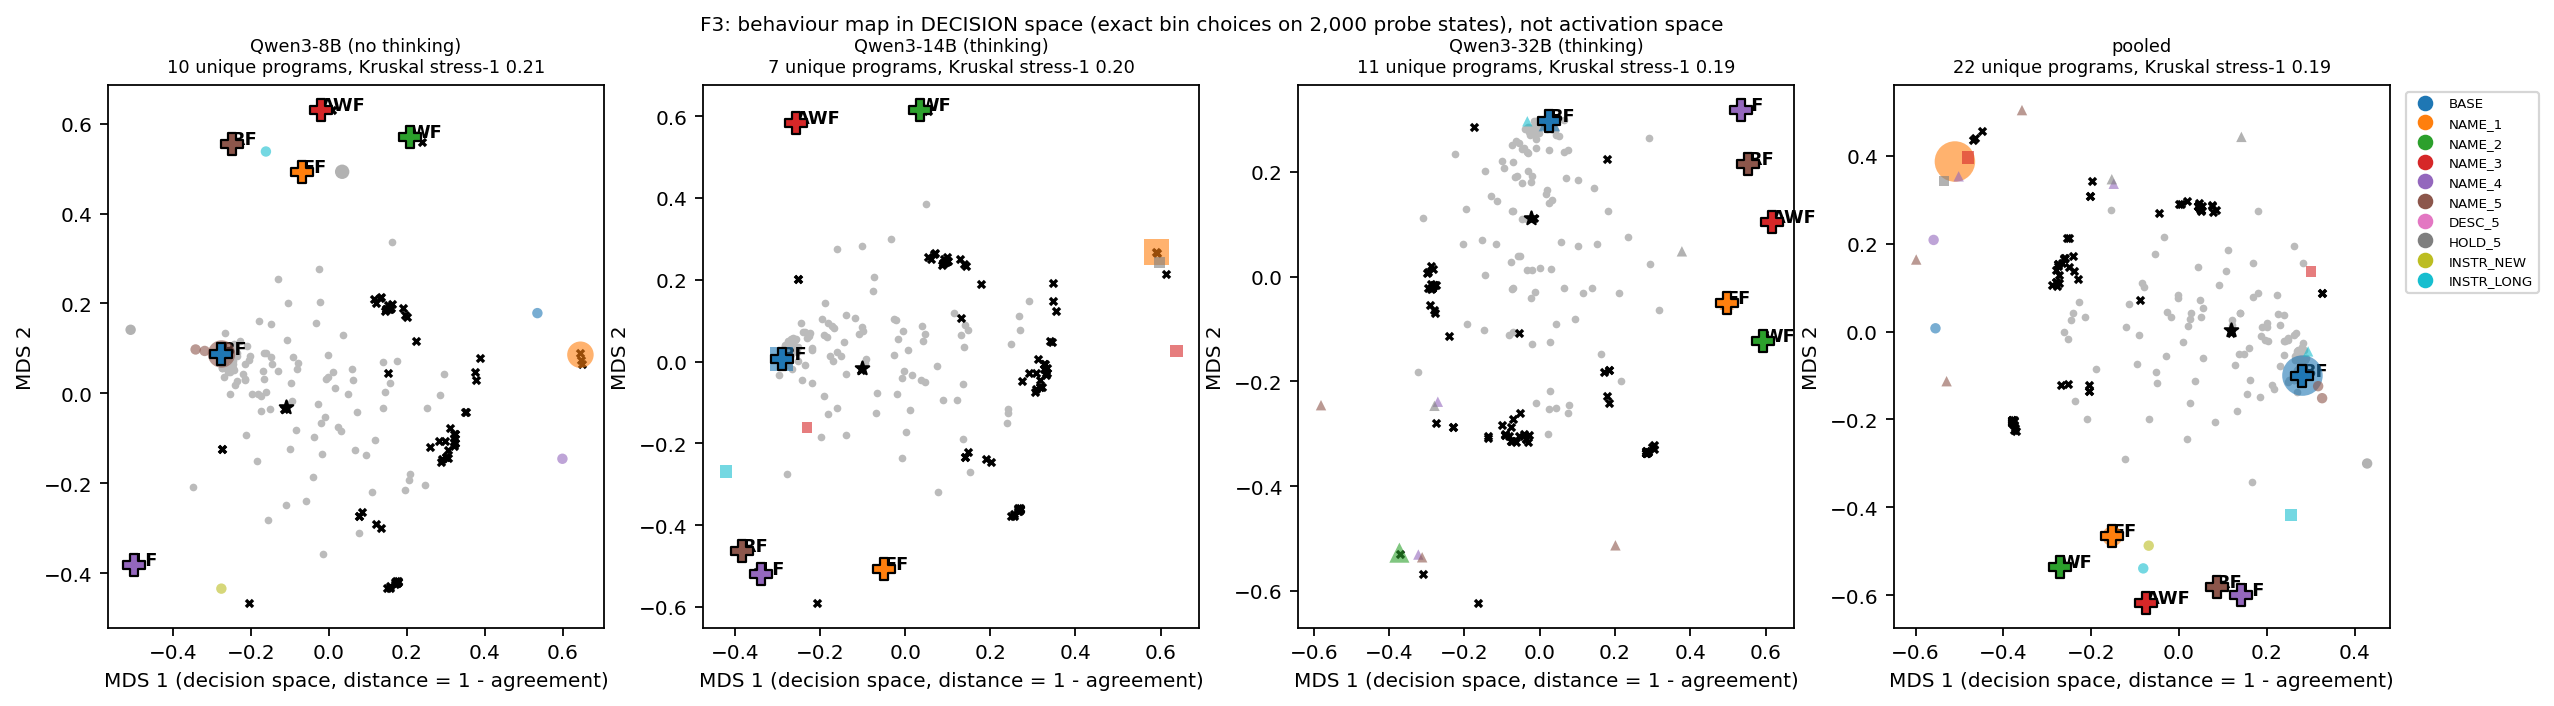

In [58]:
display(Image(filename=str(ROOT / "figures" / "F3_mds_behaviour_map.png")))

### F1, F2: compliance against k and class composition

F1 shows that the two instruments disagree exactly when the mechanistic (red) curve drops below the lexical (blue)
curve. F2 gives the class mix per cell, including how much best fit (blue) remains under each ban.


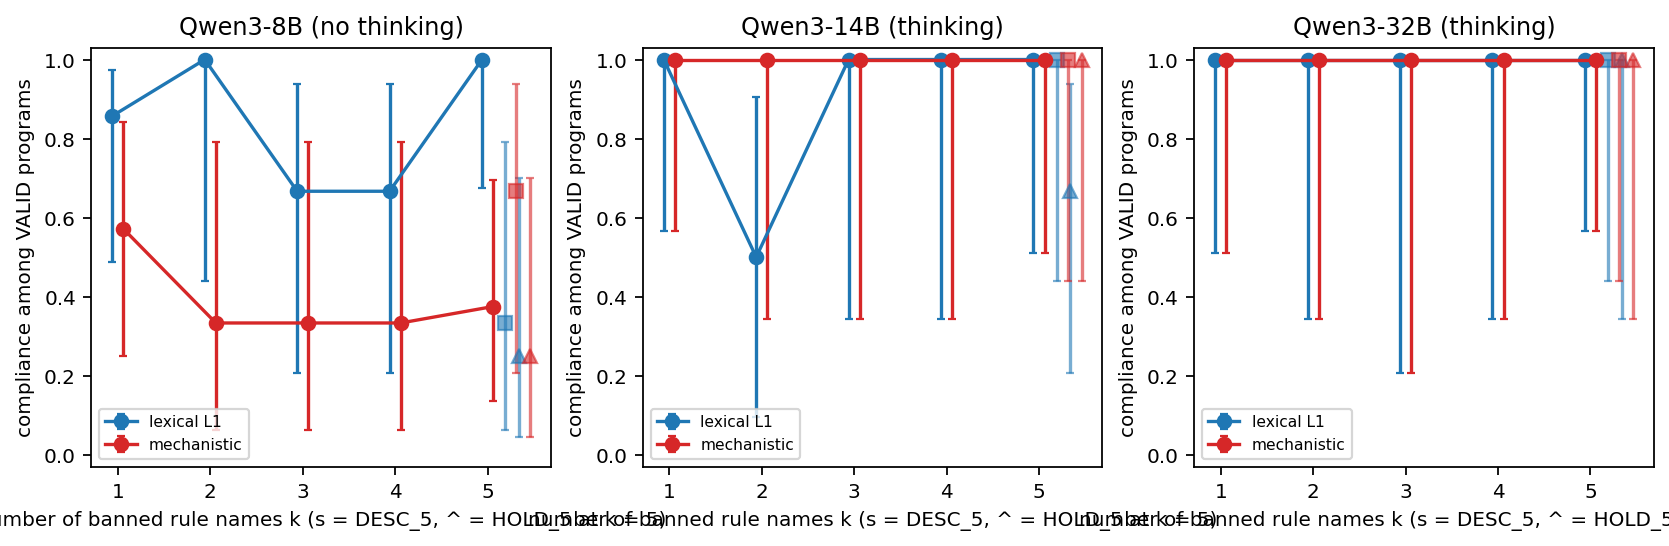

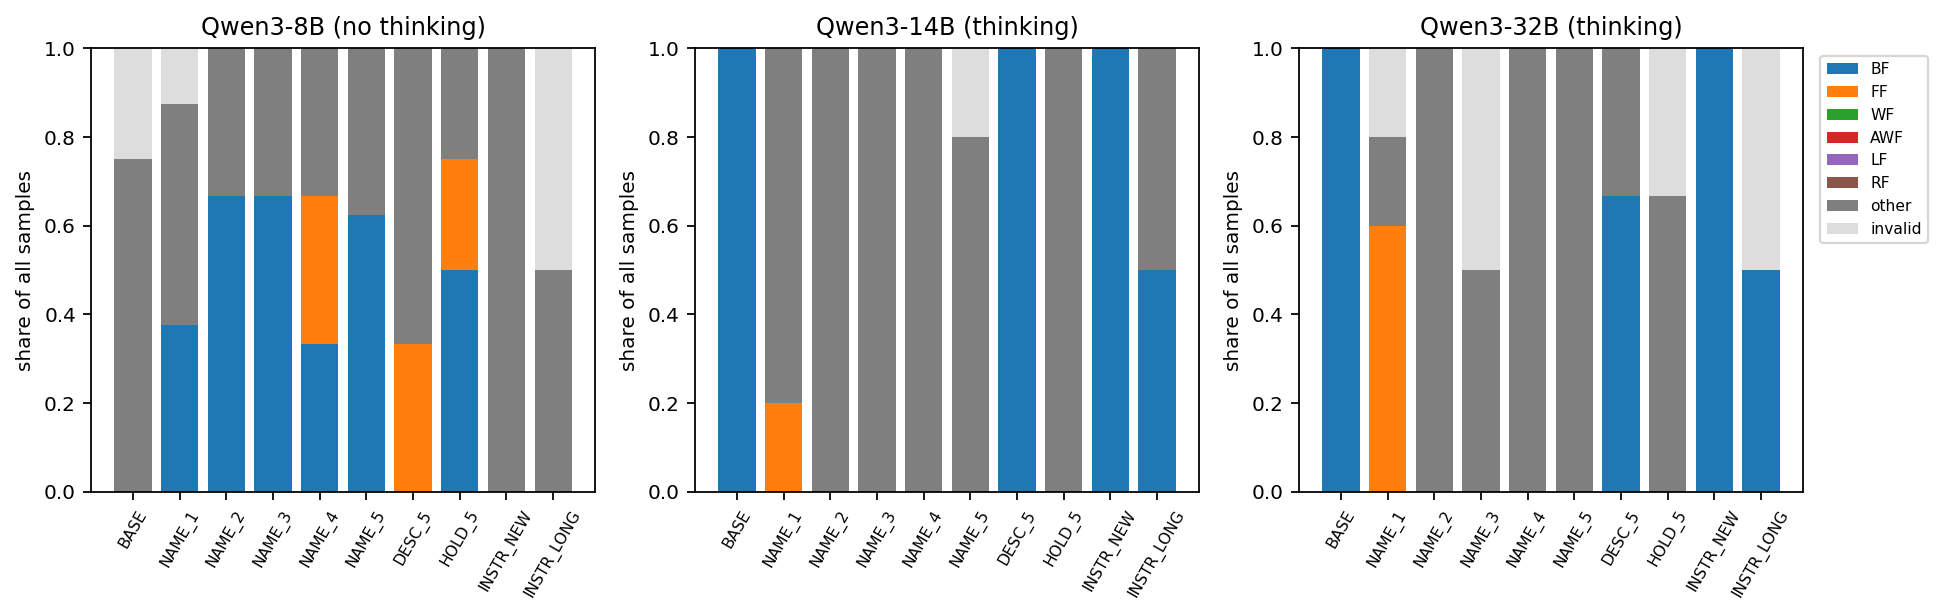

In [59]:
display(Image(filename=str(ROOT / "figures" / "F1_compliance_vs_k.png")))
display(Image(filename=str(ROOT / "figures" / "F2_class_composition.png")))

### F4, F5, F6: instrument heatmap, held-out excess, agreement with the banned rules

F4 shows that the catalogue rules are far apart (pairwise agreement ≤ 0.46), so the 0.95 threshold leaves a wide
margin. F5 is the P3 test: no program lies in the bottom-left "better than 0.8 × best fit" box. F6 shows how close each
program under a ban stays to a banned rule; points at 1.0 are banned rules under a new name or a silent violation.


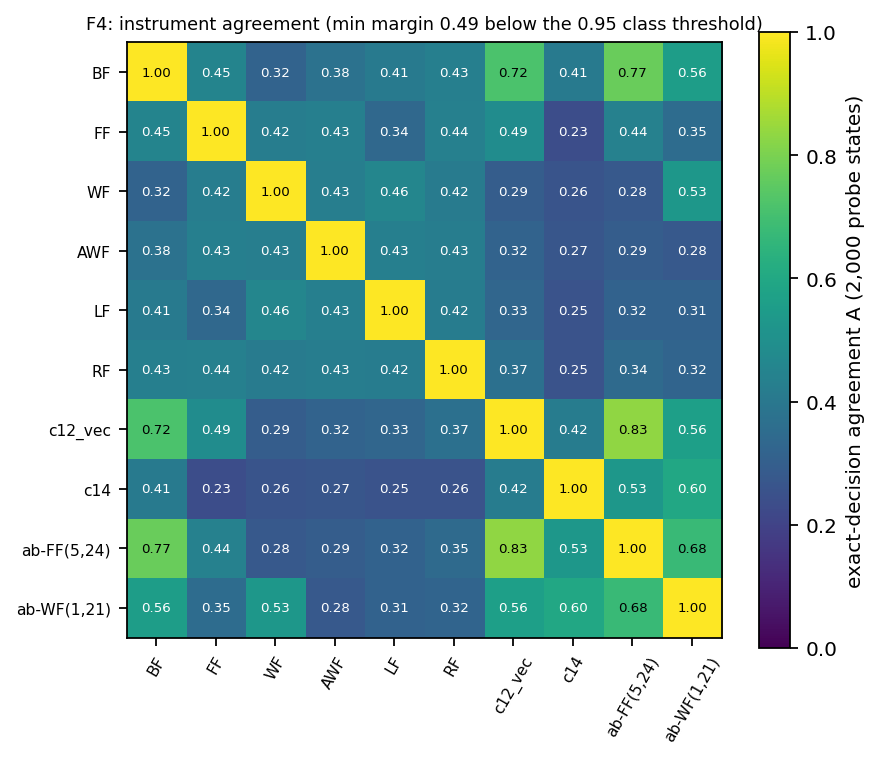

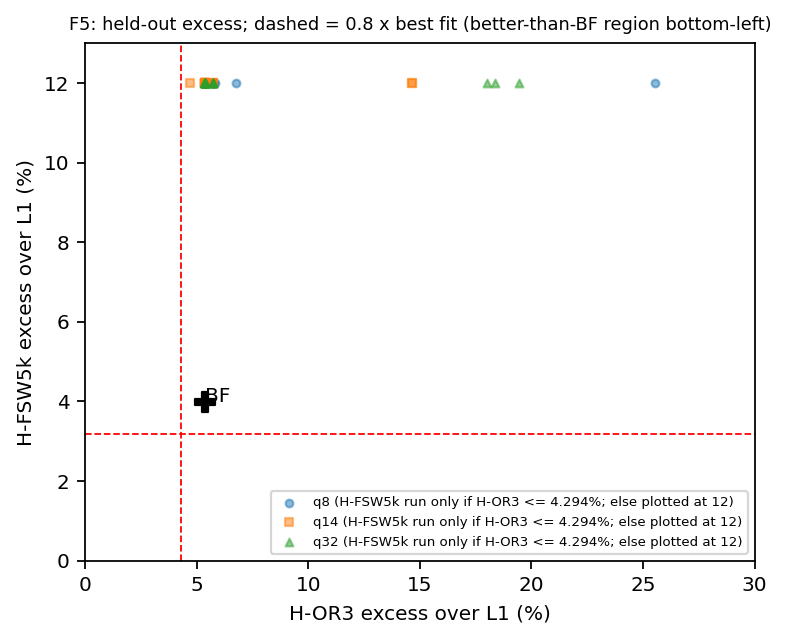

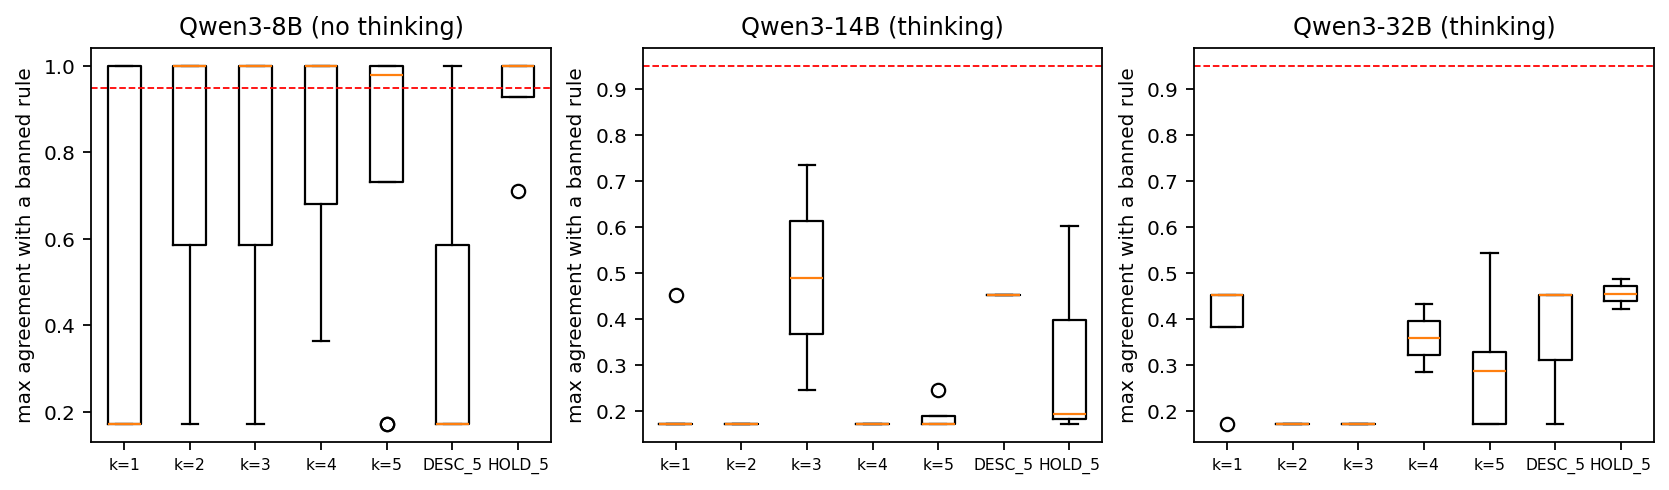

In [60]:
for name in ["F4_instrument_heatmap", "F5_heldout_excess", "F6_max_agree_banned"]:
    display(Image(filename=str(ROOT / "figures" / f"{name}.png")))

## Results: demo subset vs full run

The table puts the demo's re-computed numbers next to the full run's (1,143 samples, from
`mini_demo_data.json → full_run_reference`). The left panel compares lexical and mechanistic compliance at k = 1 and
k = 5. The right panel checks the instrument itself: every re-computed agreement A_c against the value recorded in the
full run (all points should lie on the diagonal).


model                    cell       demo N/VALID  demo L1 demo mech | full N/VALID  full L1 full mech
Qwen3-8B (no thinking)   BASE                4/3     0.67      1.00 |        50/36     0.61      0.69
Qwen3-8B (no thinking)   NAME_1              8/7     0.86      0.57 |        50/41     0.85      0.59
Qwen3-8B (no thinking)   NAME_5              8/8     1.00      0.38 |        50/43     0.91      0.51
Qwen3-8B (no thinking)   HOLD_5              4/4     0.25      0.25 |        50/49     0.63      0.55
Qwen3-8B (no thinking)   INSTR_NEW           2/2     1.00      1.00 |        50/42     0.62      0.50
Qwen3-14B (thinking)     BASE                3/3     1.00      0.00 |        50/50     0.84      0.00
Qwen3-14B (thinking)     NAME_1              5/5     1.00      1.00 |        30/30     0.93      1.00
Qwen3-14B (thinking)     NAME_5              5/4     1.00      1.00 |        30/27     0.96      0.93
Qwen3-14B (thinking)     HOLD_5              3/3     0.67      1.00 |        30/30

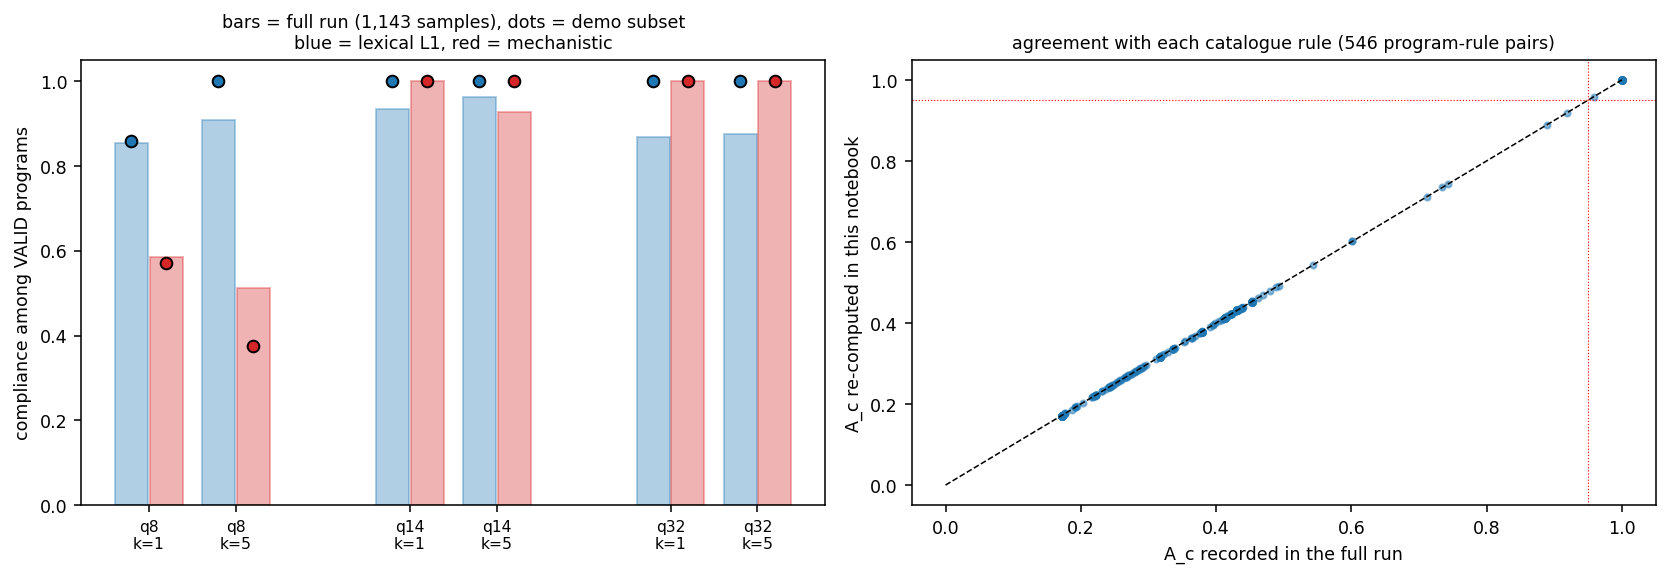

In [61]:
ref = data["full_run_reference"]
cells_demo = read_json(RESULTS / "cells.json")
p1_demo = read_json(RESULTS / "p1.json")["per_model"]
names = {"q8": "Qwen3-8B (no thinking)", "q14": "Qwen3-14B (thinking)", "q32": "Qwen3-32B (thinking)"}

def rate(c, key):
    return None if not c or c[key]["rate"] is None else c[key]["rate"]

print(f"{'model':24s} {'cell':10s} {'demo N/VALID':>12s} {'demo L1':>8s} {'demo mech':>9s} | {'full N/VALID':>12s} {'full L1':>8s} {'full mech':>9s}")
for m in ["q8", "q14", "q32"]:
    for cell in ["BASE", "NAME_1", "NAME_5", "HOLD_5", "INSTR_NEW"]:
        cd, cf = cells_demo.get(f"{m}|{cell}"), ref["cells"].get(f"{m}|{cell}")
        fmt = lambda x: "  -" if x is None else f"{x:.2f}"
        nd = f"{cd['N']}/{cd['VALID']}" if cd else "-"
        print(f"{names[m]:24s} {cell:10s} {nd:>12s} {fmt(rate(cd, 'L1_valid')):>8s} {fmt(rate(cd, 'mech_valid')):>9s} | "
              f"{str(cf['N']) + '/' + str(cf['VALID']):>12s} {fmt(cf['L1_valid']):>8s} {fmt(cf['mech_valid']):>9s}")
print("\nNAME_5 gap L1 - mech (paired Newcombe 95%):")
for m in ["q8", "q14", "q32"]:
    dd, df = p1_demo.get(m, {}).get("d", {}), ref["p1"][m]
    demo = f"{dd['gap']:+.2f} [{dd['paired_newcombe95'][0]:+.2f}, {dd['paired_newcombe95'][1]:+.2f}] (n {dd['n']})" if dd.get("n") else "n/a"
    print(f"  {names[m]:24s} demo {demo:32s} full {df['d_gap']:+.2f} [{df['d_ci'][0]:+.2f}, {df['d_ci'][1]:+.2f}] (n {df['d_n']})")
print("\nINSTR_NEW ('Make a new algorithm.') classed best fit, demo vs full:")
for m in ["q8", "q14", "q32"]:
    cd, cf = cells_demo.get(f"{m}|INSTR_NEW"), ref["cells"][f"{m}|INSTR_NEW"]
    bf_d = f"{cd['class_composition'].get('BF', 0)}/{cd['N']}" if cd else "-"
    print(f"  {names[m]:24s} demo {bf_d:6s} full {cf['class_composition'].get('BF', 0)}/{cf['N']}")
print("\nfull-run verdicts:", ref["verdicts"], "| demo verdicts:", verdicts)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
xs, labels = [], []
for i, m in enumerate(["q8", "q14", "q32"]):
    for j, cell in enumerate(["NAME_1", "NAME_5"]):
        x0 = i * 3 + j
        cd, cf = cells_demo.get(f"{m}|{cell}"), ref["cells"][f"{m}|{cell}"]
        for dx, key, col in [(-0.2, "L1_valid", "#1f77b4"), (0.2, "mech_valid", "#d62728")]:
            ax.bar(x0 + dx, cf[key], width=0.38, color=col, alpha=0.35, edgecolor=col)
            v = rate(cd, key)
            if v is not None:
                ax.plot([x0 + dx], [v], marker="o", color=col, markeredgecolor="k", zorder=3)
        xs.append(x0)
        labels.append(f"{m}\n{cell.replace('NAME_', 'k=')}")
ax.set_xticks(xs)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("compliance among VALID programs")
ax.set_title("bars = full run (1,143 samples), dots = demo subset\nblue = lexical L1, red = mechanistic", fontsize=9)
ax = axes[1]
pts = [(rec_A, rows[ex["row_id"]]["A"][c]) for ex in examples if ex["row_id"] in rows and rows[ex["row_id"]].get("A")
       and ex["recorded"].get("A") for c, rec_A in ex["recorded"]["A"].items()]
if pts:
    P = np.array(pts)
    ax.scatter(P[:, 0], P[:, 1], s=10, alpha=0.5)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.axvline(0.95, color="r", lw=0.6, ls=":")
ax.axhline(0.95, color="r", lw=0.6, ls=":")
ax.set_xlabel("A_c recorded in the full run")
ax.set_ylabel("A_c re-computed in this notebook")
ax.set_title(f"agreement with each catalogue rule ({len(pts)} program-rule pairs)", fontsize=9)
fig.tight_layout()
out = ROOT / "figures" / "demo_vs_full_run.png"   # figures.py switched matplotlib to Agg, so save and show the PNG
fig.savefig(out, dpi=140, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(out)))
